# 4-estimators: position

Read the horn's angle from the pot one control tick at a time, the way a position loop has to, and say what each step between the converter's sample and the angle costs in bias, noise and delay. The steps are a lookup from counts to degrees, a filter, what to do at the converter's carry codes, and whether to carry a term that depends on the direction of motion. Each is graded held out against the camera's tag. The notebook has no capture of its own. It re-reads stage 3's pot-table sitting and the load ladder's holds and takes every constant from the result files of stages 0, 1 and 3.

## Purpose

Stage 3 measured the pot's table over the travel, its drift over the sitting, the converter's missing codes and the play of the train, all as fits over whole segments with one free offset per segment. A position loop has none of that. It reads one sample per tick and has to turn it into an angle before the next one arrives.

- The lookup. Counts to angle as a table indexed by counts, the form a controller reads without a search, its pitch, its size, and what it returns past the data at both ends.
- The held-out grade. The lookup fitted on part of the sitting and scored on the rest, by fold, by clip kind and by pass, with and without each segment's offset, and a budget of what the remaining error is made of.
- The stability inside the sitting. Whether the rest points and the two passes moved over the sitting.
- The filter. The pot's noise per row at rest and in motion, its structure, and a table of candidate filters as noise against delay.
- The carries. Where the converter skips codes, what each estimator reads there against the tag, and whether a mask is worth carrying.
- The direction term. Whether a fixed offset by direction of motion holds outside the clips it was fitted on, through the reversals and at rest.
- What stage 5 reads. One table of the bias, the noise per tick, the delay per filter, the valid range and the start-up, then the gaps with the capture that would close each.

## Procedure

No sitting ran for this notebook. Every estimator is a pure function in `oscnb.position`, run down the rows of a stage 3 sweep, one row per PWM period at the control tick, with only the rows before it. The truth it is graded against, the camera's tag, is offline and may look ahead. The README's rules of the desk hold here. An estimator is causal, the arithmetic is float, a grade is held out with its split named, constants come through the chain, and a threshold comes from the servo's own noise.

The method follows two analysis notes that were reviewed and reproduced before this notebook was written, one for the lookup and its grade, one for the rows.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`.

- `pot-table/`, stage 3's camera sitting `servo-camera-9`, with the blocks `pass-open-9`, `crawl-9`, `reversal-9`, `steps-9` and `pass-close-9`, one sweep folder per chain under `chains/`, one phone clip per block with the tags' corners, the STAT lamp's level and the clapper's log. `oscnb.potframes.load` runs stage 3's whole pipeline over it, from the clocks to the frames and the rest points.
- `load/ladder-1/`, the load sitting's ladder of holds under torque, one sweep folder per hold, each streamed as short windows.

Each sweep folder holds `sweep.csv`, one row per control tick, `segments.csv` with each segment's host start time, and `meta.json`, whose sense block is checked against the board's registry entry on load.

The libraries, then the pair and its folders.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.ndimage import median_filter, uniform_filter1d
from scipy.signal import welch

from oscnb import boards, figures, potframes, results, servos, tel
from oscnb import position as pe
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

pd.set_option("display.width", 200)    # the printed tables run wide

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, limits
BOARD = boards.BOARDS[boards.DEFAULT]   # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD.key}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
STAGE, EXPERIMENT = "4-estimators", "position"   # where the result goes
print(SERVO.key, "on", BOARD.key, "from", results.rel(PAIR_DIR))
print(f"control tick {BOARD.tick_hz} rows/s on the board's registry entry")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D
control tick 20000 rows/s on the board's registry entry


## 1. The rig, the data and the constants

### The constants, through the chain

Stage 0's camera-tag result gives the tag's grade, the floor of every comparison of the pot against the tag. Stage 1's pos-coupling result gives the pattern the board puts on the pot channel, measured with a resistor divider in the pot's place. Stage 3's pot-table result gives the pot's scale through mid travel, the knot spacing of its table, the end slopes, the guards' span, the drift and the play, and stage 3's compensation result its grade of the pot through that table.

In [3]:
def val(d, key):
    """A result quantity's value."""
    return d[key]["value"]


TAG = results.read("0-instruments", "camera-tag")
POS1 = results.read("1-board", "pos-coupling", pair=BOARD.key)
POT3 = results.read("3-servo", "pot-table", pair=PAIR)
COMP3 = results.read("3-servo", "compensation", pair=PAIR)
TAG_GRADE_DEG = val(TAG, "angle_error_deg")     # deg, the tag at 90 %
STAGE1_PP = val(POS1, "pos_frame_pp_rest_counts")   # counts, on a divider
STAGE1_FREE = val(POS1["pos_rest_sd_pattern_removed_counts"], "capture_1")
SCALE = val(POT3, "pot_scale_counts_per_deg")   # counts/deg, mid travel
KNOT3 = val(POT3, "table_knot_deg")             # deg, stage 3's knots
END3 = (val(POT3, "pot_scale_low_end"),         # counts/deg at the ends
        val(POT3, "pot_scale_high_end"))
SPAN3 = val(POT3, "guard_span_deg")             # deg, guard to guard
DRIFT3 = val(POT3, "drift_trend_counts_per_10min")
PLAY3 = POT3["lash_play_deg"]                   # deg, the play's bracket
POT_SD3 = val(POT3, "pot_rest_sd_counts")       # counts, at rest
CODE2047_3 = val(POT3, "adc_code_2047_deg")     # deg, horn on code 2047
WIDE3 = {int(c): v["value"] for c, v in POT3["adc_wide_code_deg"].items()}
TEXTURE3 = val(POT3, "table_fine_rms_counts")   # counts rms, fine texture
PUSH3 = val(POT3, "pot_force_excess_deg")       # deg, the pot under a push
GRADE3 = val(COMP3, "position_resid_rms_deg")   # deg, stage 3's grade
DIR3 = COMP3["position_resid_by_dir_crawl_deg"]  # deg, the crawl by dir
print(f"stage 0: tag grade {TAG_GRADE_DEG:.2f} deg")
print(f"stage 1: pattern {STAGE1_PP:.3f} counts pp on a divider, "
      f"{STAGE1_FREE:.2f} counts sd with it removed")
print(f"stage 3: scale {SCALE:.3f} counts/deg, knots {KNOT3:g} deg, ends "
      f"{END3[0]:.2f} and {END3[1]:.2f} counts/deg, guards {SPAN3:.2f} "
      "deg apart")
print(f"stage 3: drift trend {DRIFT3:+.2f} counts per 10 min, play "
      f"{PLAY3['lo']:.2f} to {PLAY3['hi']:.2f} deg, pot at rest "
      f"{POT_SD3:.3f} counts sd, code 2047 {CODE2047_3:.2f} deg, texture "
      f"{TEXTURE3:.1f} counts rms, under a push {PUSH3:.2f} deg")
print(f"stage 3: pot through its table {GRADE3:.3f} deg rms, crawl by "
      f"direction {val(DIR3, '+1'):+.3f} / {val(DIR3, '-1'):+.3f} deg")

stage 0: tag grade 0.16 deg
stage 1: pattern 3.025 counts pp on a divider, 0.66 counts sd with it removed
stage 3: scale 18.913 counts/deg, knots 1.5 deg, ends 22.35 and 22.90 counts/deg, guards 154.12 deg apart
stage 3: drift trend -0.82 counts per 10 min, play 0.39 to 1.12 deg, pot at rest 0.965 counts sd, code 2047 0.71 deg, texture 6.0 counts rms, under a push 1.02 deg
stage 3: pot through its table 0.400 deg rms, crawl by direction +0.166 / -0.177 deg


### Stage 3's pot-table sitting

`potframes.load` runs stage 3's pipeline over the sitting. It builds the chains and the clip each belongs to, the clocks from the clapper's flashes, every frame's tag angle on the host clock with the pot at its time, the rest points where the servo stood still, the stamps' lead per group of segments, and the moving frames the table is fitted on. Its tables are the ones stage 3 built, so this notebook starts where stage 3's table fit started.

In [4]:
PF = potframes.load(PAIR_DIR)           # stage 3's pipeline, every step
LO, HI = PF.lo_deg, PF.hi_deg           # deg, the moving frames' span
GUARDS = PF.guards                      # counts, where the drives start
print(f"{len(PF.chains)} chains in {len(PF.clips)} clips: "
      + ", ".join(PF.clips))
print(f"{len(PF.frames)} frames in segments, {len(PF.static)} rest points;"
      f" {len(PF.moving)} moving frames in {PF.moving['sid'].nunique()} "
      f"segments over {LO:.2f} to {HI:.2f} deg, {len(PF.rest)} rest points"
      " inside it")
print(f"guards {GUARDS[0]:.0f} and {GUARDS[1]:.0f} counts, rail "
      f"{PF.rail_v} V, {len(PF.lead)} lead groups")

21 chains in 10 clips: pass-open, crawl-0-0, crawl-0-1, crawl-1-0, crawl-1-1, crawl-2-0, crawl-2-1, reversal, steps, pass-close
13279 frames in segments, 97 rest points; 6001 moving frames in 50 segments over -163.20 to -28.65 deg, 75 rest points inside it
guards 414 and 3460 counts, rail 5.0 V, 42 lead groups


The sitting gives 21 chains in 10 clips, one chain for each pass. Of its 13279 frames inside streamed segments, 6001 are the moving frames stage 3 fitted its table on, in 50 segments over -163.20 to -28.65 degrees of tag angle, with 75 of the 97 rest points inside that range.

Stage 3's table of record, a cubic B-spline in the tag angle at its own knot spacing, refitted from the same frames. The rows part of this notebook reads the angle through it, inverted on a fine grid of angles, and the lookup part builds its own table indexed by counts beside it.

In [5]:
_, STAGE3_COUNTS = PF.fit_table(KNOT3)  # deg -> counts, stage 3's table
LOOKUP3 = pe.make_lookup(STAGE3_COUNTS, LO, HI)   # counts -> deg
ends3 = STAGE3_COUNTS(np.array([LO, HI]))
grid3 = STAGE3_COUNTS(np.linspace(LO, HI, 2000))
print("inverted on a 0.01 deg grid")
print(f"stage 3's table: {ends3[0]:.1f} to {ends3[1]:.1f} counts over "
      f"{LO:.2f} to {HI:.2f} deg, increasing everywhere: "
      f"{bool(np.all(np.diff(grid3) > 0))}")

inverted on a 0.01 deg grid
stage 3's table: 577.8 to 3195.7 counts over -163.20 to -28.65 deg, increasing everywhere: True


### The chains, their kinds and the folds

A chain's kind is its clip's first word, one of pass, crawl, reversal or steps. The two folds of every held-out grade are the parity of a chain's rank inside its kind, in the order the chains ran. Each fold then holds one pass, one reversal chain, one steps chain and half the crawls. The parity of the plain chain number would put both passes in one fold, and the passes carry most of the moving frames in the outer ten degrees at each end, so a split by chain number would grade the ends on extrapolation. For the crawl chains the two rules agree, since the crawl block numbers its chains from 0 in order.

In [6]:
def kind_of(clip):
    """A clip's kind: pass, crawl, reversal or steps."""
    return clip.split("-")[0]


CHAIN_NO, FOLD, seen = {}, {}, {}
for i, (clip, k) in enumerate(zip(PF.chains["clip"], PF.chains["k"])):
    kind = kind_of(clip)
    CHAIN_NO[(clip, k)] = i                 # the chain's row in the table
    FOLD[(clip, k)] = seen.get(kind, 0) % 2   # parity of its rank in kind
    seen[kind] = seen.get(kind, 0) + 1


def with_folds(t):
    """A copy of a frame or rest table with chain, kind_clip and fold."""
    t = t.copy()
    key = list(zip(t["clip"], t["k"]))
    t["chain"] = [CHAIN_NO[x] for x in key]
    t["kind_clip"] = [kind_of(c) for c in t["clip"]]
    t["fold"] = [FOLD[x] for x in key]
    return t


M, R = with_folds(PF.moving), with_folds(PF.rest)     # the fit's inputs
STATIC, FRAMES = with_folds(PF.static), with_folds(PF.frames)
print("chains by fold", M.groupby("fold")["chain"].nunique().to_dict(),
      "rest points by fold", R.groupby("fold").size().to_dict())
show(PF.chains.assign(fold=[FOLD[x] for x in zip(PF.chains["clip"],
                                                 PF.chains["k"])])
     [["clip", "k", "schedule", "fold"]], n=None)

chains by fold {0: 11, 1: 10} rest points by fold {0: 39, 1: 36}


,clip,k,schedule,fold
0,pass-open,0,"20@915,coast:300",0
1,crawl-0-0,0,"30@150,then:6@2135,coast:300",0
2,crawl-0-0,1,"30@150,then:7@1830,coast:300",1
3,crawl-0-0,2,"30@150,then:8@1601,coast:300",0
4,crawl-0-1,3,"30@150,then:9@1423,coast:300",1
5,crawl-0-1,4,"30@150,then:11@1164,coast:300",0
6,crawl-1-0,5,"30@150,then:6@1491,coast:300",1
7,crawl-1-0,6,"30@150,then:7@1278,coast:300",0
8,crawl-1-0,7,"30@150,then:8@1118,coast:300",1
9,crawl-1-1,8,"30@150,then:9@994,coast:300",0


Fold 0 holds 11 chains and 39 rest points, fold 1 holds 10 chains and 36.

### The rows

Every chain's rows, one per control tick. `PotFrames.rows` adds `host`, the segment's start stamp plus the tick over the tick rate, and `host_cam`, the same shifted by the lead stage 3 read for the chain's direction group, which puts the rows on the camera's clock. The rows part works on plain arrays per chain. The tick is read from the rows themselves, the median spacing of the baseline's host times.

In [7]:
CHAINS = [(c, k) for c, (_, _, ks) in PF.clips.items() for k in ks]
ROWS = {ck: PF.rows(*ck)[0] for ck in CHAINS}   # rows per chain


def arrays(df):
    """One chain's rows as arrays: the columns the row estimators read."""
    return {"seg": df["seg"].to_numpy(), "tick": df["tick"].to_numpy(),
            "pos": df["pos"].to_numpy(float),
            "duty": df["cmd_duty_q15"].to_numpy(float),
            "dir": df["dir"].to_numpy(float),
            "host": df["host"].to_numpy(), "cam": df["host_cam"].to_numpy()}


def tick_s(c):
    """s per row: the median spacing of the baseline's host stamps."""
    s = c["seg"] == 0
    return float(np.median(np.diff(c["host"][s])))


CH = {ck: arrays(df) for ck, df in ROWS.items()}
DT = tick_s(CH[CHAINS[-1]])             # s per row, the control tick
gaps = []           # ms between one driven segment's rows and the next's
for c in CH.values():
    cut = np.flatnonzero((np.diff(c["seg"]) != 0) & (c["seg"][:-1] > 0))
    gaps += list((c["host"][cut + 1] - c["host"][cut]) * 1e3)
print(f"{len(CH)} chains, {sum(len(c['pos']) for c in CH.values())} rows, "
      f"tick {DT * 1e6:.2f} us")
gaps = np.array(gaps)
short, seek = gaps[gaps < 100], gaps[gaps >= 100]   # ms, a seek is longer
print(f"between driven segments the stream stops for {short.min():.1f} to "
      f"{short.max():.1f} ms ({len(short)} gaps), and for {seek.min():.0f} "
      f"to {seek.max():.0f} ms where the servo seeks ({len(seek)})")

21 chains, 1563800 rows, tick 50.07 us
between driven segments the stream stops for 2.0 to 12.1 ms (80 gaps), and for 3050 to 3543 ms where the servo seeks (21)


The 21 chains hold 1563800 rows at 50.07 microseconds a row. Between two driven segments of a chain no rows are streamed for a few milliseconds, and for seconds where the servo seeks to the next start, the ranges printed above. A filter that runs across a segment boundary runs across that gap.

### The load ladder's holds

The load sitting held the arm at each duty of a ladder and streamed short windows of rows. A window is kept as a rest window when it is long enough, the duty is on in every row, and its 10 ms mean stays within a count and a half, so the pot stood still under torque. The settings are printed with the result. These are the only rows here with the bridge driving and the shaft at rest, and they come from a different sitting.

In [8]:
LADDER_DIR = PAIR_DIR / "load" / "ladder-1"
STILL_COUNTS = 1.5      # counts, the 10 ms mean's range of a still window
LADDER = pd.read_csv(LADDER_DIR / "ladder.csv")
HOLDS = []              # (duty %, the window's pos rows)
for _, r in LADDER.iterrows():
    folder = LADDER_DIR / r["folder"]
    df, meta = tel.load(folder)
    potframes.board_of(meta, str(results.rel(folder)))   # sense checked
    for s, g in df.groupby("seg"):
        p = g["pos"].to_numpy(float)
        mean10 = uniform_filter1d(p, 200)[100:-100]   # 10 ms mean
        if (len(p) >= 1500 and np.all(g["cmd_duty_q15"] != 0)
                and np.ptp(mean10) < STILL_COUNTS):
            HOLDS.append((r["duty_pct"], p))
duties = sorted({d for d, _ in HOLDS})
print(f"kept: 1500 rows or more, the duty on in every row, the 10 ms mean "
      f"within {STILL_COUNTS} counts")
print(f"{len(LADDER)} holds, {len(HOLDS)} still windows of "
      f"{len(HOLDS[0][1])} rows ({len(HOLDS[0][1]) * DT * 1e3:.0f} ms), "
      f"duty {min(duties):.0f} to {max(duties):.0f} %")

kept: 1500 rows or more, the duty on in every row, the 10 ms mean within 1.5 counts
45 holds, 55 still windows of 2000 rows (100 ms), duty 4 to 54 %


The 45 holds give 55 still windows of 2000 rows, 100 ms each, at 4 to 54 % duty.

## 2. The lookup: counts to angle

### The model and the two forms

The table is stage 3's model with the roles swapped where the form asks for it. A lookup is linear between knots. In the counts form the knots sit on multiples of a pitch in counts and hold angles in degrees, fitted as the tag angle on the pot, $\theta = T(\mathrm{pos}) + c_s$, so the controller's index is the counts shifted by the pitch's power of two and no search is needed. In the angle form the knots are uniform in degrees and hold counts, fitted as $\mathrm{pos} = T(\theta) + c_s$ and read backwards, which needs a search. Either way $c_s$ is one free offset per moving segment $s$ and the rest points carry none, so they set the level. A second-difference ridge conditions the knots few frames reach.

An error is the lookup's angle less the tag in degrees, or the pot less the table's counts at the tag's angle in counts. Both are positive when the pot reads ahead of the tag, toward higher angles.

The pitches tried, with the two ridges. The first only conditions, the second smooths, which the finer pitches need to stay monotone.

In [9]:
PITCHES = {"counts": [8, 16, 32, 64, 128, 256],     # counts per knot
           "angle": [0.5, 1, 1.5, 2, 3, 5, 10]}      # deg per knot
RIDGES = (0.1, 1.0)     # the conditioning ridge, and a smoothing one
PITCH = 32              # counts, the pitch of record (chosen below)
crawl = M[M["kind_clip"] == "crawl"]
INT = (crawl["pos"].min(), crawl["pos"].max())   # the crawl's coverage
print(f"counts {PITCHES['counts']}, deg {PITCHES['angle']}, ridges "
      f"{RIDGES}; the crawl covers {INT[0]:.0f} to {INT[1]:.0f} counts")
print(f"a ridge of {RIDGES[0]} weighs one unit of knot curvature as "
      f"{RIDGES[0] ** 2:.2f} of a frame's squared residual")


def rms(x):
    """Root mean square, nan for an empty set."""
    x = np.asarray(x, float)
    return float(np.sqrt(np.mean(x ** 2))) if len(x) else float("nan")


def seg_out(e, sid):
    """e less its mean over each segment: each segment's offset out."""
    return e - pd.Series(e).groupby(np.asarray(sid)).transform(
        "mean").to_numpy()

counts [8, 16, 32, 64, 128, 256], deg [0.5, 1, 1.5, 2, 3, 5, 10], ridges (0.1, 1.0); the crawl covers 790 to 2952 counts
a ridge of 0.1 weighs one unit of knot curvature as 0.01 of a frame's squared residual


### The two-fold score

A lookup is fitted on one fold and scored on the other, each scored segment with its own offset taken out, and the two halves are pooled. The held-out rest points are scored with no offset out, so they grade the level as well as the shape.

In [10]:
def two_fold(fit_score, m=M, r=R):
    """(deg, counts on held-out moving frames, offsets out; deg, counts
    on held-out rest points), both folds pooled. fit_score(train moving,
    train rest, test moving, test rest) gives the raw errors."""
    md_, mc, rd, rc = [], [], [], []
    for p in (0, 1):
        tm, tr = m[m["fold"] != p], r[r["fold"] != p]   # fit on one fold
        sm, sr = m[m["fold"] == p], r[r["fold"] == p]   # score the other
        (a, b), (c, d) = fit_score(tm, tr, sm, sr)
        md_.append(seg_out(a, sm["sid"]))
        mc.append(seg_out(b, sm["sid"]))
        rd.append(c)
        rc.append(d)
    return [np.concatenate(v) for v in (md_, mc, rd, rc)]


# the held-out frames inside the crawl's coverage, in two_fold's order
INTM = np.concatenate([((M[M["fold"] == q]["pos"] > INT[0])
                        & (M[M["fold"] == q]["pos"] < INT[1])).to_numpy()
                       for q in (0, 1)])

In [11]:
def score(kind, p, ridge):
    """One form and pitch: its row of the scan and the held-out errors."""
    lk, off = pe.build(M, R, p, kind, ridge)    # fitted on everything
    ed, ec = pe.errors(lk, M["pos"], M["image_deg"])
    if kind == "counts":    # offsets in deg: out in deg, counts by segment
        ins_d = ed + M["sid"].map(off).to_numpy()
        ins_c = seg_out(ec, M["sid"])
    else:                   # offsets in counts
        ins_c = ec - M["sid"].map(off).to_numpy()
        ins_d = seg_out(ed, M["sid"])

    def fs(tm, tr, sm, sr):
        l2, _ = pe.build(tm, tr, p, kind, ridge)
        return (pe.errors(l2, sm["pos"], sm["image_deg"]),
                pe.errors(l2, sr["pos"], sr["image_deg"]))

    cd, cc, rd, rc = two_fold(fs)
    sc = lk.scale()                     # mean counts/deg over the table
    g = GUARDS
    if kind == "counts":                # entries guard to guard
        full = int(np.ceil(g[1] / p) - np.floor(g[0] / p) + 1)
    else:
        full = int(np.ceil((lk.angle(g[1]) - lk.angle(g[0])) / p) + 1)
    row = dict(ridge=ridge, form=kind, pitch=p,
               pitch_deg=p / sc if kind == "counts" else p,
               pitch_counts=p if kind == "counts" else p * sc,
               entries=lk.entries, entries_guard=full,
               monotone=lk.monotone, ins_counts=rms(ins_c),
               ins_deg=rms(ins_d), cv_counts=rms(cc), cv_deg=rms(cd),
               cv_int_counts=rms(cc[INTM]), n=len(cc), n_int=int(INTM.sum()),
               cv_rest_counts=rms(rc), cv_rest_deg=rms(rd), n_rest=len(rc))
    return row, (cc, cd)

In [12]:
scan, KEEP = [], {}         # the scan's rows; held-out errors by fit
for ridge in RIDGES:
    for kind, pitches in PITCHES.items():
        for p in pitches:
            row, KEEP[(ridge, kind, p)] = score(kind, p, ridge)
            scan.append(row)
SCAN = pd.DataFrame(scan)
plain = SCAN[SCAN["ridge"] < 1]         # the conditioning ridge
smooth = SCAN[SCAN["ridge"] == 1.0][["form", "pitch", "cv_counts",
                                     "cv_deg", "monotone"]]
TABLE_Q1 = plain.merge(smooth, on=["form", "pitch"], suffixes=("", "_r1"))
print(f"n {int(SCAN['n'].iloc[0])} held-out frames "
      f"({int(SCAN['n_int'].iloc[0])} inside the crawl's coverage), "
      f"{int(SCAN['n_rest'].iloc[0])} held-out rest points")
show(TABLE_Q1[["form", "pitch", "pitch_deg", "entries", "entries_guard",
               "ins_counts", "cv_counts", "cv_int_counts", "cv_deg",
               "cv_rest_counts", "monotone", "cv_counts_r1", "cv_deg_r1",
               "monotone_r1"]], n=None)

n 6001 held-out frames (5927 inside the crawl's coverage), 75 held-out rest points


,form,pitch,pitch_deg,entries,entries_guard,ins_counts,cv_counts,cv_int_counts,cv_deg,cv_rest_counts,monotone,cv_counts_r1,cv_deg_r1,monotone_r1
0,counts,8.000,0.411,326,383,3.341,3.622,3.485,0.149,3.732,False,3.538,0.148,True
1,counts,16.000,0.821,164,193,3.306,3.634,3.433,0.163,3.979,True,3.414,0.141,True
2,counts,32.000,1.640,83,98,3.305,3.457,3.410,0.147,3.239,True,3.422,0.150,True
3,counts,64.000,3.274,42,50,3.636,3.784,3.721,0.186,4.160,True,3.769,0.188,True
4,counts,128.000,6.497,22,26,4.368,4.445,4.436,0.238,4.982,True,4.556,0.241,True
5,counts,256.000,12.984,12,14,6.307,6.426,6.384,0.337,7.468,True,6.428,0.337,True
6,angle,0.500,0.500,271,303,2.775,3.350,3.165,0.187,4.043,True,3.202,0.169,True
7,angle,1.000,1.000,137,152,2.806,3.276,3.124,0.178,3.843,True,3.152,0.165,True
8,angle,1.500,1.500,91,103,2.888,3.259,3.137,0.174,3.924,True,3.201,0.169,True
9,angle,2.000,2.000,69,77,3.002,3.240,3.187,0.170,3.686,True,3.293,0.174,True


`entries` counts the knots over the data's span and `entries_guard` from guard to guard. `ins_` is in-sample, `cv_` two-fold, `cv_int_` the two-fold inside the crawl's coverage, `cv_rest_` the held-out rest points, and `_r1` the same fit smoothed with ridge 1.

The anchor. Stage 3's own spline basis at its knot spacing, with a ridge of 1 on its second difference, fitted and scored in these folds, gives the number stage 3's spline would score here.

In [13]:
def fit_spline(tm, tr):
    """Stage 3's basis with a ridge of 1 on the second difference."""
    def B(th):
        return potframes.basis(np.asarray(th, float), KNOT3, LO, HI)
    sids, inv = np.unique(tm["sid"], return_inverse=True)
    Bm, Br = B(tm["image_deg"]), B(tr["image_deg"])
    K = Bm.shape[1]
    A = np.zeros((len(tm) + len(tr), K + len(sids)))
    A[:len(tm), :K] = Bm
    A[np.arange(len(tm)), K + inv] = 1      # one offset per segment
    A[len(tm):, :K] = Br                    # rest points, no offset
    D = np.zeros((K - 2, A.shape[1]))
    j = np.arange(K - 2)
    D[j, j], D[j, j + 1], D[j, j + 2] = 1, -2, 1
    y = np.r_[tm["pos"], tr["pos"], np.zeros(K - 2)]
    return np.linalg.lstsq(np.vstack([A, D]), y, rcond=None)[0][:K], B


def fs_spline(tm, tr, sm, sr):
    c, B = fit_spline(tm, tr)
    e = sm["pos"].to_numpy() - B(sm["image_deg"]) @ c
    e2 = sr["pos"].to_numpy() - B(sr["image_deg"]) @ c
    return (e, e), (e2, e2)


_, cc, _, rc = two_fold(fs_spline)
print(f"stage 3's spline in these folds: two-fold {rms(cc):.3f} counts, "
      f"{rms(cc[INTM]):.3f} inside the crawl's coverage, rest points "
      f"{rms(rc):.2f} counts (n {len(rc)})")

stage 3's spline in these folds: two-fold 3.167 counts, 3.121 inside the crawl's coverage, rest points 3.74 counts (n 75)


Stage 3's spline, refitted and scored in these folds, gives 3.167 counts, 3.121 inside the crawl's coverage. It is a fit of counts on the angle, like the angle form, which scores lower in counts than the counts form all through the scan above. Stage 3's own two-fold split the chains by a different rule, taken up with the discrepancies at the end.

### Is a difference real

Two fits score the same frames, so their difference is paired. The statistic is the mean over frames of one fit's squared residual less the other's, and its standard error comes from 2000 bootstrap draws over the 50 segments, since frames inside one segment are not independent. z is the difference over its standard error.

In [14]:
sid_all = np.concatenate([M[M["fold"] == q]["sid"].to_numpy()
                          for q in (0, 1)])     # two_fold's frame order
US, INV = np.unique(sid_all, return_inverse=True)
rng = np.random.default_rng(0)          # seeded: the same draws every run
PAIRED = []


def paired(a, b, label, unit):
    """Mean of a^2 - b^2 and its bootstrap se over segments."""
    d = a ** 2 - b ** 2
    tot, cnt = np.bincount(INV, d), np.bincount(INV)
    bs = [tot[i].sum() / cnt[i].sum() for i in
          (rng.integers(0, len(US), len(US)) for _ in range(2000))]
    PAIRED.append(dict(pair=label, unit=unit, rms_a=rms(a), rms_b=rms(b),
                       d_ms=d.mean(), se=np.std(bs),
                       z=d.mean() / np.std(bs), n_seg=len(US)))


for a, b in (((1.0, "counts", 8), (1.0, "counts", 16)),
             ((1.0, "counts", 16), (0.1, "counts", 32)),
             ((0.1, "counts", 16), (0.1, "counts", 32)),
             ((0.1, "counts", 64), (0.1, "counts", 32)),
             ((0.1, "counts", 128), (0.1, "counts", 64)),
             ((0.1, "angle", 1.5), (0.1, "counts", 32)),
             ((0.1, "angle", 1.0), (0.1, "counts", 32)),
             ((1.0, "counts", 32), (0.1, "counts", 32))):
    for unit, j in (("counts", 0), ("deg", 1)):
        paired(KEEP[a][j], KEEP[b][j], f"{a[1]} {a[2]:g} ridge {a[0]:g} "
               f"vs {b[1]} {b[2]:g} ridge {b[0]:g}", unit)
PAIRED = pd.DataFrame(PAIRED)
show(PAIRED[["pair", "unit", "rms_a", "rms_b", "z", "n_seg"]], n=None)

,pair,unit,rms_a,rms_b,z,n_seg
0,counts 8 ridge 1 vs counts 16 ridge 1,counts,3.538,3.414,1.882,50
1,counts 8 ridge 1 vs counts 16 ridge 1,deg,0.148,0.141,0.761,50
2,counts 16 ridge 1 vs counts 32 ridge 0.1,counts,3.414,3.457,-1.115,50
3,counts 16 ridge 1 vs counts 32 ridge 0.1,deg,0.141,0.147,-1.788,50
4,counts 16 ridge 0.1 vs counts 32 ridge 0.1,counts,3.634,3.457,1.103,50
5,counts 16 ridge 0.1 vs counts 32 ridge 0.1,deg,0.163,0.147,0.697,50
6,counts 64 ridge 0.1 vs counts 32 ridge 0.1,counts,3.784,3.457,4.205,50
7,counts 64 ridge 0.1 vs counts 32 ridge 0.1,deg,0.186,0.147,8.065,50
8,counts 128 ridge 0.1 vs counts 64 ridge 0.1,counts,4.445,3.784,4.850,50
9,counts 128 ridge 0.1 vs counts 64 ridge 0.1,deg,0.238,0.186,5.937,50


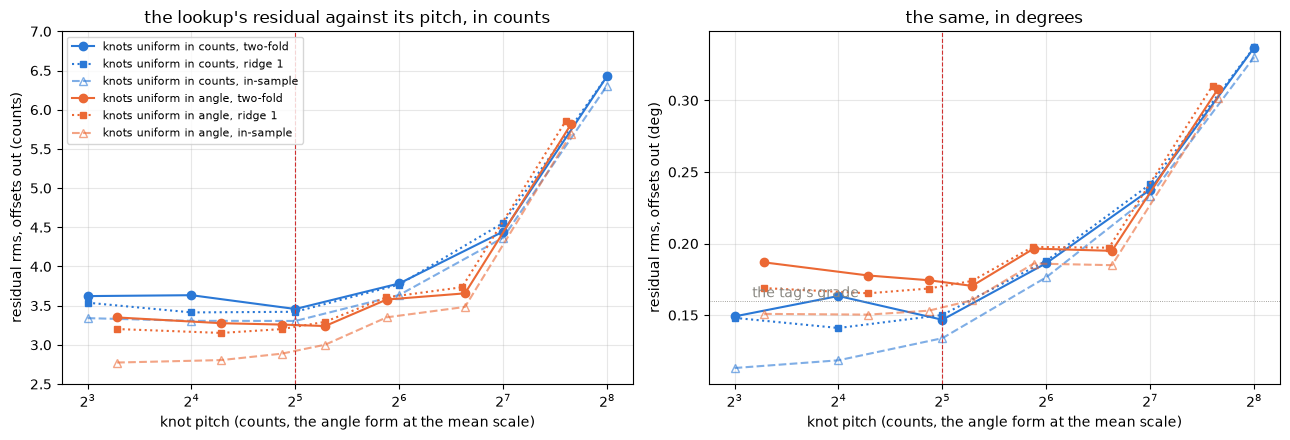

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, (unit, col) in zip(ax, (("counts", "cv_counts"), ("deg", "cv_deg"))):
    for kind, color in (("counts", BLUE), ("angle", ORANGE)):
        q = SCAN[(SCAN["form"] == kind) & (SCAN["ridge"] < 1)]
        q1 = SCAN[(SCAN["form"] == kind) & (SCAN["ridge"] == 1.0)]
        a.plot(q["pitch_counts"], q[col], "o-", color=color,
               label=f"knots uniform in {kind}, two-fold")
        a.plot(q1["pitch_counts"], q1[col], "s:", color=color, ms=4,
               label=f"knots uniform in {kind}, ridge 1")
        a.plot(q["pitch_counts"], q[col.replace("cv", "ins")], "^--",
               color=color, mfc="none", alpha=0.6,
               label=f"knots uniform in {kind}, in-sample")
    a.axvline(PITCH, **figures.HIGHLIGHT_STYLE)
    a.set_xscale("log", base=2)
    figures.label(a, x="knot pitch (counts, the angle form at the mean "
                  "scale)", y=f"residual rms, offsets out ({unit})")
ax[0].set_ylim(2.5, 7)
ax[1].axhline(TAG_GRADE_DEG, **figures.EDGE_STYLE)
ax[1].text(9, TAG_GRADE_DEG, "the tag's grade", color=MUTED, va="bottom")
ax[0].legend(fontsize=8)
ax[0].set_title("the lookup's residual against its pitch, in counts")
ax[1].set_title("the same, in degrees")
figures.finish(fig)

What the figure shows. The held-out residual of each lookup against its knot pitch, in counts on the left and degrees on the right, solid for the conditioning ridge, dotted smoothed, dashed in-sample. The red line marks 32 counts and the gray one on the right the tag's grade. Both forms fall to a floor between 16 and 32 counts and rise from 64 up. In degrees the counts form sits lowest.

### The ridge against the pitch

The finer pitches fitted with a range of ridges, scored two-fold, with the fitted table's monotony and its steepest and flattest cell. A table that is not monotone has cells running backwards.

In [16]:
ridge_rows = []
for p in (16, 32, 64):
    for ridge in (1e-3, 0.03, 0.1, 0.3, 1.0, 3.0):
        cd, cc = [], []
        for q in (0, 1):
            lk, _ = pe.build(M[M["fold"] != q], R[R["fold"] != q], p,
                             "counts", ridge)
            sm = M[M["fold"] == q]
            a, b = pe.errors(lk, sm["pos"], sm["image_deg"])
            cd.append(seg_out(a, sm["sid"]))
            cc.append(seg_out(b, sm["sid"]))
        full, _ = pe.build(M, R, p, "counts", ridge)
        cells = np.diff(full.c) / np.diff(full.a)   # counts/deg per cell
        ridge_rows.append(dict(pitch=p, ridge=ridge,
                               cv_deg=rms(np.concatenate(cd)),
                               cv_counts=rms(np.concatenate(cc)),
                               monotone=full.monotone,
                               min_slope=float(cells.min()),
                               max_slope=float(cells.max())))
RIDGE = pd.DataFrame(ridge_rows)
show(RIDGE, n=None)
lk, _ = pe.build(M, R, PITCH)
sl = np.diff(lk.c) / np.diff(lk.a)
print(f"{PITCH} count lookup, cell slopes in counts/deg: min {sl.min():.1f}"
      f" at {lk.c[sl.argmin()]:.0f} counts, 5 % "
      f"{np.percentile(sl, 5):.1f}, median {np.percentile(sl, 50):.1f}, "
      f"95 % {np.percentile(sl, 95):.1f}, max {sl.max():.1f} at "
      f"{lk.c[sl.argmax()]:.0f} counts")
n_guard = int(TABLE_Q1.set_index(["form", "pitch"]).loc[
    ("counts", PITCH), "entries_guard"])
n_full = int(4096 / PITCH) + 1          # entries over the 12 bit range
print(f"knots {lk.c[0]:.0f} to {lk.c[-1]:.0f} counts over the data, "
      f"{np.floor(GUARDS[0] / PITCH) * PITCH:.0f} to "
      f"{np.ceil(GUARDS[1] / PITCH) * PITCH:.0f} guard to guard")
print(f"entries at {PITCH} counts: {lk.entries} over the data's span, "
      f"{n_guard} guard to guard, {n_full} over the whole 12 bit range; "
      f"{2 * lk.entries}, {2 * n_guard} and {2 * n_full} bytes at 2 "
      "bytes an entry")

,pitch,ridge,cv_deg,cv_counts,monotone,min_slope,max_slope
0,16,0.001,0.171,3.672,False,-65.124,63.042
1,16,0.030,0.170,3.666,False,-265.799,51.405
2,16,0.100,0.163,3.634,True,10.180,48.294
3,16,0.300,0.151,3.553,True,10.230,43.459
4,16,1.000,0.141,3.414,True,10.627,32.707
5,16,3.000,0.147,3.386,True,11.457,30.038
6,32,0.001,0.147,3.459,True,11.248,35.101
7,32,0.030,0.147,3.459,True,11.249,35.092
8,32,0.100,0.147,3.457,True,11.256,35.004
9,32,0.300,0.147,3.449,True,11.318,34.285


32 count lookup, cell slopes in counts/deg: min 11.3 at 1824 counts, 5 % 14.1, median 19.3, 95 % 28.8, max 35.0 at 1536 counts
knots 576 to 3200 counts over the data, 384 to 3488 guard to guard
entries at 32 counts: 83 over the data's span, 98 guard to guard, 129 over the whole 12 bit range; 166, 196 and 258 bytes at 2 bytes an entry


### The choice of form and pitch

1. The residual stops falling at 32 counts, 1.64 degrees a knot. From 64 to 32 counts the two-fold residual falls from 3.784 to 3.457 counts (z 4.2) and from 0.186 to 0.147 degrees (z 8.1), and from 128 to 64 it falls likewise (z 4.85 and 5.94). From 32 to 16 nothing is gained. Unsmoothed, 16 counts scores worse, 3.634 counts and 0.163 degrees, at z 1.1 and 0.7, which is not a finding. Smoothed with a ridge of 1 it scores 3.414 counts and 0.141 degrees against 3.457 and 0.147 at 32, at z 1.1 and 1.8, under two sigma. 8 counts smoothed is no better than 16 smoothed, z 1.9 the wrong way. Confidence is high that 32 beats 64 and high that nothing under 32 is resolved by this data.
2. Why finer does not pay. First the data. A direct fit at 16 counts is not monotone at ridges of 0.001 and 0.03, with cells running from -65.1 to +63.0 counts per degree at the smaller one, and it needs a ridge of 0.1 or more to stay monotone. At 8 counts it is not monotone even at 0.1. A pitch of 16 or under only works as a smoothed fit, which is a 32 count table with more entries. Then the reference. The two-fold floor of 0.147 degrees sits at the tag's own grade of 0.16 degrees, so a finer table would fit texture finer than the reference is known to. Stage 3 put the pot's fine texture at 6.0 counts rms. At 32 counts the lookup leaves 3.457 counts held out, at 256 counts it leaves 6.426, about the whole texture.
3. The form. In counts the angle form is nominally better at a similar size, 3.259 counts at 1.5 degrees against 3.457 (z 1.4), which is not a finding. In degrees, the unit the servo is held to, the counts form is better, 0.147 against 0.174 at 1.5 degrees (z 3.5) and 0.178 at 1 degree (z 2.5). The likely reading, at moderate confidence, is that each form minimizes its own unit. The counts form fits the angle given the counts, which is the question the estimator asks. The pot's local scale at 32 counts runs from 11.3 to 35.0 counts per degree cell to cell, 14.1 to 28.8 between the 5th and the 95th percentile with a median of 19.3, and the extremes sit mid travel, at 1824 and 1536 counts, not in the thin ends. A residual of a fixed size in counts costs the most angle where the scale is low. The alternative, at low confidence, is that part of the gap is the angle form's grid not matching the counts form's knots. The counts form also needs no search.
4. The choice. Knots uniform in counts at a pitch of 32, so the index is the counts shifted right by 5. That is 83 entries over the data's span, 576 to 3200 counts, 98 guard to guard, 384 to 3488 counts with the end lines of section 4 carried as knots, and 129 over the whole 12 bit range, which is 166, 196 and 258 bytes at 2 bytes an entry. The bytes assume one 16 bit value per entry, and a float per entry doubles them. A pitch of 64 counts, 50 entries guard to guard, scores 0.186 against 0.147 degrees rms. 16 counts doubles the table for nothing this data resolves.

The held-out rest points agree, 3.239 counts at 32 with no offset out (n 75). The residual against the pitch is flat at 3.4 to 3.6 counts from 8 to 32 counts with either ridge and rises from 64 up.

## 3. The held-out grade

### The pot at each frame, on both clocks

Stage 3's frames carry the pot at each frame's host time, a 2 ms centered mean of the rows. The rows' stamps are the host's, and they lead the motion the camera sees by a few milliseconds that wander from chain to chain, the stamp lead. It belongs to the capture tool, not to the servo. Each frame's pot is read again here at `host_cam`, the rows shifted by the lead stage 3 fitted for the chain's direction group, so a grade can be stated with the lead in it and with it applied. A frame's tag speed is the slope of the tag angle over five frames either side inside its segment.

In [17]:
def tag_speed(h, a):
    """deg/s per frame: a line through +/-5 frames inside a segment."""
    n = len(h)
    v = np.full(n, np.nan)
    for i in range(n):
        lo, hi = max(0, i - 5), min(n, i + 6)
        if hi - lo >= 4:
            v[i] = np.polyfit(h[lo:hi] - h[i], a[lo:hi], 1)[0]
    return v


FC = FRAMES.copy()                      # the frames, both clocks
FC["sid"] = FC["clip"] + "/" + FC["k"].astype(str) + "/" + \
    FC["seg"].astype(str)
for col in ("pos_cam", "pos_chk", "tag_speed", "lead_ms"):
    FC[col] = np.nan
for (clip, k), g in FC.groupby(["clip", "k"]):
    rows = ROWS[(clip, k)]
    dt = float(np.median(np.diff(rows["host"].to_numpy()[:2000])))
    w = max(1, int(round(0.002 / dt)))  # rows in 2 ms
    for seg, gs in g.groupby("seg"):
        rs = rows[rows["seg"] == seg]
        box = rs["pos"].rolling(w, center=True, min_periods=1).mean()
        box = box.to_numpy()            # the pot's 2 ms mean
        FC.loc[gs.index, "pos_chk"] = np.interp(gs["host"],
                                                rs["host"].to_numpy(), box)
        hc = rs["host_cam"].to_numpy()  # the rows on the camera's clock
        if np.isfinite(hc).all():
            FC.loc[gs.index, "pos_cam"] = np.interp(gs["host"], hc, box)
            FC.loc[gs.index, "lead_ms"] = 1e3 * float(
                np.median(hc - rs["host"].to_numpy()))
        FC.loc[gs.index, "tag_speed"] = tag_speed(
            gs["host"].to_numpy(), gs["image_deg"].to_numpy())
chk = (FC["pos_chk"] - FC["pos"]).dropna()
print(f"{w} rows in 2 ms at {dt * 1e6:.1f} us; the re-read with no lead "
      f"against stage 3's pot: {rms(chk):.3f} counts rms, max "
      f"{chk.abs().max():.2f}, n {len(chk)}")
print(f"pot on the camera's clock at {int(FC['pos_cam'].notna().sum())} "
      f"of {len(FC)} frames, none in a baseline")

40 rows in 2 ms at 50.1 us; the re-read with no lead against stage 3's pot: 0.037 counts rms, max 0.31, n 13279
pot on the camera's clock at 11495 of 13279 frames, none in a baseline


Read again without the lead, the pot reproduces stage 3's frames to 0.037 counts rms, at most 0.31, over 13279 frames, so the re-read differs from stage 3's only by the lead. 11495 frames get a pot on the camera's clock. The baselines have no lead and get none.

### The scored set

Every frame whose tag moves faster than 2 degrees per second, inside the table's range, with a camera-aligned pot. Unlike the fit's moving frames this set keeps the kicks, the steps and the coasts under way, which the lookup was never fitted on.

In [18]:
MOVE_DEG_S = 2.0        # deg/s, a scored frame's tag speed at least
inr = (FC["image_deg"] > LO) & (FC["image_deg"] < HI)
S = FC[(FC["tag_speed"].abs() > MOVE_DEG_S) & inr
       & FC["pos_cam"].notna()].copy()
S["mdir"] = np.sign(S["tag_speed"]).astype(int)     # the tag's direction
S["bin"] = (np.floor(S["image_deg"] / 10) * 10).astype(int)   # 10 deg
speeds = S.groupby("kind_clip")["tag_speed"].agg(
    lambda x: np.percentile(np.abs(x), 50))
print(f"{len(S)} frames: " + ", ".join(
    f"{kd} {n}" for kd, n in S.groupby("kind_clip").size().items()))
print("median tag speed, deg/s: " + ", ".join(
    f"{kd} {v:.1f}" for kd, v in speeds.items()))
print("4 ms of alignment at that speed, deg: " + ", ".join(
    f"{kd} {0.004 * v:.2f}" for kd, v in speeds.items()))
print("mean stamp lead applied, ms: " + ", ".join(
    f"{kd} {v:.1f}" for kd, v in
    S.groupby("kind_clip")["lead_ms"].mean().items()))

8106 frames: crawl 5101, pass 567, reversal 1432, steps 1006
median tag speed, deg/s: crawl 26.5, pass 102.4, reversal 33.4, steps 31.2
4 ms of alignment at that speed, deg: crawl 0.11, pass 0.41, reversal 0.13, steps 0.12
mean stamp lead applied, ms: crawl 8.4, pass 11.3, reversal 4.1, steps 4.7


The set holds 8106 frames. The median tag speed is 26.5 degrees per second in the crawl, 31.2 in the steps, 33.4 in the reversal and 102.4 in the passes, so the 4 ms the clock is aligned to costs 0.11, 0.12, 0.13 and 0.41 degrees. That is the floor of every grade below with the lead applied.

The grade, three ways of reading the same error. "No lead" reads the pot as stage 3's frames carry it, at the stamps as captured. "Lead" reads it at `host_cam`. Each is scored with nothing taken out, with the mean of each clip kind and direction taken out, and with each segment's own offset taken out, the term the table's own model carries. Frames past the fitted lookup's knots are left out of that lookup's score.

In [19]:
def out(e, keys):
    """e less its mean over the groups `keys` of the scored set."""
    return e - e.groupby([S.loc[e.index, k] for k in keys]).transform(
        "mean")


LEVELS = (("raw", None), ("dir_out", ["kind_clip", "mdir"]),
          ("seg_out", ["sid"]))


def level_rows(ed, ec, split, test, col, n_seg, n_unc):
    """One row per level of what is taken out."""
    rows = []
    for lvl, keys in LEVELS:
        a, b = (ed, ec) if keys is None else (out(ed, keys), out(ec, keys))
        rows.append(dict(split=split, test=test, pos=col, level=lvl,
                         n=len(a), n_seg=n_seg, n_uncovered=n_unc,
                         mean_deg=a.mean(), sd_deg=a.std(),
                         rms_deg=rms(a), mean_counts=b.mean(),
                         sd_counts=b.std(), rms_counts=rms(b)))
    return rows


def grade(lk, idx, split, test, rows, keep=None):
    """Score lookup lk on the scored frames idx, both clocks."""
    t = S.loc[idx]
    cov = ((t["pos_cam"] >= lk.c[0]) & (t["pos_cam"] <= lk.c[-1])
           & (t["pos"] >= lk.c[0]) & (t["pos"] <= lk.c[-1]))
    t = t[cov]                          # inside the lookup's knots
    for col in ("pos", "pos_cam"):
        ed, ec = pe.errors(lk, t[col], t["image_deg"])
        ed, ec = pd.Series(ed, t.index), pd.Series(ec, t.index)
        rows += level_rows(ed, ec, split, test, col, t["sid"].nunique(),
                           int((~cov).sum()))
        if keep is not None:
            keep[col].append(pd.DataFrame(dict(e_deg=ed, e_counts=ec)))

In [20]:
grades, keep = [], {"pos": [], "pos_cam": []}
for q in (0, 1):            # two-fold, each fold holding one pass
    lk, _ = pe.build(M[M["fold"] != q], R[R["fold"] != q], PITCH)
    grade(lk, S.index[S["fold"] == q], "twofold", f"fold{q}", grades, keep)
E = {c: pd.concat(keep[c]) for c in keep}   # every scored frame once
S2 = S.loc[E["pos_cam"].index]
for col in ("pos", "pos_cam"):
    grades += level_rows(E[col]["e_deg"], E[col]["e_counts"], "twofold",
                         "pooled", col, S2["sid"].nunique(),
                         len(S) - len(E[col]))
for tr, tests in (("crawl", ["pass", "steps", "reversal"]),
                  ("pass+steps+reversal", ["crawl"])):  # by clip kind
    sel = (M["kind_clip"] == "crawl") == (tr == "crawl")
    selr = (R["kind_clip"] == "crawl") == (tr == "crawl")
    lk, _ = pe.build(M[sel], R[selr], PITCH)
    for te in tests:
        grade(lk, S.index[S["kind_clip"] == te], "fit " + tr, te, grades)
for a, b in (("pass-open", "pass-close"), ("pass-close", "pass-open")):
    for p in (PITCH, 2 * PITCH):        # one pass grades the other
        lk, _ = pe.build(M[M["clip"] == a], R[R["clip"] == a], p)
        grade(lk, S.index[S["clip"] == b], f"fit {a} at {p}", b, grades)
LK_ALL, _ = pe.build(M, R, PITCH)       # every frame, in-sample
grade(LK_ALL, S.index, "in-sample", "all", grades)
g = np.linspace(LO, HI, 20001)
c3 = STAGE3_COUNTS(g)                   # stage 3's spline, inverted
for col in ("pos", "pos_cam"):
    e3 = np.interp(S[col], c3, g) - S["image_deg"]
    grades.append(dict(split="stage 3 spline, in-sample", test="all",
                       pos=col, level="raw", n=len(e3),
                       n_seg=S["sid"].nunique(), n_uncovered=0,
                       mean_deg=e3.mean(), sd_deg=e3.std(),
                       rms_deg=rms(e3)))
G = pd.DataFrame(grades)

In [21]:
P = G[G["test"].isin(["pooled", "fold0", "fold1", "pass", "steps",
                      "reversal", "crawl", "pass-close", "pass-open",
                      "all"])]
GRADES = P.pivot_table(index=["split", "test"], columns=["pos", "level"],
                       values="rms_deg", sort=False)
GRADES.columns = [f"{'lead' if a == 'pos_cam' else 'no lead'}, {b}"
                  for a, b in GRADES.columns]
cam = P[P["pos"] == "pos_cam"].set_index(["split", "test", "level"])
GRADES["lead, seg_out, counts"] = cam.xs("seg_out", level="level")[
    "rms_counts"]
GRADES["lead, raw, counts"] = cam.xs("raw", level="level")["rms_counts"]
GRADES["n"] = cam.xs("raw", level="level")["n"]
GRADES["segments"] = cam.xs("raw", level="level")["n_seg"]
GRADES["left out"] = cam.xs("raw", level="level")["n_uncovered"]
show(GRADES.reset_index(), n=None)
raw = P[(P["test"] == "pooled") & (P["level"] == "raw")].set_index("pos")
print(f"pooled two-fold, nothing out, mean error: lead "
      f"{raw.loc['pos_cam', 'mean_deg']:+.3f} deg, no lead "
      f"{raw.loc['pos', 'mean_deg']:+.3f} deg")

,split,test,"no lead, raw","no lead, dir_out","no lead, seg_out","lead, raw","lead, dir_out","lead, seg_out","lead, seg_out, counts","lead, raw, counts",n,segments,left out
0,twofold,fold0,0.600,0.388,0.180,0.376,0.305,0.170,3.377,7.207,4328,61,17
1,twofold,fold1,0.529,0.336,0.167,0.446,0.287,0.160,3.424,8.613,3741,51,20
2,twofold,pooled,0.568,0.396,0.174,0.410,0.325,0.165,3.399,7.890,8069,112,37
3,fit crawl,pass,0.850,0.594,0.187,0.569,0.327,0.214,4.202,10.895,533,8,34
4,fit crawl,steps,0.161,0.141,0.125,0.173,0.153,0.136,2.678,3.427,984,11,22
5,fit crawl,reversal,0.247,0.242,0.191,0.485,0.402,0.213,4.403,9.344,1405,8,27
6,fit pass+steps+reversal,crawl,0.617,0.427,0.196,0.372,0.321,0.168,3.458,7.197,5099,82,2
7,fit pass-open at 32,pass-close,0.154,0.148,0.143,0.512,0.189,0.141,3.379,10.164,286,4,7
8,fit pass-open at 64,pass-close,0.229,0.187,0.179,0.461,0.230,0.178,3.453,8.945,286,4,7
9,fit pass-close at 32,pass-open,1.176,0.358,0.212,0.784,0.372,0.218,4.541,14.958,269,4,5


pooled two-fold, nothing out, mean error: lead -0.034 deg, no lead -0.025 deg


1. The table costs nothing held out. The pooled two-fold over 8069 frames, 37 left out past the fitted lookups' knots, reads 0.165 degrees rms with each segment's offset out, 3.399 counts, and the two folds read 0.170 and 0.160 degrees, 3.377 and 3.424 counts. In-sample the same lookup reads 0.162 degrees and 3.344 counts. With the lead applied and nothing out the two-fold reads 0.410 against 0.411 in-sample. Confidence is high, with 8069 frames over 112 segments and three kinds of split agreeing at 0.136 to 0.218 degrees with the offsets out.
2. The grade is a bracket, and each number says what was taken out. With each segment's offset out, the table's own term, it is 0.165 degrees rms. With the capture's stamp lead applied and nothing else taken out it is 0.410 degrees. The stamp lead is the capture tool's, the host's segment stamps against the camera's clock, and not the servo's. With nothing done it is 0.568 degrees.
3. Stage 3 graded the pot through its table at 0.400 degrees rms. Its own spline, in-sample on this frame set, reads 0.414 with the lead applied and 0.562 without, so stage 3's 0.400 was a lead-applied number and 0.410 is its held-out twin.
4. By split, crawl to steps is the tightest, 0.136 degrees with the offsets out, 2.678 counts. Crawl to pass and crawl to reversal read 0.214 and 0.213 degrees, 4.202 and 4.403 counts, the pass limited by its 0.41 degrees of alignment. A table from one pass alone grades the other at 0.141 and 0.218 degrees with the offsets out, the same as the two-fold.

Each row gives the split and the test set, then the rms in degrees of each reading, no lead or lead, with nothing (`raw`), the kind-by-direction means (`dir_out`) or each segment's offset (`seg_out`) taken out, then the lead's rms in counts and the frames scored and left out.

By clip kind and direction, lead applied, held out, with the standard error over segments, since frames inside one segment share its offset.

In [22]:
D = S2.assign(e_deg=E["pos_cam"]["e_deg"], e_counts=E["pos_cam"]["e_counts"],
              e_deg_nolead=E["pos"]["e_deg"])     # the held-out errors


def agg(keys):
    """Mean, sd, frames and the se over segments of the groups `keys`."""
    segm = D.groupby(keys + ["sid"])["e_deg"].mean().reset_index()
    a = D.groupby(keys).agg(
        n=("e_deg", "size"), mean_deg=("e_deg", "mean"),
        sd_deg=("e_deg", "std"), mean_counts=("e_counts", "mean"),
        sd_counts=("e_counts", "std"),
        mean_deg_nolead=("e_deg_nolead", "mean"),
        speed=("tag_speed", lambda x: np.median(np.abs(x)))).reset_index()
    b = segm.groupby(keys)["e_deg"].agg(
        n_seg="size", se_seg=lambda x: x.std() / np.sqrt(len(x))
        if len(x) > 1 else np.nan).reset_index()
    return a.merge(b, on=keys)


DM = agg(["kind_clip", "mdir"])         # by kind and direction
BN = agg(["bin", "mdir"])               # by 10 deg bin and direction
show(DM[["kind_clip", "mdir", "n", "n_seg", "mean_deg", "se_seg", "sd_deg",
         "mean_deg_nolead", "speed"]], n=None)

,kind_clip,mdir,n,n_seg,mean_deg,se_seg,sd_deg,mean_deg_nolead,speed
0,crawl,-1,2788,39,-0.230,0.050,0.301,-0.468,25.912
1,crawl,1,2306,44,0.207,0.052,0.361,0.484,27.158
2,pass,-1,283,4,0.185,0.129,0.228,-0.608,103.877
3,pass,1,272,4,-0.668,0.228,0.388,0.539,100.380
4,reversal,-1,704,5,0.276,0.195,0.424,0.042,33.214
5,reversal,1,718,6,-0.282,0.132,0.365,-0.053,33.384
6,steps,-1,492,5,0.157,0.049,0.165,-0.015,33.953
7,steps,1,506,6,-0.091,0.123,0.148,0.056,28.329


With the lead applied, the crawl reads -0.230 +/- 0.050 degrees moving down and +0.207 +/- 0.052 moving up, the pot ahead along the motion. The steps and the reversal read the other way round, +0.157 down and -0.091 up, +0.276 down and -0.282 up. The passes read +0.185 and -0.668, at the 0.41 degrees of alignment their speed allows. With no lead the crawl reads -0.468 and +0.484 while the steps and the reversal sit within 0.06 degrees of zero.

### The residual over the travel

The central figure. Every held-out frame's error, the lookup's angle less the tag with the lead applied, against the tag angle, by the direction of motion, with the 10 degree bin means and their spread. Below it the same frames with each segment's offset taken out, which leaves the table's own term.

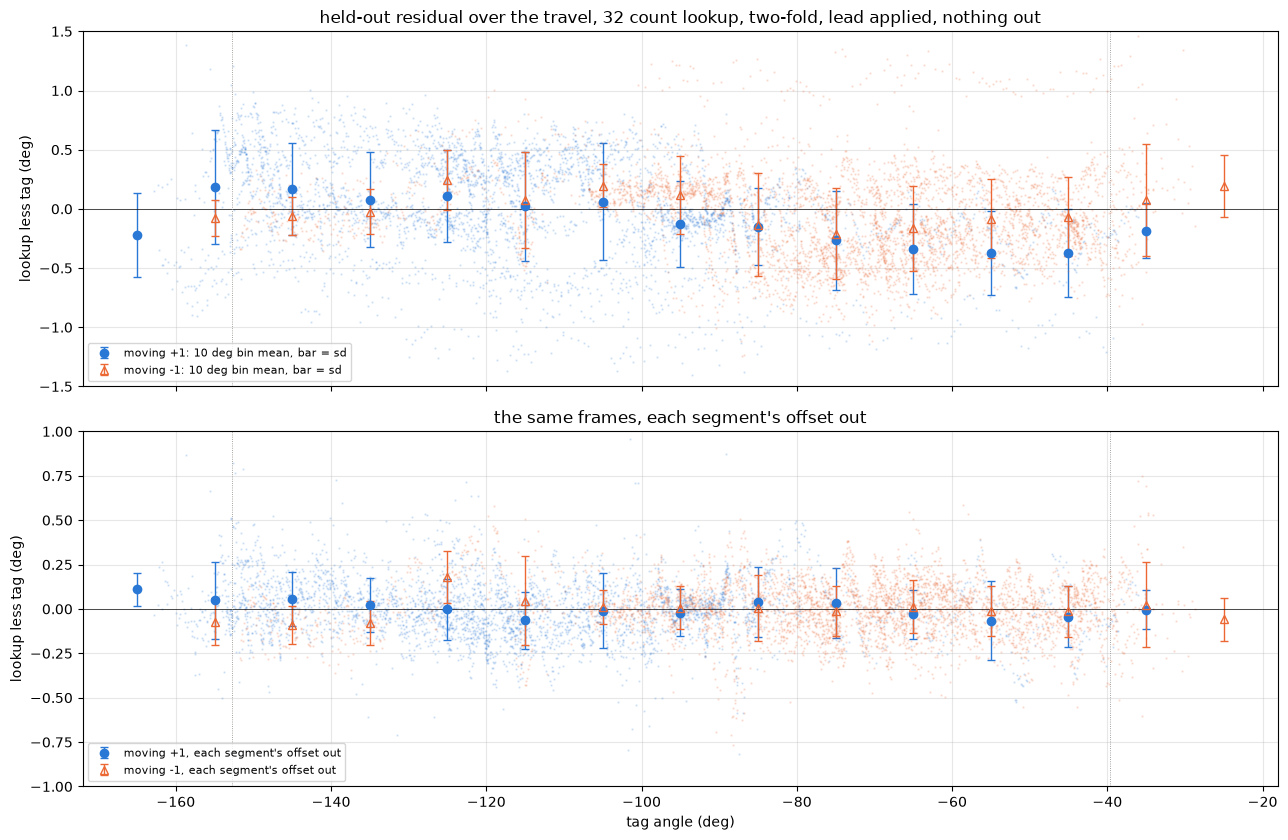

In [23]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True)
for dr, color in ((1, BLUE), (-1, ORANGE)):
    q, b = D[D["mdir"] == dr], BN[BN["mdir"] == dr]
    ax[0].plot(q["image_deg"], q["e_deg"], ".", ms=1.5, alpha=0.15,
               color=color)
    ax[0].errorbar(b["bin"] + 5, b["mean_deg"], yerr=b["sd_deg"],
                   capsize=figures.CAP_PT, lw=1,
                   **figures.direction_style(dr, color),
                   label=f"moving {dr:+d}: 10 deg bin mean, bar = sd")
    es = q["e_deg"] - q.groupby("sid")["e_deg"].transform("mean")
    bs = es.groupby((np.floor(q["image_deg"] / 10) * 10).astype(int)).agg(
        ["mean", "std"])
    ax[1].plot(q["image_deg"], es, ".", ms=1.5, alpha=0.15, color=color)
    ax[1].errorbar(bs.index + 5, bs["mean"], yerr=bs["std"],
                   capsize=figures.CAP_PT, lw=1,
                   **figures.direction_style(dr, color),
                   label=f"moving {dr:+d}, each segment's offset out")
for a in ax:
    a.axhline(0, color=INK, lw=0.5)
    for edge in INT:                    # the crawl's coverage in deg
        a.axvline(float(LK_ALL.angle(edge)), **figures.EDGE_STYLE)
    a.legend(fontsize=8, loc="lower left")
ax[0].set_ylim(-1.5, 1.5)
ax[1].set_ylim(-1.0, 1.0)
figures.label(ax[0], y="lookup less tag (deg)", title=(
    f"held-out residual over the travel, {PITCH} count lookup, two-fold, "
    "lead applied, nothing out"))
figures.label(ax[1], x="tag angle (deg)", y="lookup less tag (deg)",
              title="the same frames, each segment's offset out")
figures.finish(fig)

What the figure shows. Top, every held-out frame's error with nothing taken out, blue moving up and orange moving down, with the 10 degree bin means and their sd. The dotted lines mark the crawl's coverage. Bottom, the same frames with each segment's offset out, the term the lookup itself leaves. The top panel carries the direction term and the segments' wander, and the bottom one is flat over the travel.

In [24]:
bn = BN.assign(z=BN["mean_deg"] / BN["se_seg"])
top = bn.loc[bn["z"].abs().idxmax()]
print(f"nothing out: bin means {BN['mean_deg'].min():+.2f} to "
      f"{BN['mean_deg'].max():+.2f} deg, sd in a bin "
      f"{BN['sd_deg'].min():.2f} to {BN['sd_deg'].max():.2f}; largest "
      f"|mean / se| {abs(top['z']):.1f} at {top['bin']:.0f} deg, dir "
      f"{top['mdir']:+.0f} ({top['mean_deg']:+.2f} +/- {top['se_seg']:.2f})"
      f", over {len(BN)} bins")
es = D["e_deg"] - D.groupby("sid")["e_deg"].transform("mean")
BS_OUT = es.groupby([(np.floor(D["image_deg"] / 10) * 10).astype(int),
                     D["mdir"]]).agg(["mean", "std", "size"])
BS_OUT = BS_OUT[BS_OUT["size"] >= 50]   # bins of 50 frames or more
print(f"segment offsets out, bins of 50 frames or more: means "
      f"{BS_OUT['mean'].min():+.3f} to {BS_OUT['mean'].max():+.3f} deg, sd"
      f" {BS_OUT['std'].min():.3f} to {BS_OUT['std'].max():.3f}")
up, down = BN[BN["mdir"] == 1], BN[BN["mdir"] == -1]
hi_up = up[up["bin"] > -90]             # moving + above -90 deg
print(f"moving +1 bins above -90 deg: {hi_up['n'].min()} to "
      f"{hi_up['n'].max()} frames, se {hi_up['se_seg'].min():.2f} to "
      f"{hi_up['se_seg'].max():.2f} deg")
share_up = up[up["bin"] < -100]["n"].sum() / up["n"].sum()
share_down = down[down["bin"] >= -100]["n"].sum() / down["n"].sum()
print(f"moving +1 frames below -100 deg {100 * share_up:.0f} %, moving -1 "
      f"frames at -100 deg and above {100 * share_down:.0f} %")

nothing out: bin means -0.37 to +0.24 deg, sd in a bin 0.16 to 0.49; largest |mean / se| 2.2 at -110 deg, dir -1 (+0.19 +/- 0.09), over 28 bins
segment offsets out, bins of 50 frames or more: means -0.093 to +0.181 deg, sd 0.097 to 0.251
moving +1 bins above -90 deg: 21 to 81 frames, se 0.27 to 0.48 deg
moving +1 frames below -100 deg 71 %, moving -1 frames at -100 deg and above 87 %


With nothing out the bin means lie within -0.37 to +0.24 degrees, the sd inside a bin 0.16 to 0.49. The largest bin mean is 2.2 standard errors from zero, at -110 degrees moving down, +0.19 +/- 0.09, among 28 bins, so none is a finding. With each segment's offset out the bin means of 50 frames or more lie within -0.093 to +0.181 degrees and the sd inside a bin within 0.097 to 0.251. That is the flat band of the table term over the travel. Moving up the bin means fall over the travel, but the bins above -90 degrees hold 21 to 81 frames with standard errors of 0.27 to 0.48 degrees, so the trend is not a finding. Direction and position are confounded in this set. 71 % of the frames moving up lie below -100 degrees, and 87 % of those moving down at -100 degrees and above.

### What the error is made of

The pooled held-out error's mean square is taken apart in a fixed order. First goes the stamp lead, the no-lead reading against the lead reading, then the kind-by-direction means, then the wander of segments beyond those means. What is left is the table, the pot's texture and the noise. The order matters, so the shares are a budget of this order only.

In [25]:
def ms(x):
    """Mean square."""
    return float(np.mean(x ** 2))


e0, e1 = D["e_deg_nolead"], D["e_deg"]
e2 = e1 - e1.groupby([D["kind_clip"], D["mdir"]]).transform("mean")
e3 = e1 - e1.groupby(D["sid"]).transform("mean")
BUDGET = dict(n=len(D), ms_nolead=ms(e0), ms_lead=ms(e1),
              ms_dir_out=ms(e2), ms_seg_out=ms(e3))
BUDGET.update(
    share_lead=(BUDGET["ms_nolead"] - BUDGET["ms_lead"]) / BUDGET["ms_nolead"],
    share_dir=(BUDGET["ms_lead"] - BUDGET["ms_dir_out"]) / BUDGET["ms_nolead"],
    share_seg=(BUDGET["ms_dir_out"] - BUDGET["ms_seg_out"])
    / BUDGET["ms_nolead"],
    share_table=BUDGET["ms_seg_out"] / BUDGET["ms_nolead"])
steps_ = (("start: no lead, nothing out", "ms_nolead", None),
          ("stamp lead applied", "ms_lead", "share_lead"),
          ("kind-by-direction means out", "ms_dir_out", "share_dir"),
          ("segment wander out", "ms_seg_out", "share_seg"))
for name, key, share in steps_:
    s = "" if share is None else f", {100 * BUDGET[share]:.1f} % taken"
    print(f"{name:30s} {BUDGET[key]:.4f} deg^2, rms "
          f"{np.sqrt(BUDGET[key]):.3f} deg{s}")
print(f"{'left: table, texture, noise':30s} "
      f"{100 * BUDGET['share_table']:.1f} % of the start, n {BUDGET['n']}")

start: no lead, nothing out    0.3227 deg^2, rms 0.568 deg
stamp lead applied             0.1682 deg^2, rms 0.410 deg, 47.9 % taken
kind-by-direction means out    0.1058 deg^2, rms 0.325 deg, 19.4 % taken
segment wander out             0.0274 deg^2, rms 0.165 deg, 24.3 % taken
left: table, texture, noise    8.5 % of the start, n 8069


With nothing done the pooled error's mean square is 0.3227 square degrees. The stamp lead takes 47.9 % of it, the kind-by-direction means 19.4 %, and the wander of segments beyond those means 24.3 %. 8.5 % is left for the table, the texture and the noise. The gap between 0.568 or 0.410 degrees and 0.165 is not the table. The shares hold for this order of taking terms out, so the confidence in them is moderate.

### Lash or timing, per segment

Each held-out segment's mean error, signed along its direction of travel, against its median speed. A line through them reads a lash-like half width at zero speed as its intercept and a timing error as its slope, if the segments sampled both at the same positions. They do not, which the next cell takes up.

In [26]:
D["sgn"] = D["e_deg"] * D["mdir"]       # error along the travel
D["sgn_nolead"] = D["e_deg_nolead"] * D["mdir"]
D["spd"] = D["tag_speed"].abs()
SEGS = D.groupby(["sid", "mdir", "kind_clip"]).agg(
    n=("sgn", "size"), sgn=("sgn", "mean"), sgn_nolead=("sgn_nolead", "mean"),
    spd=("spd", "median"), lead_ms=("lead_ms", "first")).reset_index()
SEGS = SEGS[SEGS["n"] >= 10]            # segments of 10 frames or more
lines = []
for col in ("sgn", "sgn_nolead"):
    for kd in ("crawl", "pass", "reversal", "steps", "all"):
        q = SEGS if kd == "all" else SEGS[SEGS["kind_clip"] == kd]
        A = np.c_[np.ones(len(q)), q["spd"]]
        b = np.linalg.lstsq(A, q[col], rcond=None)[0]
        e = q[col] - A @ b
        cov = np.linalg.inv(A.T @ A) * e.var(ddof=2)
        lines.append(dict(set=kd, lead="no" if "nolead" in col else "yes",
                          n_seg=len(q), speed_lo=q["spd"].min(),
                          speed_hi=q["spd"].max(), intercept_deg=b[0],
                          se_i=np.sqrt(cov[0, 0]), slope_ms=1e3 * b[1],
                          se_s=1e3 * np.sqrt(cov[1, 1]),
                          resid_sd=e.std(ddof=2)))
LASH_LINES = pd.DataFrame(lines)
show(LASH_LINES, n=None)

,set,lead,n_seg,speed_lo,speed_hi,intercept_deg,se_i,slope_ms,se_s,resid_sd
0,crawl,yes,58,4.563,163.399,0.294,0.046,-3.203,0.572,0.259
1,pass,yes,8,15.813,105.845,0.107,0.209,-5.980,2.781,0.313
2,reversal,yes,9,26.909,151.079,0.095,0.167,-6.967,1.910,0.250
3,steps,yes,9,25.351,150.954,-0.178,0.053,1.880,0.907,0.103
4,all,yes,84,4.563,163.399,0.207,0.049,-3.663,0.625,0.315
5,crawl,no,58,4.563,163.399,0.389,0.075,-0.291,0.931,0.422
6,pass,no,8,15.813,105.845,0.159,0.377,4.569,5.030,0.565
7,reversal,no,9,26.909,151.079,0.118,0.071,-3.086,0.813,0.106
8,steps,no,9,25.351,150.954,-0.073,0.033,3.194,0.561,0.064
9,all,no,84,4.563,163.399,0.310,0.067,-0.257,0.852,0.429


Taken at face value, the crawl's line reads a half width of +0.294 +/- 0.046 degrees at zero speed and a timing slope of -3.203 +/- 0.572 ms, and all kinds together +0.207 +/- 0.049 degrees and -3.663 +/- 0.625 ms. The steps read the other way, -0.178 +/- 0.053 degrees over 9 segments. These lines do not control for position, which the next read does, and it changes the reading.

### Direction or position

In the crawl the direction of motion and the position are confounded, since each crawl started its + segments low and its - segments high. Four reads control for position, each with a standard error from a seeded bootstrap over segments. The first is the direction contrast inside 10 degree bins that hold at least 50 frames each way, half the difference of the two directions' means. The second and third come from one regression of the error on the bin, a speed-free term $h$ ("h") by direction and a timing term $\tau$ ("tau") by direction times speed. The fourth is the slope of the error against the angle inside a segment, set against the slope of the segments' means.

In [27]:
D["host"] = FC.loc[D.index, "host"]
D["min"] = (D["host"] - FC["host"].min()) / 60   # minutes into the sitting
rng = np.random.default_rng(0)          # seeded: the same draws every run


def boot(fn, q, n=400):
    """fn(q) and its bootstrap sd over q's segments."""
    ss = q["sid"].unique()
    gg = {s_: g for s_, g in q.groupby("sid")}
    est = np.array(fn(q))
    bs = np.array([fn(pd.concat([gg[s_] for s_ in rng.choice(ss, len(ss))]))
                   for _ in range(n)])
    return est, np.nanstd(bs, axis=0)


def contrast(q):
    """[the direction contrast in bins, the bins, the even part's slope]."""
    b = q.groupby(["bin", "mdir"])["e_deg"].agg(["mean", "size"]).unstack()
    ok = (b["size"][1] >= 50) & (b["size"][-1] >= 50)
    m_, n_ = b["mean"][ok], b["size"][ok]
    w = 1 / (1 / n_[1] + 1 / n_[-1])
    odd, even = (m_[1] - m_[-1]) / 2, (m_[1] + m_[-1]) / 2
    sl = (np.polyfit(even.index + 5.0, even.values, 1)[0]
          if len(even) > 2 else np.nan)
    return [(odd * w).sum() / w.sum(), len(odd), 100 * sl]


def reg(q):
    """[h deg, tau ms] of e ~ bin + h dir + tau dir speed."""
    X = np.c_[pd.get_dummies(q["bin"]).to_numpy(float), q["mdir"],
              q["mdir"] * q["spd"]]
    b = np.linalg.lstsq(X, q["e_deg"].to_numpy(), rcond=None)[0]
    return [b[-2], 1e3 * b[-1]]

In [28]:
def slopes(q):
    """[% per deg inside segments, % per deg between segment means]."""
    th = q["image_deg"] - q.groupby("sid")["image_deg"].transform("mean")
    e = q["e_deg"] - q.groupby("sid")["e_deg"].transform("mean")
    within = (th * e).sum() / (th * th).sum()
    sg = q.groupby("sid").agg(th=("image_deg", "mean"), e=("e_deg", "mean"),
                              n=("e_deg", "size"))
    between = np.polyfit(sg["th"], sg["e"], 1, w=np.sqrt(sg["n"]))[0]
    return [100 * within, 100 * between]


conf = []
with warnings.catch_warnings():         # empty bins in the bootstrap draws
    warnings.simplefilter("ignore")
    for lab in ("all", "crawl", "pass"):
        q = D if lab == "all" else D[D["kind_clip"] == lab]
        (odd, nb, sl), se1 = boot(contrast, q)
        (h, tau), se2 = boot(reg, q)
        (wi, be), se3 = boot(slopes, q)
        conf.append(dict(set=lab, n=len(q), n_seg=q["sid"].nunique(),
                         bins_both_dirs=int(nb), odd_half_deg=odd,
                         se_odd=se1[0], h_deg=h, se_h=se2[0], tau_ms=tau,
                         se_tau=se2[1], within_seg_slope_pct=wi,
                         se_within=se3[0], between_seg_slope_pct=be,
                         se_between=se3[1]))
CONFOUND = pd.DataFrame(conf).set_index("set")
print("standard errors from 400 bootstrap draws over segments, seed 0")
show(CONFOUND.T.reset_index(), n=None)
h_, tau_ = CONFOUND.loc["all", "h_deg"], CONFOUND.loc["all", "tau_ms"]
print(f"h and tau x speed cancel at {-h_ / tau_ * 1e3:.0f} deg/s")

standard errors from 400 bootstrap draws over segments, seed 0


set,index,all,crawl,pass
0,n,8069.000,5094.000,555.000
1,n_seg,112.000,82.000,8.000
2,bins_both_dirs,11.000,3.000,0.000
3,odd_half_deg,-0.055,0.019,NaN
4,se_odd,0.048,0.040,0.159
5,h_deg,0.192,0.136,0.048
6,se_h,0.046,0.041,0.215
7,tau_ms,-5.880,-3.946,-5.818
8,se_tau,0.917,0.615,2.430
9,within_seg_slope_pct,-0.210,-0.130,-0.358


h and tau x speed cancel at 33 deg/s


In [29]:
cs = D[D["kind_clip"] == "crawl"].groupby("sid").agg(
    th=("image_deg", "mean"), t=("min", "mean"), e=("e_deg", "mean"),
    dr=("mdir", "mean"), lead=("lead_ms", "first"), n=("e_deg", "size"))
cs = cs[cs["n"] >= 10]                  # crawl segments of 10+ frames
A = np.c_[np.ones(len(cs)), cs["th"] - cs["th"].mean(),
          cs["t"] - cs["t"].mean()]
b = np.linalg.lstsq(A, cs["e"], rcond=None)[0]
r_ = cs["e"] - A @ b
cov = np.linalg.inv(A.T @ A) * r_.var(ddof=3)
print(f"crawl segments, n {len(cs)}: corr(angle, time) "
      f"{np.corrcoef(cs['th'], cs['t'])[0, 1]:.2f}, corr(angle, dir) "
      f"{np.corrcoef(cs['th'], cs['dr'])[0, 1]:.2f}, corr(lead, angle) "
      f"{np.corrcoef(cs['th'], cs['lead'])[0, 1]:.2f}, corr(lead, error) "
      f"{np.corrcoef(cs['lead'], cs['e'])[0, 1]:.2f}")
print(f"crawl segment means on angle and time together: "
      f"{100 * b[1]:.2f} +/- {100 * np.sqrt(cov[1, 1]):.2f} % per deg, "
      f"{b[2]:+.3f} +/- {np.sqrt(cov[2, 2]):.3f} deg/min")

crawl segments, n 58: corr(angle, time) 0.06, corr(angle, dir) -0.75, corr(lead, angle) -0.03, corr(lead, error) -0.00
crawl segment means on angle and time together: -0.54 +/- 0.15 % per deg, -0.015 +/- 0.015 deg/min


1. The plain contrast inside the bins is -0.055 +/- 0.048 degrees over 11 bins for every kind and +0.019 +/- 0.040 over 3 for the crawl, zero within its error. At the speeds sampled, 26.5 to 33.4 degrees per second at the median, the pot is neither ahead nor behind by direction once the position is held.
2. With a speed term the same frames split into a speed-free half width of +0.192 +/- 0.046 degrees, the pot ahead along the travel, and a timing slope of -5.880 +/- 0.917 ms, the pot late, which cancel at 33 degrees per second. Two readings. (a) A lash of about 0.2 degrees of half width with the pot on the gear side, plus a lead over-applied by about the timing term, 3.9 ms in the crawl and 5.9 over every kind, at moderate to low confidence, since the larger one is about 1.5 times the 4 ms floor of the alignment. (b) No lash term at all and an error that is not linear in speed, the fit leaning on the kicks at 100 to 163 degrees per second, at low to moderate confidence.
3. The crawl's segment means fall with the angle at -0.54 +/- 0.15 % per degree with time in the model, and time itself reads -0.015 +/- 0.015 degrees per minute, nothing. Over the crawl segments the angle and the time correlate at 0.06, the angle and the direction at -0.75, the fitted lead and the error at -0.00. Inside a segment the slope is -0.130 +/- 0.120 % per degree. So the slope is most likely not a scale difference between the moving frames and the rest points, at moderate confidence, and whether the crawl's by-direction term is direction or position the crawl does not say.
4. A discrepancy. On the per-segment line the steps read the other way, and with no lead applied the steps and the reversal sit within 0.06 degrees of zero by direction while the crawl sits at -0.468 and +0.484. One lash value and one timing rule do not give both. The candidates are a lead fitted on the step and reversal transients that is biased long by about the whole lead applied to them, 4.1 and 4.7 ms on average, at moderate confidence since the no-lead agreement says so, and a lash taken up differently under a hard drive than at 6 to 11 % duty, at low confidence. The capture that separates them is the same one that separates the direction term in section 8, and it is listed once, with the gaps.
5. What a servo is held to, as I read it. The stamp lead is not its error, so the bracket runs from 0.165 degrees rms, the table term alone, to 0.410 degrees rms, everything left after the lead, which still holds the alignment's 0.11 to 0.41 degrees at these speeds and the unassigned direction and segment terms. The table's own share is settled. The rest is the direction term of section 8.

## 4. The ends and what is extrapolation

The moving frames stop short of both guards. Past the table's last knot a lookup has to run a line, and its slope has to come from somewhere. The only data out there are the rest points at the drive starts, where every chain starts from a guard or from a sixth or a third of the travel in. The line here is pinned to the table's last knot and its slope fitted through those start points alone, a line through the origin at the knot. A free line through the start points, with its own intercept, is fitted beside it, which is stage 3's construction. Each is graded on the same start points, and the pinned one leave one out as well.

In [30]:
LK = LK_ALL                             # the 32 count lookup, every frame
print(f"knots {LK.c[0]:.0f} to {LK.c[-1]:.0f} counts = {LK.a[0]:.2f} to "
      f"{LK.a[-1]:.2f} deg; frames and rest points reach "
      f"{min(M['pos'].min(), R['pos'].min()):.1f} to "
      f"{max(M['pos'].max(), R['pos'].max()):.1f} counts")
print(f"the last cells' own slopes {LK.lo_slope:.1f} and {LK.hi_slope:.1f} "
      f"counts/deg, the table's mean {LK.scale():.2f}")
OUTSIDE = STATIC[(STATIC["image_deg"] < LO)
                 | (STATIC["image_deg"] > HI)].copy()   # past the table
OUTSIDE["end"] = np.where(OUTSIDE["pos"] < LK.c[0] + 1e-9, "low", "high")
OUTSIDE.loc[(OUTSIDE["pos"] > LK.c[0]) & (OUTSIDE["pos"] < LK.c[-1]),
            "end"] = "inside the knots"
print(OUTSIDE.groupby("end").size().to_dict())

knots 576 to 3200 counts = -162.96 to -28.50 deg; frames and rest points reach 602.3 to 3194.9 counts
the last cells' own slopes 25.1 and 23.9 counts/deg, the table's mean 19.52
{'high': 11, 'low': 11}


In [31]:
end_rows, END_SLOPE = [], {}
for end, q in OUTSIDE.groupby("end"):
    if end == "inside the knots":
        continue
    c0, a0 = (LK.c[0], LK.a[0]) if end == "low" else (LK.c[-1], LK.a[-1])
    x = q["image_deg"].to_numpy() - a0  # deg past the last knot
    y = q["pos"].to_numpy() - c0        # counts past the last knot
    pinned = float((x * y).sum() / (x * x).sum())   # through the knot
    ep = y - pinned * x
    se_p = float(np.sqrt(ep.var(ddof=1) / (x * x).sum()))
    A = np.c_[np.ones(len(x)), x]       # the free line, own intercept
    b = np.linalg.lstsq(A, y, rcond=None)[0]
    ef = y - A @ b
    cov = np.linalg.inv(A.T @ A) * ef.var(ddof=2)
    loo = np.array([y[i] - x[i] * ((np.delete(x, i) * np.delete(y, i)).sum()
                                   / (np.delete(x, i) ** 2).sum())
                    for i in range(len(x))])     # leave one out
    END_SLOPE[end] = pinned
    cell = LK.lo_slope if end == "low" else LK.hi_slope
    end_rows.append(dict(
        end=end, n=len(q), pos_min=q["pos"].min(), pos_max=q["pos"].max(),
        deg_min=q["image_deg"].min(), deg_max=q["image_deg"].max(),
        between_table_and_guard=int(((q["pos"] > GUARDS[0])
                                     & (q["pos"] < GUARDS[1])).sum()),
        slope_pinned=pinned, se_pinned=se_p, slope_free=b[1],
        se_free=float(np.sqrt(cov[1, 1])), free_step_counts=b[0],
        rms_pinned_counts=rms(ep), rms_pinned_deg=rms(ep / pinned),
        loo_counts=rms(loo), loo_deg=rms(loo / pinned),
        rms_free_counts=rms(ef), rms_last_cell_counts=rms(y - cell * x),
        pot_sd_median=q["pos_sd"].median()))
ENDS = pd.DataFrame(end_rows).set_index("end")
show(ENDS.T.reset_index(), n=None)

end,index,high,low
0,n,11.000,11.000
1,pos_min,3361.100,274.725
2,pos_max,3591.650,527.375
3,deg_min,-20.682,-177.019
4,deg_max,-10.443,-165.482
5,between_table_and_guard,2.000,1.000
6,slope_pinned,21.332,22.327
7,se_pinned,0.178,0.218
8,slope_free,22.904,22.348
9,se_free,0.584,0.808


`free_step_counts` is where the free line meets the table's end, in counts off the last knot. `rms_last_cell_counts` is what the lookup would miss the start points by if the last cell's own slope ran on, the default of a lookup with no end line.

The lookup of record carries the two pinned end lines as knots, from the multiple of the pitch under the low guard to the one over the high guard.

In [32]:
LOOKUP = pe.Lookup("counts", LK.c, LK.a, END_SLOPE["low"],
                   END_SLOPE["high"])   # the table with its end lines
at_guards = LOOKUP.angle(np.array(GUARDS))
KNOTS = np.arange(np.floor(GUARDS[0] / PITCH) * PITCH,
                  np.ceil(GUARDS[1] / PITCH) * PITCH + 1, PITCH)
TABLE = pd.DataFrame({"counts": KNOTS.astype(int),
                      "angle_deg": LOOKUP.angle(KNOTS)})
on_lines = int(((KNOTS < LK.c[0]) | (KNOTS > LK.c[-1])).sum())
print(f"guards {GUARDS[0]:.0f} and {GUARDS[1]:.0f} counts -> "
      f"{at_guards[0]:.2f} and {at_guards[1]:.2f} deg, guard to guard "
      f"{at_guards[1] - at_guards[0]:.2f} deg (stage 3 {SPAN3:.2f})")
print(f"the lookup of record: {len(KNOTS)} entries, {KNOTS[0]:.0f} to "
      f"{KNOTS[-1]:.0f} counts, {on_lines} on the end lines, increasing: "
      f"{bool((np.diff(TABLE['angle_deg']) > 0).all())}")
ins = R[R["kind"] == "start"]           # start points inside the table
ed, ec = pe.errors(LK, ins["pos"], ins["image_deg"])
print(f"the {len(ins)} start points inside the table: {rms(ec):.2f} counts"
      f", {rms(ed):.3f} deg rms; all {len(R)} rest points "
      f"{rms(pe.errors(LK, R['pos'], R['image_deg'])[1]):.2f} counts")
for a, b, nm in ((LK.c[0], INT[0], "low"), (INT[1], LK.c[-1], "high")):
    q = M[(M["pos"] >= a) & (M["pos"] <= b)]
    qr = R[(R["pos"] >= a) & (R["pos"] <= b)]
    da, db = LK.angle(np.array([a, b]))
    kinds = ", ".join(sorted(set(q["kind_clip"])))
    print(f"{nm} thin end {a:.0f} to {b:.0f} counts ({da:.1f} to "
          f"{db:.1f} deg): {len(q)} moving frames from "
          f"{q['sid'].nunique()} segments ({kinds}), {len(qr)} rest points")
top_c = max(M["pos"].max(), R["pos"].max())     # the data's last counts
top_d = max(M["image_deg"].max(), R["image_deg"].max())   # and tag deg
HOLE = (ENDS.loc["high", "pos_min"] - top_c,
        ENDS.loc["high", "deg_min"] - top_d)
step_deg = ENDS.loc["high", "free_step_counts"] / END_SLOPE["high"]
print(f"the high end: from the data's last reading ({top_c:.1f} counts, "
      f"{top_d:.2f} deg) to the first start point past it "
      f"({ENDS.loc['high', 'pos_min']:.1f} counts, "
      f"{ENDS.loc['high', 'deg_min']:.2f} deg) a hole of {HOLE[0]:.0f} "
      f"counts, {HOLE[1]:.2f} deg; the free line's step "
      f"{step_deg:+.2f} deg")

guards 414 and 3460 counts -> -170.21 and -16.31 deg, guard to guard 153.90 deg (stage 3 154.12)
the lookup of record: 98 entries, 384 to 3488 counts, 15 on the end lines, increasing: True
the 20 start points inside the table: 3.49 counts, 0.177 deg rms; all 75 rest points 2.75 counts
low thin end 576 to 790 counts (-163.0 to -152.7 deg): 33 moving frames from 3 segments (crawl, pass), 2 rest points
high thin end 2952 to 3200 counts (-39.6 to -28.5 deg): 41 moving frames from 4 segments (crawl, pass, reversal), 5 rest points
the high end: from the data's last reading (3194.9 counts, -28.65 deg) to the first start point past it (3361.1 counts, -20.68 deg) a hole of 166 counts, 7.97 deg; the free line's step -1.12 deg


1. The low end is consistent. The pinned and the free slopes agree, 22.327 +/- 0.218 against 22.348 +/- 0.808 counts per degree, stage 3's construction gave 22.35, and the free line meets the table's end 0.242 counts off the knot. The lookup misses the 11 start points by 0.329 degrees rms, 0.372 leave one out, about twice the 0.177 degrees the 20 start points inside the table read. Confidence is moderate, with 11 rest points from one sitting and no moving frame.
2. The high end is not settled. The start points alone give 22.904 +/- 0.584 counts per degree, stage 3's 22.90, but that line meets the table's end -23.941 counts off its knot, -1.12 degrees. Pinned to the table the slope is 21.332 +/- 0.178 and the high guard lands at -16.31 degrees, guard to guard 153.90 against stage 3's 154.12. Between the data's last reading, 3194.9 counts at -28.65 degrees, and the first start point past it, 3361.1 counts at -20.68 degrees, there is a hole of 166 counts, 7.97 degrees, with no data of any kind, and the two lines differ by up to 1.12 degrees across it. Three readings. (a) The scale is not constant across the hole, lower near the table and higher toward the stop, at moderate confidence. (b) The table's last knots are off, since they rest on 41 moving frames and 5 rest points, at low to moderate confidence. (c) The start points at this end are biased as a group, since their pot sd at rest is 3.063 counts against 0.591 at the low end, so something moves there, at low confidence.
3. Where the lookup extrapolates. Inside the knots, 576 to 790 counts (-163.0 to -152.7 degrees) and 2952 to 3200 counts (-39.6 to -28.5 degrees) are thin, 33 and 41 moving frames from the passes and, at the high end, one reversal segment, with 2 and 5 rest points. The table is fitted there, on a few segments. From the knots to the guards the lookup is a straight line from the table's end to a cluster of 11 start points, of which 1 and 2 lie between the table and the guard, so it interpolates by position but with no moving frame, and at the high end across the hole. Past 274.7 and 3591.7 counts, -177.02 and -10.44 degrees, there is nothing at all.
4. The last cell's own slope does not run on. It is 25.1 and 23.9 counts per degree in the thin end cells and misses the start points by 30.166 and 39.163 counts rms. The end lines are part of the lookup, and the simplest lookup carries them as knots, 15 of the 98.

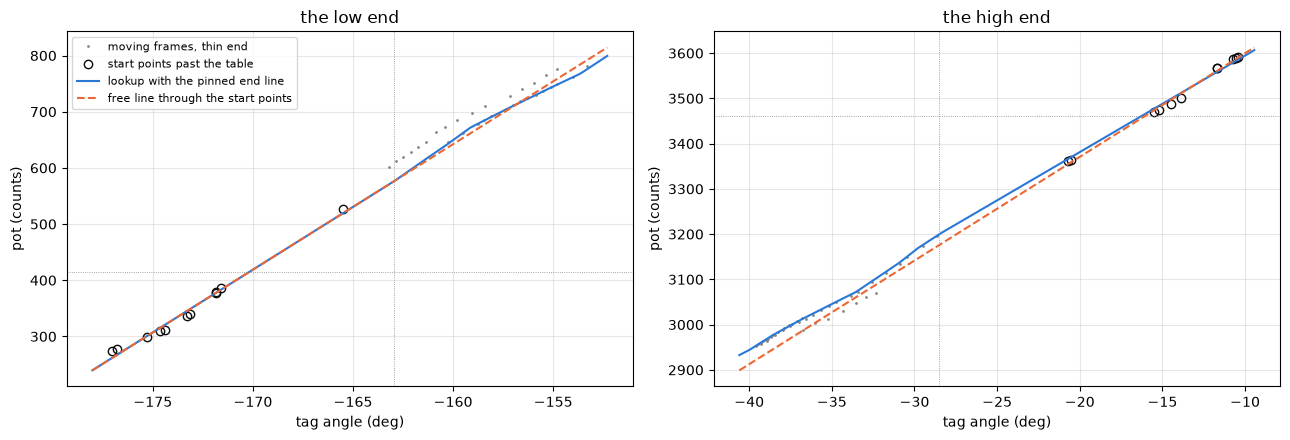

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
for a, end in zip(ax, ("low", "high")):
    q = OUTSIDE[OUTSIDE["end"] == end]
    c0, a0 = (LK.c[0], LK.a[0]) if end == "low" else (LK.c[-1], LK.a[-1])
    side = M[(M["pos"] < INT[0])] if end == "low" else M[M["pos"] > INT[1]]
    th = np.linspace(min(q["image_deg"].min(), side["image_deg"].min()) - 1,
                     max(q["image_deg"].max(), side["image_deg"].max()) + 1,
                     200)
    a.plot(side["image_deg"], side["pos"], ".", ms=2, color=MUTED,
           label="moving frames, thin end")
    a.plot(q["image_deg"], q["pos"], "o", color=INK, mfc="none",
           label="start points past the table")
    a.plot(th, LOOKUP.counts(th), "-", color=BLUE,
           label="lookup with the pinned end line")
    e = ENDS.loc[end]
    a.plot(th, c0 + e["free_step_counts"] + e["slope_free"] * (th - a0),
           "--", color=ORANGE, label="free line through the start points")
    a.axhline(GUARDS[0 if end == "low" else 1], **figures.EDGE_STYLE)
    a.axvline(a0, **figures.EDGE_STYLE)
    figures.label(a, x="tag angle (deg)", y="pot (counts)",
                  title=f"the {end} end")
ax[0].legend(fontsize=8)
figures.finish(fig)

What the figure shows. Each end of the travel, the moving frames of the thin end in gray, the start points past the table as open circles, the lookup with its pinned end line in blue and the free line through the start points dashed. The dotted lines are the guard and the table's last knot. At the low end the two lines lie on top of each other. At the high end the free line steps off the table's end across the hole.

## 5. Stability inside the sitting

Two reads with no timing in them and one with. The rest points through the all-data lookup, with no offset, against the minutes into the sitting. The opening and the closing pass through a lookup fitted on everything else, the crawl, steps and reversal clips, so it saw neither. A pass is a fast drive each way, so its error carries the lash and the timing, both odd in the direction. The mean of the two directions' bin means cancels both, and the closing pass less the opening one is what moved.

In [34]:
LK_NP, _ = pe.build(M[M["kind_clip"] != "pass"],
                    R[R["kind_clip"] != "pass"], PITCH)   # no pass
s = FC[(FC["tag_speed"].abs() > MOVE_DEG_S) & FC["pos_cam"].notna()
       & FC["clip"].isin(["pass-open", "pass-close"])].copy()
s = s[(s["pos_cam"] > LK_NP.c[0]) & (s["pos_cam"] < LK_NP.c[-1])
      & (s["pos"] > LK_NP.c[0]) & (s["pos"] < LK_NP.c[-1])]
s["mdir"] = np.sign(s["tag_speed"]).astype(int)
s["bin"] = (np.floor(s["image_deg"] / 10) * 10).astype(int)
s["e"], s["ec"] = pe.errors(LK_NP, s["pos_cam"], s["image_deg"])
T0 = FC["host"].min()                   # the sitting's first frame


def minutes(clip):
    return (FC[FC["clip"] == clip]["host"].mean() - T0) / 60


B = s.groupby(["clip", "bin", "mdir"]).agg(
    n=("e", "size"), mean=("e", "mean"), sd=("e", "std"),
    meanc=("ec", "mean")).reset_index()
B["se"] = B["sd"] / np.sqrt(B["n"])
P = B.pivot_table(index=["clip", "bin"], columns="mdir",
                  values=["mean", "se", "n", "meanc"])
sym = pd.DataFrame(dict(
    sym=(P["mean"][1] + P["mean"][-1]) / 2,     # cancels lash and timing
    symc=(P["meanc"][1] + P["meanc"][-1]) / 2,
    se=np.sqrt(P["se"][1] ** 2 + P["se"][-1] ** 2) / 2,
    odd=(P["mean"][1] - P["mean"][-1]) / 2)).dropna()
DRIFT = (sym.loc["pass-close"] - sym.loc["pass-open"])[
    ["sym", "symc", "odd"]].dropna()
DRIFT["se"] = np.sqrt(sym.loc["pass-close"]["se"] ** 2
                      + sym.loc["pass-open"]["se"] ** 2).reindex(DRIFT.index)
print(f"lookup without the passes: knots {LK_NP.c[0]:.0f} to "
      f"{LK_NP.c[-1]:.0f}; pass-open at {minutes('pass-open'):.1f} min, "
      f"pass-close at {minutes('pass-close'):.1f} min; frames "
      f"{s.groupby('clip').size().to_dict()}")

lookup without the passes: knots 768 to 3136; pass-open at 0.1 min, pass-close at 14.5 min; frames {'pass-close': 270, 'pass-open': 263}


In [35]:
SE_BINS = DRIFT["sym"].std() / np.sqrt(len(DRIFT))   # se across bins
print(f"close less open, direction-symmetric, {len(DRIFT)} bins of 10 deg"
      f" ({DRIFT.index.min()} to {DRIFT.index.max() + 10} deg): "
      f"{DRIFT['sym'].mean():+.3f} deg ({DRIFT['symc'].mean():+.2f} "
      f"counts), se across bins {SE_BINS:.3f}, sd across bins "
      f"{DRIFT['sym'].std():.2f}")
print("per bin, deg (frame se): " + ", ".join(
    f"{b}: {v:+.2f} ({e:.2f})" for b, v, e in
    zip(DRIFT.index, DRIFT["sym"], DRIFT["se"])))
print(f"direction-odd half difference, lash and timing: open "
      f"{sym.loc['pass-open']['odd'].mean():+.2f}, close "
      f"{sym.loc['pass-close']['odd'].mean():+.2f} deg")
rr = R.copy()
rr["e"], rr["ec"] = pe.errors(LK_ALL, rr["pos"], rr["image_deg"])
rr["min"] = (rr["host"] - T0) / 60
TRENDS = {}
for lab, q in (("all", rr), ("baseline", rr[rr["kind"] == "baseline"]),
               ("coast", rr[rr["kind"] == "coast"])):
    A = np.c_[np.ones(len(q)), q["min"]]
    b = np.linalg.lstsq(A, q["ec"], rcond=None)[0]
    e = q["ec"] - A @ b
    cov = np.linalg.inv(A.T @ A) * e.var(ddof=2)
    TRENDS[lab] = (10 * b[1], 10 * np.sqrt(cov[1, 1]))
    print(f"rest points, {lab}: n {len(q)} over "
          f"{q['min'].max() - q['min'].min():.1f} min, trend "
          f"{10 * b[1]:+.2f} +/- {10 * np.sqrt(cov[1, 1]):.2f} counts per "
          f"10 min ({10 * b[1] / LK_ALL.scale():+.3f} deg), sd about it "
          f"{e.std():.2f} counts")
th = rr["min"].quantile([1 / 3, 2 / 3]).to_numpy()
a, c = rr[rr["min"] <= th[0]]["ec"], rr[rr["min"] >= th[1]]["ec"]
SHIFT = (c.mean() - a.mean(), np.sqrt(a.var() / len(a) + c.var() / len(c)))
print(f"rest points, last third less first: {SHIFT[0]:+.2f} +/- "
      f"{SHIFT[1]:.2f} counts (n {len(a)}, {len(c)}); 2 sigma "
      f"{abs(SHIFT[0]) + 2 * SHIFT[1]:.1f} counts, "
      f"{(abs(SHIFT[0]) + 2 * SHIFT[1]) / LK_ALL.scale():.2f} deg")

close less open, direction-symmetric, 4 bins of 10 deg (-120 to -80 deg): +0.127 deg (+2.31 counts), se across bins 0.140, sd across bins 0.28
per bin, deg (frame se): -120: +0.48 (0.04), -110: +0.11 (0.03), -100: +0.13 (0.03), -90: -0.21 (0.06)
direction-odd half difference, lash and timing: open -0.59, close -0.35 deg
rest points, all: n 75 over 14.5 min, trend -0.12 +/- 0.91 counts per 10 min (-0.006 deg), sd about it 2.77 counts
rest points, baseline: n 21 over 14.4 min, trend -2.01 +/- 1.21 counts per 10 min (-0.103 deg), sd about it 2.26 counts
rest points, coast: n 34 over 14.5 min, trend +1.93 +/- 1.09 counts per 10 min (+0.099 deg), sd about it 2.29 counts
rest points, last third less first: -0.04 +/- 0.83 counts (n 25, 25); 2 sigma 1.7 counts, 0.09 deg


1. No drift is resolved inside the sitting. The rest points move -0.04 +/- 0.83 counts from the first third of the sitting to the last, and their trend is -0.12 +/- 0.91 counts per 10 minutes, so at two sigma the level moved less than 1.7 counts, 0.09 degrees, over 14.5 minutes. Confidence is high for the bound, with 75 points and no timing in it. Stage 3's drift trend of -0.82 counts per 10 minutes is inside one sigma of this one and of zero. The baseline and the coast points alone trend opposite ways, -2.01 +/- 1.21 and +1.93 +/- 1.09 counts per 10 minutes, each under two sigma, which is not a finding.
2. The shape held. The closing pass less the opening one, direction-symmetric, reads +0.127 degrees, +2.31 counts, with a standard error of 0.140 across the 4 bins of 10 degrees the passes share in both directions, far inside the 0.41 degrees of alignment at pass speed. Section 3's table from one pass alone grades the other at 0.141 and 0.218 degrees with the offsets out, the same as the two-fold's 0.165. The passes say no more than that. Their scatter of 0.28 degrees sd over 4 bins is the alignment, not the pot, since each bin is one segment. Confidence is moderate, with 2 chains and 4 shared bins.
3. What one sitting does not say, each a gap at the end. Between sittings, a power cycle, a re-mount or a day, there is no data. Over temperature there is one ambient, 14.5 minutes and no thermometer on the pot. Under side load and torque every frame here is the bare tag horn, and stage 3's hand push, with the pot about 0.5 degrees past the horn, is the only number, on top of 0.39 to 1.12 degrees of play. The lookup returns the gear side's angle, and under load it is off from the horn by up to that bound. The wear of the track has no data.

## 6. The rows at rest and in motion

From here the notebook works row by row. The angle is read through stage 3's table inverted, as the row analysis read it, and the scale from counts to degrees for a noise is stage 3's mid-travel scale. A frame of the camera is matched to the last row at or before its time on the camera's clock, within two ticks, at least 20 ticks into its segment. The stream restarts for each segment, so every estimator runs over the rows of one direction of a chain as one series, and frames in the first 15 ms of a segment are not scored.

### The codes the rows land on

The converter does not output every code equally often. In steady motion, past the first 0.15 s of a segment and faster than 50 counts per second, each segment's count of rows per code is compared with its own running median over 24 codes either side. Pooled over every segment, the ratio is the code's width in units of one code, LSB. A code counts as missing only where the segment's rows cover both sides of it. The codes that matter below are the carries, clusters with a code 3 LSB wide or more or a run of 2 or more missing codes.

In [36]:
NC, HALF, VMIN = 4096, 24, 50.0         # codes; codes either side; counts/s
num, den = {}, {}
for clip, k in CHAINS:
    c, kind = CH[(clip, k)], kind_of(clip)
    dt = tick_s(c)
    for s in np.unique(c["seg"]):
        m = c["seg"] == s
        if s == 0 or np.all(c["duty"][m] == 0):
            continue                    # baselines and coasts out
        p = c["pos"][m]
        sm = uniform_filter1d(p, 200, mode="nearest")   # 10 ms mean
        v = np.zeros(len(p))
        v[200:-200] = (sm[400:] - sm[:-400]) / (400 * dt)   # counts/s
        g = np.abs(v) > VMIN
        g[:3000] = False                # 0.15 s after the segment starts
        if g.sum() < 2000:
            continue
        h = np.bincount(p[g].astype(int), minlength=NC).astype(float)
        med = median_filter(h, 2 * HALF + 1, mode="nearest")
        lo, hi = int(p[g].min()) + HALF, int(p[g].max()) - HALF
        ok = np.zeros(NC, bool)
        ok[lo:hi] = True                # covered on both sides
        ok &= med >= 8
        for key in ("all", kind):
            n_ = num.setdefault(key, np.zeros(NC))
            d_ = den.setdefault(key, np.zeros(NC))
            n_[ok] += h[ok]
            d_[ok] += med[ok]
            num.setdefault(key + "_segs", np.zeros(NC))[ok] += 1
W = {k: np.where(den[k] > 0, num[k] / np.maximum(den[k], 1), np.nan)
     for k in den}                      # width per code, LSB
codes = np.arange(NC)
CODES = pd.DataFrame({"code": codes, "w": W["all"],
                      "expected_rows": den["all"], "segs": num["all_segs"],
                      **{f"w_{k}": W[k] for k in den if k != "all"}})
CODES = CODES[den["all"] > 0]

In [37]:
wa = CODES["w"].to_numpy()
far64 = (np.abs(((CODES["code"] + 32) % 64) - 32) > 12).to_numpy()
FLAT_SD = float(wa[far64].std())        # LSB, away from multiples of 64
print(f"codes covered {len(CODES)}, {CODES['code'].min()} to "
      f"{CODES['code'].max()}, median {CODES['expected_rows'].median():.0f}"
      " rows expected per code")
print(f"width: median {np.median(wa):.3f} LSB, sd {wa.std():.3f}; away "
      f"from multiples of 64 sd {FLAT_SD:.2f} LSB ({wa[far64].min():.2f} to"
      f" {wa[far64].max():.2f}, n {far64.sum()})")


def nanmax(x):
    """The largest finite value, nan when there is none."""
    x = np.asarray(x, float)
    return float(np.nanmax(x)) if np.isfinite(x).any() else np.nan


odd = CODES[(CODES["w"] < 0.35) | (CODES["w"] > 2.0)]
cl = (odd["code"].diff().fillna(99) > 8).cumsum()   # clusters of codes
full = pd.Series(W["all"], index=codes)
clusters = []
for _, g in odd.groupby(cl):
    a, b = int(g["code"].min()), int(g["code"].max())
    span = full.loc[a - 20:b + 20].dropna()
    miss = span[span < 0.1]             # a code that never appears
    clusters.append(dict(
        lo=a, hi=b, n_missing=int(len(miss)),
        missing=",".join(map(str, miss.index[:16])), w_max=float(span.max()),
        w_max_code=int(span.idxmax()),
        w_crawl=nanmax(pd.Series(W["crawl"], index=codes).loc[a - 20:b + 20]),
        w_pass=nanmax(pd.Series(W["pass"], index=codes).loc[a - 20:b + 20]),
        segs=int(num["all_segs"][a:b + 1].min())))
CLUSTERS = pd.DataFrame(clusters)
BIG = CLUSTERS[(CLUSTERS["w_max"] >= 3) | (CLUSTERS["n_missing"] >= 2)]
CAR = BIG["w_max_code"].to_numpy()      # the carries' wide codes
CAR_W = BIG["w_max"].to_numpy()         # their widths, LSB
CAR_NM = BIG["n_missing"].to_numpy()    # the missing codes after each
print(f"{len(CLUSTERS)} clusters, {len(BIG)} carries: "
      f"{[int(c) for c in CAR]}")

codes covered 2483, 620 to 3111, median 248 rows expected per code
width: median 1.022 LSB, sd 0.485; away from multiples of 64 sd 0.29 LSB (0.21 to 2.09, n 1508)
48 clusters, 5 carries: [1023, 1279, 2047, 2303, 2559]


Steady motion covers codes 620 to 3111, about 248 rows expected per code, and away from the multiples of 64 the width has a flat band of 0.29 LSB sd. Five clusters are carries. They are listed and graded in section 7. The noise below only needs to keep clear of them.

### The noise per row

The rest windows, three sources. The torque-off baselines less their head, where the shaft can still ring down from the seek. The last 100 ms of every coast, kept when its line is under 20 counts per second and its 10 ms mean stays within 1.5 counts. The load ladder's still windows, under drive at a standstill, from another sitting. In motion, the crawl and pass drives at under a quarter of full duty, from 0.15 s in to 20 ms before their end, each scored about a quadratic over 20 ms chunks that stay clear of the carries by 16 counts.

In [38]:
HEAD = 4000     # rows, a baseline's head: the shaft rings down from a seek
REST = {"baseline": [], "coast": [], "ladder": [p for _, p in HOLDS]}
MOTION = {"crawl": [], "pass": []}
head_sd, tail_sd, coasts = [], [], 0
for clip, k in CHAINS:
    c = CH[(clip, k)]
    dt = tick_s(c)
    for s in np.unique(c["seg"]):
        m = c["seg"] == s
        p, d = c["pos"][m], c["duty"][m]
        if s == 0:                      # the torque-off baseline
            REST["baseline"].append(p[HEAD:])
            head_sd.append(p[:HEAD].std())
            tail_sd.append(p[HEAD:].std())
        elif np.all(d == 0):            # a coast: its last 100 ms
            t = p[-2000:]
            coasts += 1
            slope = np.polyfit(np.arange(2000) * dt, t, 1)[0]
            if (abs(slope) < 20 and np.ptp(uniform_filter1d(t, 200)
                                           [100:-100]) < 1.5):
                REST["coast"].append(t)
        elif kind_of(clip) in MOTION and np.median(np.abs(d)) < 8000:
            MOTION[kind_of(clip)].append(p[3000:-400])
print(f"baselines {len(REST['baseline'])} less their first {HEAD} rows: "
      "head sd "
      f"{np.mean(head_sd):.2f}, tail sd {np.mean(tail_sd):.2f} counts; "
      f"coast tails kept {len(REST['coast'])} of {coasts}; ladder "
      f"windows {len(REST['ladder'])}; motion segments crawl "
      f"{len(MOTION['crawl'])}, pass {len(MOTION['pass'])}")

baselines 21 less their first 4000 rows: head sd 1.00, tail sd 1.00 counts; coast tails kept 34 of 34; ladder windows 55; motion segments crawl 30, pass 4


In [39]:
def chunk_resid(y, n, order, x=None):
    """y less a polynomial of `order` per chunk of n rows, chunks within
    16 counts of a carry (in x) skipped."""
    out = []
    for a in range(0, len(y) - n + 1, n):
        if x is not None and any(np.any(np.abs(x[a:a + n] - cc) <= 16)
                                 for cc in CAR):
            continue
        t = np.arange(n) - n / 2
        out.append(y[a:a + n] - np.polyval(np.polyfit(t, y[a:a + n], order),
                                           t))
    return np.concatenate(out) if out else np.array([])

In [40]:
ACF_LAGS = [1, 2, 3, 5, 10, 20, 50, 200]    # rows
BLOCKS = [5, 10, 20, 40, 100, 200]          # rows per block mean


def acf(xs, var):
    """Autocorrelation at ACF_LAGS over windows xs, about var."""
    return {l: float(np.mean([np.mean(x[l:] * x[:-l]) for x in xs]) / var)
            for l in ACF_LAGS}


def block_ratio(xs, sd):
    """sd of block means over the independent-rows sd / sqrt(n)."""
    return {n: float(np.sqrt(np.mean([np.var(x[:len(x) // n * n].reshape(
        -1, n).mean(1)) for x in xs])) / (sd / np.sqrt(n))) for n in BLOCKS}


INFO = {}
for name, wins in REST.items():
    e = [w - w.mean() for w in wins]    # each window about its mean
    allr = np.concatenate(e)
    t16 = np.concatenate([np.arange(len(x)) % 16 for x in e])
    m16 = np.array([allr[t16 == i].mean() for i in range(16)])
    m8 = np.array([allr[(t16 % 8) == i].mean() for i in range(8)])
    q = [x - m16[np.arange(len(x)) % 16] for x in e]   # the pattern out
    qa = np.concatenate(q)
    INFO[name] = dict(
        windows=len(wins), rows=len(allr), sd=float(allr.std()),
        sd_window=(min(w.std() for w in wins), max(w.std() for w in wins)),
        acf=acf(e, allr.var()), block=block_ratio(e, allr.std()),
        profile16=m16, pp16=float(np.ptp(m16)), pp8=float(np.ptp(m8)),
        profile_sd=float(m16.std()),
        se16=float(allr.std() / np.sqrt(len(allr) / 16)),
        sd_free=float(qa.std()), acf_free=acf(q, qa.var()),
        block_free=block_ratio(q, qa.std()),
        corr=float(np.corrcoef(m16, INFO["baseline"]["profile16"]
                               if name != "baseline" else m16)[0, 1]))

In [41]:
for name, i in INFO.items():
    share = 1 - (i["sd_free"] / i["sd"]) ** 2   # the pattern's variance
    print(f"{name}: {i['windows']} windows, {i['rows']} rows, sd "
          f"{i['sd']:.3f} counts (windows {i['sd_window'][0]:.2f} to "
          f"{i['sd_window'][1]:.2f}); pattern {i['pp16']:.2f} pp over 16 "
          f"ticks, {i['pp8']:.2f} over 8, sd {i['profile_sd']:.2f}, se "
          f"{i['se16']:.3f}, corr with the baselines' {i['corr']:.3f}; "
          f"sd with it out {i['sd_free']:.3f}, {100 * share:.0f} % of the "
          "variance")
for name in ("acf", "acf_free", "block", "block_free"):
    print(name.replace("_free", " less the pattern") + ": " + "; ".join(
        f"{src} " + " ".join(f"{k}:{v:+.2f}" for k, v in i[name].items())
        for src, i in INFO.items()))
print("the 16-tick pattern at rest, counts: "
      + " ".join(f"{v:+.2f}" for v in INFO["baseline"]["profile16"]))
i0 = int(np.argmin([w.std() for w in REST["baseline"]]))
w0 = REST["baseline"][i0]               # the stillest baseline window
print(f"the stillest baseline, {CHAINS[i0][0]} chain {CHAINS[i0][1]}: sd "
      f"{w0.std():.2f} counts on code {np.median(w0):.0f}")

baseline: 21 windows, 126000 rows, sd 1.031 counts (windows 0.00 to 1.45); pattern 3.01 pp over 16 ticks, 2.32 over 8, sd 0.85, se 0.012, corr with the baselines' 1.000; sd with it out 0.585, 68 % of the variance
coast: 34 windows, 68000 rows, sd 1.027 counts (windows 0.59 to 1.55); pattern 3.01 pp over 16 ticks, 2.30 over 8, sd 0.84, se 0.016, corr with the baselines' 0.997; sd with it out 0.590, 67 % of the variance
ladder: 55 windows, 110000 rows, sd 1.160 counts (windows 0.52 to 2.81); pattern 2.99 pp over 16 ticks, 2.32 over 8, sd 0.84, se 0.014, corr with the baselines' 0.984; sd with it out 0.804, 52 % of the variance
acf: baseline 1:+0.52 2:+0.04 3:-0.44 5:-0.49 10:-0.02 20:-0.62 50:+0.05 200:+0.59; coast 1:+0.52 2:+0.03 3:-0.43 5:-0.47 10:-0.03 20:-0.60 50:+0.04 200:+0.58; ladder 1:+0.49 2:+0.02 3:-0.41 5:-0.45 10:-0.00 20:-0.55 50:+0.04 200:+0.54
acf less the pattern: baseline 1:+0.15 2:+0.02 3:-0.11 5:-0.14 10:+0.03 20:-0.08 50:+0.04 200:+0.18; coast 1:+0.16 2:+0.02 3:-0.10 

1. The rows at rest scatter by 1.031 counts sd on the baselines, 1.027 on the coast tails and 1.160 on the load ladder's windows under drive. Per window the sd runs from 0.00 to 1.45 counts on the baselines and from 0.52 to 2.81 on the ladder. The 0.00 is the reversal clip's baseline parked on code 2047, the widest code of the mid carry. A wide code reads still.
2. The rows are not independent. 68 % of the baselines' variance is one pattern locked to the tick with a period of 16 ticks, 3.01 counts peak to peak and 0.85 counts sd, with a standard error of 0.012 per tick. The coast tails carry the same shape (correlation 0.997) and so do the ladder's windows under drive in another sitting (0.984, 2.99 counts peak to peak). Stage 1 found 3.025 counts peak to peak with a resistor divider in the pot's place, and 0.66 counts sd with the pattern removed. The pattern is the board's, not the pot's, at high confidence.
3. The raw rows correlate at +0.52 at lag 1, -0.44 at 3, -0.49 at 5, -0.62 at 20 and +0.59 at 200 ticks, and the correlation does not decay, so a short mean of raw rows is not the sd over the square root of its length. Block means read 1.13 of the independent-rows prediction at 5 rows, 0.80 at 10 and 0.61 to 0.78 at 200 over the three sources.
4. With the pattern taken out the rows are close to independent. The block means read 0.91 to 1.16 of the prediction for 5 to 100 rows on all three sources. The 1.29 at 200 rows on the coast tails is the shaft's slow drift. A small residue remains, +0.15 to +0.28 at lag 1 and +0.18 to +0.23 at lag 200, since the pattern's size differs a little from window to window.

The spectrum of the rest rows, Welch's average over a stretch of each baseline window about its own line, and the outliers once the pattern is taken out.

In [42]:
seg_ = [w[:1500] - w[:1500].mean() for w in REST["baseline"]]
f, Pw = welch(np.concatenate(seg_), fs=1 / DT, nperseg=1500, noverlap=0,
              detrend="linear")
pk = int(np.argmax(Pw[1:])) + 1         # the strongest line past DC
bands = [(0, 100), (100, 1000), (1000, 5000), (5000, 10001)]
shares = [100 * Pw[(f >= a) & (f < b)].sum() / Pw.sum() for a, b in bands]
print("Welch over the first 1500 rows of each baseline window")
print(f"strongest line {f[pk]:.0f} Hz, period {1 / (f[pk] * DT):.1f} "
      f"ticks, {Pw[pk] / np.median(Pw):.0f} x the median bin; power by "
      "band: " + ", ".join(f"{a} to {b} Hz {v:.1f} %"
                           for (a, b), v in zip(bands, shares)))
OUTLIERS = {}
for name, wins in REST.items():
    prof = INFO[name]["profile16"]
    q = np.concatenate([w - w.mean() - prof[np.arange(len(w)) % 16]
                        for w in wins])
    OUTLIERS[name] = dict(over3=float(np.mean(np.abs(q) > 3)),
                          over5=float(np.mean(np.abs(q) > 5)),
                          max_abs=float(np.abs(q).max()),
                          kurtosis=float(np.mean(q ** 4) / q.var() ** 2),
                          rows=len(q))
    o = OUTLIERS[name]
    print(f"{name}, pattern out: {100 * o['over3']:.3f} % of rows over 3 "
          f"counts ({int(round(o['over3'] * o['rows']))} rows), "
          f"{100 * o['over5']:.3f} % over 5, max {o['max_abs']:.1f}, "
          f"kurtosis {o['kurtosis']:.1f}, {o['rows']} rows")
for name, segs in MOTION.items():
    r = np.concatenate([chunk_resid(p, 400, 2, p) for p in segs])
    a = acf([r], r.var())
    INFO["motion_" + name] = dict(segments=len(segs), rows=len(r),
                                  sd=float(r.std()))
    print(f"in motion, {name}: {len(segs)} segments, {len(r)} rows, sd "
          f"{r.std():.3f} about a 20 ms quadratic, autocorrelation "
          + " ".join(f"{k}:{v:+.2f}" for k, v in a.items()))

Welch over the first 1500 rows of each baseline window
strongest line 2490 Hz, period 8.0 ticks, 936 x the median bin; power by band: 0 to 100 Hz 0.4 %, 100 to 1000 Hz 2.3 %, 1000 to 5000 Hz 83.3 %, 5000 to 10001 Hz 13.9 %
baseline, pattern out: 0.000 % of rows over 3 counts (0 rows), 0.000 % over 5, max 2.8, kurtosis 3.2, 126000 rows
coast, pattern out: 0.001 % of rows over 3 counts (1 rows), 0.000 % over 5, max 3.2, kurtosis 3.3, 68000 rows
ladder, pattern out: 0.301 % of rows over 3 counts (331 rows), 0.149 % over 5, max 17.8, kurtosis 38.4, 110000 rows


in motion, crawl: 30 segments, 533600 rows, sd 1.036 about a 20 ms quadratic, autocorrelation 1:+0.51 2:+0.05 3:-0.38 5:-0.42 10:+0.02 20:-0.56 50:+0.03 200:+0.57
in motion, pass: 4 segments, 50400 rows, sd 1.247 about a 20 ms quadratic, autocorrelation 1:+0.66 2:+0.34 3:+0.03 5:-0.00 10:+0.28 20:-0.19 50:+0.01 200:+0.42


5. The pattern's strongest line is 2490 Hz, a period of 8 ticks, 936 times the median bin, and 83.3 % of the power sits between 1 and 5 kHz.
6. With the pattern out there are no outliers at rest. No baseline row of 126000 lies over 3 counts, the largest is 2.8 and the kurtosis 3.2, and 1 coast row of 68000 does. Under drive on the ladder 0.301 % of rows lie over 3 counts and 0.149 % over 5, at most 17.8, with a kurtosis of 38.4. The candidate cause is a hold parked on the edge of a carry, flipping between the wide code and the first code past the gap, which section 7 scores.
7. In motion at a crawl the rows about a 20 ms quadratic have the same sd and the same correlation as at rest, 1.036 counts, +0.51 at lag 1, -0.38 at 3, -0.56 at 20, +0.57 at 200, so the pattern rides along unchanged. On the passes the residual is larger, 1.247, and smoother, +0.66 at lag 1. There the code-width texture and the track's texture cross a 20 ms window, and they are not noise.

### The filter table

The candidates are causal filters of the rows in `oscnb.position`. A boxcar is the mean of the last n rows. A one-pole filter is $y \mathrel{+}= a\,(x - y)$ with $a = 1 / (1 + d)$ for a DC delay of $d$ ticks, with $y$ the output, $x$ the row and $a$ its gain. A median of 3 takes the last 3 rows, and it is also tried ahead of each of the others. A filter's noise is the sd of its output over each rest window from 20 ms in, pooled as a root mean square over windows. In motion it is the sd about a 20 ms quadratic, as above. The delay is the DC group delay in ticks, confirmed on the pass rows as the mean of a centered 20 ms mean less the output over the slope. The lag is that delay times a speed, 15 degrees per second for a crawl and the passes' mean tag speed.

In [43]:
def filters():
    """(name, DC delay in ticks, the filter) for every candidate."""
    yield "none", 0.0, lambda x: x
    for n in (5, 8, 10, 16, 20, 40, 80, 100, 200):
        yield f"boxcar {n}", (n - 1) / 2, lambda x, n=n: pe.boxcar(x, n)
    for n in (5, 10, 20, 40, 100, 200):
        yield f"one-pole {n}", float(n), lambda x, n=n: pe.one_pole(x, n)
    yield "median 3", 1.0, pe.median3
    for n in (8, 16, 40, 200):
        yield (f"median 3 + boxcar {n}", 1 + (n - 1) / 2,
               lambda x, n=n: pe.boxcar(pe.median3(x), n))
    for n in (5, 20, 100):
        yield (f"median 3 + one-pole {n}", 1.0 + n,
               lambda x, n=n: pe.one_pole(pe.median3(x), n))


pf = PF.frames[PF.frames["clip"].str.startswith("pass")
               & (PF.frames["step"] == "20@915")
               & (PF.frames["t_seg"] > 0.15)]
pass_speed = [abs(np.polyfit(g["host"], g["image_deg"], 1)[0]) for _, g in
              pf.dropna(subset=["image_deg"]).groupby(["clip", "k", "seg"])]
pass_speed = [v for v in pass_speed if np.isfinite(v)]
V_PASS, V_CRAWL = float(np.mean(pass_speed)), 15.0   # deg/s
SKIP_ROWS = 400                         # rows, a filter's first 20 ms out
print(f"pass drives: {np.mean(pass_speed):.1f} deg/s on the tag "
      f"({min(pass_speed):.1f} to {max(pass_speed):.1f}, n "
      f"{len(pass_speed)}); crawl lag at {V_CRAWL:.0f} deg/s")

pass drives: 101.5 deg/s on the tag (97.3 to 105.0, n 4); crawl lag at 15 deg/s


In [44]:
frows = []
for name, delay, fn in filters():
    row = dict(filter=name, delay_ticks=delay, delay_ms=delay * DT * 1e3)
    for src, wins in REST.items():
        row[f"rest_{src}_counts"] = float(np.sqrt(np.mean(
            [np.var(fn(w)[SKIP_ROWS:]) for w in wins])))
    for src, segs in MOTION.items():
        r = np.concatenate([chunk_resid(fn(p)[400:], 400, 2, p[400:])
                            for p in segs])
        row[f"motion_{src}_counts"] = float(r.std())
    lag = []
    for p in MOTION["pass"]:            # the delay, measured on the passes
        ref = uniform_filter1d(p, 401, mode="nearest")
        v, y, s_ = np.gradient(ref), fn(p), slice(1000, -1000)
        lag.append(np.mean((ref[s_] - y[s_]) / v[s_]))
    row["delay_measured_ticks"] = float(np.mean(lag))
    row["rest_deg"] = row["rest_baseline_counts"] / SCALE
    row["lag_crawl_deg"] = delay * DT * V_CRAWL
    row["lag_pass_deg"] = delay * DT * V_PASS
    frows.append(row)
FILTERS = pd.DataFrame(frows)
print(f"boxcar 16 spans {16 * DT * 1e3:.2f} ms; independent rows of the "
      f"pattern-free sd predict {INFO['baseline']['sd_free'] / 4:.3f} "
      "counts for it")
show(FILTERS[["filter", "delay_ticks", "delay_measured_ticks", "delay_ms",
              "rest_baseline_counts", "rest_coast_counts",
              "rest_ladder_counts", "motion_crawl_counts",
              "motion_pass_counts", "rest_deg", "lag_crawl_deg",
              "lag_pass_deg"]], n=None)

boxcar 16 spans 0.80 ms; independent rows of the pattern-free sd predict 0.146 counts for it


,filter,delay_ticks,delay_measured_ticks,delay_ms,rest_baseline_counts,rest_coast_counts,rest_ladder_counts,motion_crawl_counts,motion_pass_counts,rest_deg,lag_crawl_deg,lag_pass_deg
0,none,0.000,0.064,0.000,1.031,1.029,1.135,1.036,1.243,0.055,0.000,0.000
1,boxcar 5,2.000,1.996,0.100,0.520,0.519,0.561,0.537,0.873,0.027,0.002,0.010
2,boxcar 8,3.500,3.555,0.175,0.254,0.257,0.278,0.308,0.752,0.013,0.003,0.018
3,boxcar 10,4.500,4.541,0.225,0.260,0.262,0.285,0.317,0.752,0.014,0.003,0.023
4,boxcar 16,7.500,7.537,0.376,0.139,0.144,0.161,0.238,0.712,0.007,0.006,0.038
5,boxcar 20,9.500,9.515,0.476,0.171,0.174,0.190,0.253,0.710,0.009,0.007,0.048
6,boxcar 40,19.500,19.496,0.976,0.098,0.102,0.109,0.202,0.646,0.005,0.015,0.099
7,boxcar 80,39.500,39.430,1.978,0.069,0.071,0.076,0.166,0.533,0.004,0.030,0.201
8,boxcar 100,49.500,49.403,2.478,0.067,0.069,0.075,0.152,0.482,0.004,0.037,0.252
9,boxcar 200,99.500,99.357,4.982,0.045,0.048,0.058,0.087,0.276,0.002,0.075,0.506


The motion columns are the sd about a 20 ms quadratic with the carries left out. They hold the code-width and track texture and the real speed ripple as well as noise, and the 20 ms fit hides whatever a long filter leaves below 50 Hz, so they bound the short filters only, to about 2 ms. The ladder's 0.165 for the one-pole of 200 ticks is the hold creeping inside a 100 ms window, not noise. The measured delays agree with the DC delays to within 0.15 tick, except the one-pole of 200 ticks at 202.284.

The noise against the delay, at rest and in a crawl, with the independent-rows line, the unfiltered sd over the square root of the rows a boxcar of that delay averages.

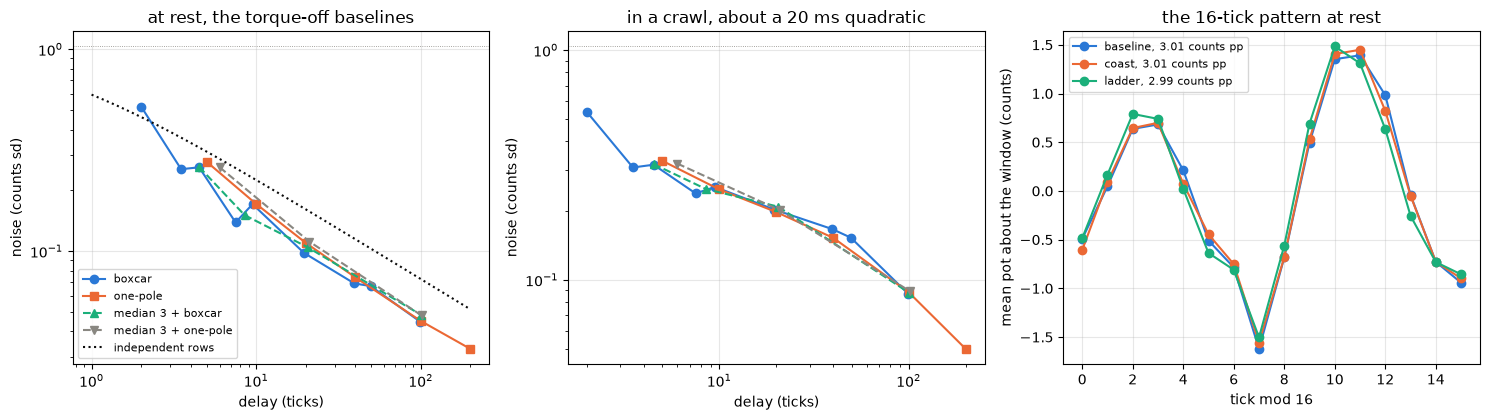

In [45]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
fams = (("boxcar", BLUE, "o-"), ("one-pole", ORANGE, "s-"),
        ("median 3 + boxcar", GREEN, "^--"),
        ("median 3 + one-pole", MUTED, "v--"))
for fam, color, mk in fams:
    g = FILTERS[FILTERS["filter"].str.startswith(fam + " ")]
    if fam == "boxcar":
        g = FILTERS[FILTERS["filter"].str.match(r"boxcar \d")]
    ax[0].loglog(g["delay_ticks"], g["rest_baseline_counts"], mk,
                 color=color, label=fam)
    ax[1].loglog(g["delay_ticks"], g["motion_crawl_counts"], mk,
                 color=color, label=fam)
n0 = FILTERS.iloc[0]
d = np.logspace(0, 2.3, 30)
ax[0].loglog(d, n0["rest_baseline_counts"] / np.sqrt(2 * d + 1), ":",
             color=INK, label="independent rows")
for a, col in ((ax[0], "rest_baseline_counts"),
               (ax[1], "motion_crawl_counts")):
    a.axhline(n0[col], **figures.EDGE_STYLE)
figures.label(ax[0], x="delay (ticks)", y="noise (counts sd)",
              title="at rest, the torque-off baselines")
figures.label(ax[1], x="delay (ticks)", y="noise (counts sd)",
              title="in a crawl, about a 20 ms quadratic")
ax[0].legend(fontsize=8)
for name, color in (("baseline", BLUE), ("coast", ORANGE),
                    ("ladder", GREEN)):
    ax[2].plot(range(16), INFO[name]["profile16"], "o-", color=color,
               label=f"{name}, {INFO[name]['pp16']:.2f} counts pp")
figures.label(ax[2], x="tick mod 16", y="mean pot about the window (counts)",
              title="the 16-tick pattern at rest")
ax[2].legend(fontsize=8)
figures.finish(fig)

What the figure shows. Left, each filter's noise at rest against its delay, by family, with the dotted line of independent rows. The boxcars dip below it at lengths that are multiples of 8 and 16 ticks. Middle, the same in a crawl, where the texture sets a floor. Right, the mean pot by tick modulo 16 in each rest source, the pattern the boxcars null.

1. A boxcar whose length is a multiple of 16 ticks nulls the pattern, and a length of 8 takes most of it. Boxcar 16, 0.80 ms long and 7.5 ticks of delay, leaves 0.139 counts at rest, 0.007 degrees, against 0.146 for independent rows of the pattern-free 0.585. Boxcar 20 is worse than 16 at 0.171, and boxcar 10 no better than 8 at 0.260 against 0.254. Confidence is high, from three sources over two sittings with a stage 1 match.
2. A one-pole needs about 1.3 times the delay of a boxcar for the same noise up to 1 ms. The one-pole of 10 ticks reads 0.171 counts, boxcar 16 reads 0.139 at 7.5 ticks. From 2 ms up the two match. Confidence is high at rest.
3. A median of 3 ahead of either filter buys nothing and costs a tick. It reads 0.261 against 0.254 ahead of boxcar 8 and 0.151 against 0.139 ahead of boxcar 16, since at rest there are no spikes for it to remove. Confidence is moderate for its use under drive, where the ladder's outliers are scored in section 7.
4. The noise floor is not what limits the position reading. Every filter from 0.4 ms up reads under 0.015 degrees at rest, against 0.16 degrees of tag grade and the larger terms of sections 7 and 8. The choice is a choice of delay. At the passes' 101.5 degrees per second boxcar 16 lags 0.038 degrees, boxcar 40 0.099 and boxcar 200 0.506. At a crawl at 15 degrees per second every boxcar up to 5 ms and every one-pole up to 2 ms lags under 0.04 degrees.
5. The proposal for stage 5's feedback is boxcar 16, 0.376 ms of delay, or boxcar 32 if more smoothing is wanted, and never a length that is not a multiple of 8. The table is the deliverable and stage 5 picks from it. It is written beside the result file as `filters.csv`.

### Every estimator at every frame

Each chain's rows of one direction, from segment 1 on, run through every candidate as one series, then sampled at the camera's frames. The candidates are the raw rows, boxcars of 16, 40 and 200, the hold at the carries alone and with a boxcar of 16 after it, the direction from the duty's sign and from the pot's own motion with 2 to 12 counts of hysteresis on the boxcar of 16, and a play operator on the angle with half widths of 0.10 to 0.25 degrees. A frame also carries its time from the chain's duty flip and from the pot's turn after it, for the reversals.

In [46]:
HYST = (2, 4, 6, 8, 12)                 # counts, the pot direction's
HALVES = (0.10, 0.14, 0.17, 0.20, 0.25)  # deg, the play operator's
SKIP = 20                               # ticks into a segment, at least
HOLD_HALF = 12.0                        # counts, the hold's band
fr = PF.frames[PF.frames["seg"] > 0].dropna(subset=["image_deg"])


def estimators(x, duty):
    """Every candidate run down one direction's rows."""
    b16 = pe.boxcar(x, 16)
    hold, band = pe.carry_hold(x, CAR, HOLD_HALF)
    est = {"none": x, "box16": b16, "box40": pe.boxcar(x, 40),
           "box200": pe.boxcar(x, 200), "hold": hold,
           "hold_box16": pe.boxcar(hold, 16), "band": band.astype(float),
           "d_duty": pe.dir_from_duty(duty), "duty": duty}
    for h in HYST:
        est[f"d_pot{h}"] = pe.dir_from_pot(b16, h)
    th16 = LOOKUP3(b16)                 # deg, through stage 3's table
    for b in HALVES:
        est[f"play{int(b * 100)}"] = pe.play(th16, b)
    return est, b16

In [47]:
parts = []
for clip, k in CHAINS:
    c = CH[(clip, k)]
    dt = tick_s(c)
    for gd in (1.0, -1.0):
        m = (c["dir"] == gd) & (c["seg"] > 0)
        f = fr[(fr["clip"] == clip) & (fr["k"] == k) & (fr["dir"] == gd)]
        if not m.any() or f.empty:
            continue
        x, cam, seg = c["pos"][m], c["cam"][m], c["seg"][m]
        tick, duty = c["tick"][m], c["duty"][m]
        est, b16 = estimators(x, duty)
        f = f.copy()
        i = np.searchsorted(cam, f["host"].to_numpy(), side="right") - 1
        ok = (i >= 0) & (f["host"].to_numpy() - cam[np.maximum(i, 0)]
                         < 2 * dt)       # a row at or before, two ticks
        i = np.maximum(i, 0)
        ok &= (seg[i] == f["seg"].to_numpy()) & (tick[i] >= SKIP)
        f, i = f[ok], i[ok]
        for name, v in est.items():
            f[name] = v[i]
        f["kind"], f["gd"] = kind_of(clip), gd
        flip = np.flatnonzero((np.diff(np.sign(duty)) != 0)
                              & (duty[1:] != 0) & (duty[:-1] != 0)) + 1
        f["t_flip"] = f["host"] - cam[flip[0]] if len(flip) else np.nan
        if len(flip):                   # the pot's turn after the flip
            j = flip[0] + (np.argmax(b16[flip[0]:]) if gd > 0
                           else np.argmin(b16[flip[0]:]))
            f["t_turn"] = f["host"] - cam[j]
        else:
            f["t_turn"] = np.nan
        parts.append(f)
FE = pd.concat(parts, ignore_index=True)
FE["speed"] = FE["pos_speed"] / SCALE   # deg/s, the pot's 10 ms slope
FE["move"] = np.sign(FE["speed"]) * (FE["speed"].abs() > 2)
r40 = LOOKUP3(FE["box40"]) - FE["image_deg"]
mv = (FE["speed"].abs() > 2) & r40.notna()
print(f"{len(FE)} of {len(fr)} frames matched to a row, {int(mv.sum())} "
      f"moving over 2 deg/s; the 2 ms boxcar less the tag {rms(r40[mv]):.3f}"
      f" deg rms, mean {r40[mv].mean():+.3f}")

11271 of 11435 frames matched to a row, 7884 moving over 2 deg/s; the 2 ms boxcar less the tag 0.436 deg rms, mean -0.024


11271 of the 11435 frames in driven segments match a row. Through the 2 ms boxcar the 7884 moving frames read 0.436 degrees rms against the tag with the lead applied, mean -0.024, the size of section 3's 0.410 with nothing out.

## 7. The carries

### Where they are

Every carry is a multiple of 256 less one. The code before the carry is wide, and a run of codes after it never appears. The reading stands still on the wide code while the horn moves, then jumps the missing run. The horn's travel on the wide code, its width less one code over the scale, is the span over which the angle is blind.

In [48]:
BLIND = (CAR_W - 1) / SCALE             # deg the horn moves on one reading
CARRIES = pd.DataFrame({
    "wide code": CAR, "width LSB": CAR_W, "missing after it": CAR_NM,
    "missing": BIG["missing"].to_numpy(),
    "jump counts": CAR_NM + 1, "jump deg": (CAR_NM + 1) / SCALE,
    "blind deg": BLIND, "crawl width": BIG["w_crawl"].to_numpy(),
    "pass width": BIG["w_pass"].to_numpy(),
    "segments": BIG["segs"].to_numpy(),
    "stage 3 tag deg": [WIDE3.get(int(c), np.nan) for c in CAR]})
show(CARRIES, n=None)
sigma = (CAR_W - 1) / FLAT_SD           # over the flat band of widths
print("width over the flat band: " + ", ".join(
    f"{c} {s:.0f} sigma" for c, s in zip(CAR, sigma)))
others = [c for c in range(255, 4096, 256)
          if CODES["code"].min() <= c <= CODES["code"].max()
          and c not in CAR]
print(f"multiples of 256 less one inside the cover with no carry: {others}")
print(f"half the largest blind span: {BLIND.max() / 2:.2f} deg")
reach = (STATIC["pos"].min(), STATIC["pos"].max())     # the pot's reach
untested = [c for c in range(255, 4096, 256) if reach[0] <= c <= reach[1]
            and not CODES["code"].min() <= c <= CODES["code"].max()]
print(f"inside the pot's reach but outside the cover: {untested}")

,wide code,width LSB,missing after it,missing,jump counts,jump deg,blind deg,crawl width,pass width,segments,stage 3 tag deg
0,1023,15.606,12,"1024,1025,1026,1027,1028,1029,1030,1031,1032,1...",13,0.687,0.772,16.208,15.938,6,0.623
1,1279,3.628,3,"1280,1281,1282",4,0.211,0.139,3.649,3.550,9,0.195
2,2047,9.830,11,"2048,2049,2050,2051,2052,2053,2054,2055,2056,2...",12,0.634,0.467,9.486,11.909,11,0.714
3,2303,1.563,3,"2304,2305,2306",4,0.211,0.030,1.561,1.889,15,NaN
4,2559,6.280,7,"2560,2561,2562,2563,2564,2565,2566",8,0.423,0.279,6.493,7.222,12,0.323


width over the flat band: 1023 50 sigma, 1279 9 sigma, 2047 30 sigma, 2303 2 sigma, 2559 18 sigma
multiples of 256 less one inside the cover with no carry: [767, 1535, 1791, 2815, 3071]
half the largest blind span: 0.39 deg
inside the pot's reach but outside the cover: [511, 3327, 3583]


Five carries sit inside the covered codes, at 1023, 1279, 2047, 2303 and 2559. The two large ones stand 50 and 30 sigma over the flat band of the widths. The crawl-only and pass-only widths agree, so each is seen again on independent rows. At 767, 1535, 1791, 2815 and 3071 no run of missing codes shows. Below 620 and above 3111 nothing is covered, so carries at 511, 3327 or 3583 are untested. Confidence is high for the list inside the cover. Stage 3 scored the horn's travel on each wide code against the tag and put 2047 at 0.71 degrees and 1023 at 0.62, where the code widths here give 0.467 and 0.772. The two constructions differ, and the pair is taken up with the discrepancies.

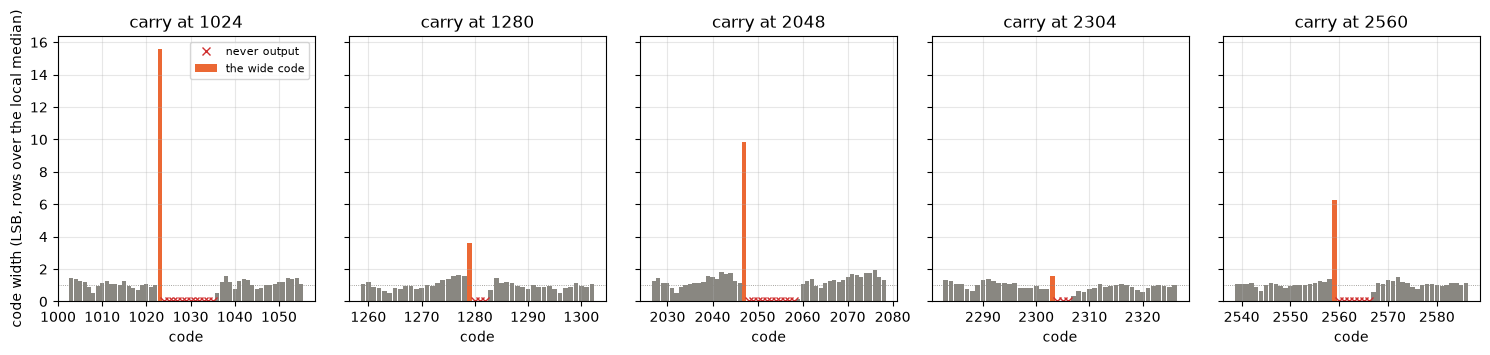

In [49]:
fig, ax = plt.subplots(1, len(CAR), figsize=(15, 3.6), sharey=True)
for a, c, nm in zip(ax, CAR, CAR_NM):
    near = CODES[(CODES["code"] >= c - 20) & (CODES["code"] <= c + nm + 20)]
    a.bar(near["code"], near["w"], width=0.9, color=MUTED)
    a.bar([c], near.loc[near["code"] == c, "w"], width=0.9, color=ORANGE,
          label="the wide code")
    gone = near[near["w"] < 0.1]
    a.plot(gone["code"], np.zeros(len(gone)), "x", color=RED,
           label="never output")
    a.axhline(1, **figures.EDGE_STYLE)
    figures.label(a, x="code", title=f"carry at {c + 1}")
ax[0].set_ylabel("code width (LSB, rows over the local median)")
ax[0].legend(fontsize=8)
figures.finish(fig)

What the figure shows. The width of every code within 20 of each carry, as the rows per code over the local median, with the wide code in orange and the codes never output marked with a cross. The dotted line is one code's width. Each carry is a wide code followed by a gap.

### What each estimator reads there, against the tag

Frames moving over 2 degrees per second, coasts left out, more than 15 ms into a segment. Each segment's median residual away from the carries, more than 40 counts off, is taken out, so the lead and the direction term do not enter. A frame is near a carry from 12 counts before the wide code to 12 past the missing run. The lag is the mean residual along the motion, negative behind. Slow is the crawl, steps and reversal clips, pass the passes.

In [50]:
EST = ["none", "box16", "box40", "box200", "hold", "hold_box16"]
FN = FE[(FE["speed"].abs() > 2) & FE["step"].ne("coast:300")
        & (FE["t_seg"] > 0.015)].copy()
x = FN["none"].to_numpy()
dist = np.abs(x[:, None] - CAR[None, :])
near_i = np.argmin(dist, axis=1)        # the nearest carry
FN["carry"] = CAR[near_i]
FN["off"] = x - CAR[near_i]             # counts past the wide code
FN["near"] = (FN["off"] >= -12) & (FN["off"] <= CAR_NM[near_i] + 12)
FN["far"] = dist.min(axis=1) > 40
FN["slow"] = np.where(FN["kind"] == "pass", "pass", "slow")
r0 = LOOKUP3(FN["none"]) - FN["image_deg"]
cs = r0[FN["far"]].groupby([FN["clip"], FN["k"], FN["seg"]]).median()
FN = FN.join(cs.rename("cs"), on=["clip", "k", "seg"])
crows = []
for e in EST:
    FN["d_" + e] = LOOKUP3(FN[e]) - FN["image_deg"] - FN["cs"]
    for sl, g in FN.groupby("slow"):
        far = g[g["far"]]["d_" + e].dropna()
        near = g[g["near"]]["d_" + e].dropna()
        s_far = np.sign(g[g["far"]]["speed"])[far.index]
        s_near = np.sign(g[g["near"]]["speed"])[near.index]
        crows.append(dict(
            estimator=e, kind=sl, far_n=len(far),
            far_lag_deg=float((far * s_far).mean()),
            far_sd=float(far.std()), near_n=len(near),
            near_lag_deg=float((near * s_near).mean()),
            near_rms=float(np.sqrt((near ** 2).mean())),
            near_p95=float(near.abs().quantile(0.95)),
            near_max=float(near.abs().max()),
            speed=float(g["speed"].abs().median())))
AT_CARRY = pd.DataFrame(crows)
show(AT_CARRY, n=None)

,estimator,kind,far_n,far_lag_deg,far_sd,near_n,near_lag_deg,near_rms,near_p95,near_max,speed
0,none,pass,438,-0.001,0.207,31,-0.014,0.207,0.386,0.752,100.360
1,none,slow,5828,0.003,0.176,494,-0.002,0.201,0.418,0.785,29.595
2,box16,pass,437,-0.038,0.205,31,-0.042,0.209,0.386,0.752,100.360
3,box16,slow,5827,-0.013,0.169,494,-0.014,0.192,0.403,0.744,29.595
4,box40,pass,437,-0.098,0.226,31,-0.097,0.228,0.426,0.752,100.360
5,box40,slow,5823,-0.039,0.177,494,-0.039,0.198,0.416,0.707,29.595
6,box200,pass,436,-0.501,0.547,31,-0.495,0.516,0.704,0.865,100.360
7,box200,slow,5816,-0.209,0.334,494,-0.207,0.326,0.663,1.218,29.595
8,hold,pass,438,-0.001,0.207,31,-0.441,0.658,1.271,1.646,100.360
9,hold,slow,5828,0.003,0.176,494,-0.487,0.698,1.368,1.836,29.595


In [51]:
pc = []
for c, w, nm in zip(CAR, CAR_W, CAR_NM):
    g = FN[(FN["carry"] == c) & FN["near"] & (FN["slow"] == "slow")]
    d = (g["d_none"] * np.sign(g["speed"])).dropna()
    pc.append(dict(code=int(c), n=len(d), rms=float(np.sqrt((d ** 2).mean())),
                   worst_behind=float(d.min()), worst_ahead=float(d.max()),
                   crossings=g.groupby(["clip", "k", "seg"]).ngroups))
PER_CARRY = pd.DataFrame(pc)
show(PER_CARRY, n=None)
slow = AT_CARRY[(AT_CARRY["estimator"] == "none")
                & (AT_CARRY["kind"] == "slow")].iloc[0]
ratio = slow["near_rms"] ** 2 / slow["far_sd"] ** 2
print(f"nothing done, slow: near {slow['near_rms']:.3f} against far "
      f"{slow['far_sd']:.3f} deg, variance ratio {ratio:.2f}, "
      f"{np.sqrt(slow['near_rms'] ** 2 - slow['far_sd'] ** 2):.2f} deg "
      f"in quadrature, {PER_CARRY['crossings'].sum()} crossings")
hold = AT_CARRY[(AT_CARRY["estimator"] == "hold")
                & (AT_CARRY["kind"] == "slow")].iloc[0]
x_worse = hold["near_rms"] / slow["near_rms"]
print(f"the hold over the near frames: {x_worse:.1f} x nothing done")

,code,n,rms,worst_behind,worst_ahead,crossings
0,1023,62,0.210,-0.502,0.487,13
1,1279,75,0.209,-0.394,0.558,11
2,2047,162,0.245,-0.636,0.785,17
3,2303,90,0.155,-0.373,0.280,17
4,2559,105,0.142,-0.404,0.309,15


nothing done, slow: near 0.201 against far 0.176 deg, variance ratio 1.31, 0.10 deg in quadrature, 73 crossings
the hold over the near frames: 3.5 x nothing done


1. With nothing done the reading stands still on the wide code and then jumps the missing run. The code widths bound it. The horn moves 0.772 degrees under one reading at 1023, 0.467 at 2047, 0.279 at 2559, 0.139 at 1279 and 0.030 at 2303, so around the lookup the angle is off by up to half of that, 0.39 degrees at worst. Against the tag the carries add little. At slow speed the frames near a carry read 0.201 degrees rms against 0.176 far from one, a variance ratio of 1.31 on 494 frames, 0.10 degrees in quadrature, and on the passes nothing is resolved, 0.207 against 0.207 on 31 frames. Per carry the rms is 0.142 to 0.245 degrees, the worst single frames -0.636 and +0.785 degrees at 2047, about three far sd and so not a measured bound. Confidence is high that the bound is the code widths and moderate for the 0.10 degrees, which sits under the tag's grade.
2. The hold across 12 counts either side of a carry is 3.5 times worse than nothing for position, 0.698 degrees rms near a carry and up to 1.836, 0.487 degrees behind on average, because it freezes the reading over the whole band around the carry, good codes included. Confidence is high.
3. A filter alone does not change the picture. Boxcar 16 reads 0.192 near a carry against 0.201 unfiltered, inside the flat band, and the long filters only add their lag, boxcar 200 reading 0.207 degrees behind at 29.6 degrees per second and 0.495 at 100.4, the latter close to the filter table's 0.506 at the passes' speed.

The hold's added delay is its dwell in the band, read from the rows as each run of rows inside the band longer than 40 rows, on the driven segments under a quarter of full duty.

In [52]:
DWELL = {"slow": [], "pass": []}        # ms in the band per crossing
for clip, k in CHAINS:
    c = CH[(clip, k)]
    m = (c["seg"] > 0) & (c["duty"] != 0) & (np.abs(c["duty"]) < 8000)
    _, band = pe.carry_hold(c["pos"][m], CAR, HOLD_HALF)
    e = np.flatnonzero(np.diff(band.astype(int)))
    runs = (e[1::2] - e[::2]) if band.size and not band[0] else np.array([])
    DWELL["pass" if kind_of(clip) == "pass" else "slow"] += [
        r * tick_s(c) * 1e3 for r in runs if r > 40]
print("the hold's dwell: " + ", ".join(
    f"{k} median {np.median(v):.1f} ms, max {np.max(v):.1f}, n {len(v)}"
    for k, v in DWELL.items()))

the hold's dwell: slow median 29.6 ms, max 108.3, n 68, pass median 10.6 ms, max 15.3, n 12


The hold's added delay is its dwell, a median of 29.6 ms and up to 108.3 over 68 crossings on the slow clips, 10.6 ms and up to 15.3 over 12 on the passes. The wide code itself lasts longer than any filter here at a crawl.

### At rest on a carry

A shaft standing still on a carry's edge reads either side of the gap. The load ladder's still windows are the only rows here at rest under drive. A window straddles a carry when its rows fall at or below the wide code and past the missing run, with its median within 40 counts.

In [53]:
st = []
for duty, p in HOLDS:
    hit = [int(c) for c, nm in zip(CAR, CAR_NM)
           if (p <= c).any() and (p > c + nm).any()
           and abs(np.median(p) - c) < 40]
    st.append(dict(duty=duty, straddles=bool(hit),
                   carry=hit[0] if hit else 0, median=np.median(p),
                   sd=p.std(), sd_box16=pe.boxcar(p, 16)[400:].std(),
                   sd_med3=pe.median3(p).std(),
                   over5=int((np.abs(p - np.median(p)) > 5).sum()),
                   flips=int((np.abs(np.diff(p)) > 5).sum())))
WINDOWS = pd.DataFrame(st)
a, b = WINDOWS[WINDOWS["straddles"]], WINDOWS[~WINDOWS["straddles"]]
share = b["over5"].sum() / (len(b) * len(HOLDS[0][1]))
print(f"{len(WINDOWS)} windows, {len(a)} straddle a carry "
      f"({sorted(set(a['carry']))}); rows over 5 counts: {a['over5'].sum()}"
      f" of {WINDOWS['over5'].sum()}; the others {b['over5'].sum()} rows "
      f"in {(b['over5'] > 0).sum()} windows, {100 * share:.2f} % of their "
      "rows")
print(f"the others: sd {b['sd'].mean():.2f}, boxcar 16 "
      f"{b['sd_box16'].mean():.2f} counts; the window on 2047 "
      f"{a['sd'].iloc[0] / SCALE:.2f} deg raw, "
      f"{a['sd_box16'].iloc[0] / SCALE:.2f} after boxcar 16")
show(WINDOWS[WINDOWS["over5"] > 0], n=None)

55 windows, 2 straddle a carry ([2047, 2303]); rows over 5 counts: 106 of 140; the others 34 rows in 18 windows, 0.03 % of their rows
the others: sd 1.05, boxcar 16 0.14 counts; the window on 2047 0.15 deg raw, 0.03 after boxcar 16


,duty,straddles,carry,median,sd,sd_box16,sd_med3,over5,flips
0,4,False,0,2106.000,1.093,0.156,0.960,2,1
2,6,False,0,2012.000,0.999,0.132,0.855,2,1
3,8,True,2047,2047.000,2.807,0.559,1.820,102,161
4,10,False,0,2135.000,0.993,0.130,0.842,1,0
7,16,True,2303,2302.000,1.030,0.125,0.923,4,1
8,18,False,0,2350.000,1.303,0.161,1.116,1,1
9,20,False,0,2373.000,1.151,0.130,0.997,1,0
10,22,False,0,2448.000,1.526,0.159,1.371,1,0
11,24,False,0,2486.000,1.094,0.130,0.934,1,0
12,26,False,0,2503.000,1.127,0.129,0.945,1,0


4. At rest on a carry the reading flips across the gap. One ladder window at 8 % duty parked on 2047 flips by more than 5 counts 161 times in 100 ms. Its sd is 2.807 counts raw, 0.15 degrees, 1.820 after a median of 3 and 0.559 after boxcar 16, 0.03 degrees, and it carries 102 of the 140 rows over 5 counts in all 55 windows. A second window sits at 2303 with 4 such rows. The other 34 rows over 5 counts are 1 to 5 isolated rows in 18 windows under drive, 0.03 % of their rows, and boxcar 16 leaves 0.14 counts there, the same as with the torque off. One window makes this a candidate at low to moderate confidence, but it is the mechanism the widths predict.
5. No mask for position. The angle is blind over 0.772, 0.467 and 0.279 degrees at 1023, 2047 and 2559, and the flips at rest are averaged by the filter. The mask belongs to the velocity notebook, where a jump of 12 or 13 counts in one tick is the whole problem. What would remove most of it for position is not an estimator but the lookup, since a lookup indexed by counts can carry the missing runs exactly and leave half the wide code either side.

## 8. The direction term

The base reading here is the boxcar of 16 through stage 3's table less the tag, on the camera's clock. Its residual times the sign of the motion, `rs`, is positive when the pot reads ahead of the horn along the motion. The steady frames are the ones with the duty on, faster than 2 degrees per second, 50 ms into the segment and outside the carries' bands. A group is one segment of one direction of one chain. The alignment bound of a frame is 4 ms times its speed, the clock's floor after the lead is applied.

### Inside the crawl clips

The direction offset fitted on the crawl holds of one chain parity, a mean residual per direction, and scored on the other, by each direction source. The sources are the true direction, the duty's sign, the pot's own motion with hysteresis, and the play operator with the half width nearest the fitted one.

In [54]:
F3 = FE.copy()
F3["th"] = LOOKUP3(F3["box16"])         # deg, the base reading
F3["r"] = F3["th"] - F3["image_deg"]
F3["duty_pct"] = (F3["duty"].abs() / 32768 * 100).round()
F3["s"], F3["av"] = np.sign(F3["speed"]), F3["speed"].abs()
ST = F3[(F3["av"] > 2) & (F3["band"] == 0) & F3["r"].notna()
        & (F3["duty"] != 0) & (F3["t_seg"] > 0.05)].copy()
ST["rs"] = ST["r"] * ST["s"]            # along the motion
GRP = ST.groupby(["kind", "clip", "k", "gd", "seg", "duty_pct"]).agg(
    n=("rs", "size"), rs=("rs", "mean"), sd=("rs", "std"),
    v=("av", "mean")).reset_index()
GRP = GRP[GRP["n"] >= 15].merge(
    PF.lead[["clip", "k", "dir", "lead_ms"]].rename(columns={"dir": "gd"}),
    on=["clip", "k", "gd"], how="left")
CR = ST[(ST["kind"] == "crawl") & (ST["duty_pct"] < 25)].copy()
SRC = {"truth (pot slope sign)": "s", "duty sign": "d_duty",
       "pot hysteresis 4": "d_pot4", "pot hysteresis 6": "d_pot6",
       "pot hysteresis 12": "d_pot12"}
print(f"{len(ST)} steady frames, {len(GRP)} groups of 15 or more, "
      f"{len(CR)} on the crawl holds")

6938 steady frames, 62 groups of 15 or more, 3973 on the crawl holds


In [55]:
fold_rows = []
for fold in (0, 1):
    fit, sc = CR[CR["k"] % 2 == fold], CR[CR["k"] % 2 != fold]
    plus = fit[fit["s"] > 0]["r"].mean()
    minus = fit[fit["s"] < 0]["r"].mean()
    half, mid = (plus - minus) / 2, (plus + minus) / 2
    base = dict(fold=fold, plus=plus, minus=minus, n=len(sc),
                source="none", mean_plus=sc[sc["s"] > 0]["r"].mean(),
                mean_minus=sc[sc["s"] < 0]["r"].mean(),
                rms=np.sqrt((sc["r"] ** 2).mean()), agree=np.nan)
    fold_rows.append(base)
    for name, col in SRC.items():
        c = pe.lash_offset(sc["th"], sc[col], plus, minus) - sc["image_deg"]
        fold_rows.append(dict(base, source=name,
                              mean_plus=c[sc["s"] > 0].mean(),
                              mean_minus=c[sc["s"] < 0].mean(),
                              rms=np.sqrt((c ** 2).mean()),
                              agree=(sc[col] == sc["s"]).mean()))
    pk = min(HALVES, key=lambda b: abs(b - half))
    c = sc[f"play{int(pk * 100)}"] - mid - sc["image_deg"]
    fold_rows.append(dict(base, source=f"play operator {pk}",
                          mean_plus=c[sc["s"] > 0].mean(),
                          mean_minus=c[sc["s"] < 0].mean(),
                          rms=np.sqrt((c ** 2).mean()), agree=np.nan))
FOLDS3 = pd.DataFrame(fold_rows)
show(FOLDS3, n=None)
agree = FOLDS3[FOLDS3["source"].isin(["duty sign", "pot hysteresis 4",
                                       "pot hysteresis 6",
                                       "pot hysteresis 12"])]["agree"]
print(f"the duty and pot sources agree with the truth on "
      f"{100 * agree.min():.1f} % of frames or more")
PLUS = CR[CR["s"] > 0]["r"].mean()      # the crawl's pooled offset
MINUS = CR[CR["s"] < 0]["r"].mean()
print(f"all crawl holds pooled: {PLUS:+.3f} / {MINUS:+.3f} deg (n "
      f"{len(CR)}); stage 3 by direction {val(DIR3, '+1'):+.3f} / "
      f"{val(DIR3, '-1'):+.3f}")

,fold,plus,minus,n,source,mean_plus,mean_minus,rms,agree
0,0,0.249,-0.196,1962,none,0.300,-0.257,0.391,NaN
1,0,0.249,-0.196,1962,truth (pot slope sign),0.051,-0.061,0.283,1.000
2,0,0.249,-0.196,1962,duty sign,0.052,-0.062,0.282,0.998
3,0,0.249,-0.196,1962,pot hysteresis 4,0.052,-0.062,0.282,0.998
4,0,0.249,-0.196,1962,pot hysteresis 6,0.052,-0.062,0.282,0.998
5,0,0.249,-0.196,1962,pot hysteresis 12,0.052,-0.062,0.282,0.998
6,0,0.249,-0.196,1962,play operator 0.2,0.077,-0.086,0.288,NaN
7,1,0.300,-0.257,2011,none,0.249,-0.196,0.370,NaN
8,1,0.300,-0.257,2011,truth (pot slope sign),-0.051,0.061,0.301,1.000
9,1,0.300,-0.257,2011,duty sign,-0.049,0.060,0.301,0.998


the duty and pot sources agree with the truth on 99.8 % of frames or more
all crawl holds pooled: +0.274 / -0.227 deg (n 3973); stage 3 by direction +0.166 / -0.177


1. Inside the crawl clips a fixed offset by direction takes the by-direction means from about +0.27 and -0.23 to about +/-0.06 and the rms from 0.391 and 0.370 to 0.283 and 0.301 degrees on chains it was not fitted on. Pooled over all crawl holds the offset is +0.274 moving up and -0.227 moving down. Confidence is high as a description of those clips.
2. The direction source does not matter on a steady hold. The duty's sign and the pot's own motion with 4, 6 or 12 counts of hysteresis agree with the true direction on 99.8 % of frames or more and give the same means to 0.002 degrees. The play operator scores about the same.
3. Stage 3 read +0.166 and -0.177 degrees by direction from the same crawl. Its set keeps the kicks, this one holds the steady frames only.

The same pooled offset read through the 1 degree table stage 3 wrote beside its result, in place of the spline, checks that the lookup does not carry the term.

In [56]:
t = pd.read_csv(results.path("3-servo", "pot-table", pair=PAIR)
                .with_suffix(".table.csv"))
th_, c_ = t["angle_deg"].to_numpy(), t["counts"].to_numpy()
if c_[-1] < c_[0]:
    th_, c_ = th_[::-1], c_[::-1]
r2 = np.interp(CR["box16"], c_, th_, left=np.nan,
               right=np.nan) - CR["image_deg"]
print(f"the 1 deg table: {r2[CR['s'] > 0].mean():+.3f} / "
      f"{r2[CR['s'] < 0].mean():+.3f} deg, rms "
      f"{np.sqrt((r2 ** 2).mean()):.3f} against the spline's "
      f"{np.sqrt((CR['r'] ** 2).mean()):.3f}; the two lookups differ by "
      f"{np.sqrt(((r2 - CR['r']) ** 2).mean()):.3f} deg rms, "
      f"{(r2 - CR['r']).abs().max():.3f} max")

the 1 deg table: +0.273 / -0.225 deg, rms 0.379 against the spline's 0.380; the two lookups differ by 0.017 deg rms, 0.058 max


Through the 1 degree table the pooled means are +0.273 and -0.225 degrees and the rms 0.379 against 0.380. Frame by frame the two lookups differ by 0.017 degrees rms and 0.058 at most. The lookup does not carry the term.

### Outside the crawl clips, and clip by clip

The crawl's pooled offset applied to the other kinds, with the true direction.

In [57]:
ok_ = []
for (kind, dp), d in ST[ST["kind"] != "crawl"].groupby(["kind", "duty_pct"]):
    c = pe.lash_offset(d["th"], d["s"], PLUS, MINUS) - d["image_deg"]
    ok_.append(dict(kind=kind, duty=dp, n=len(d), v=d["av"].mean(),
                    align=0.004 * d["av"].mean(),
                    raw_plus=d[d["s"] > 0]["r"].mean(),
                    raw_minus=d[d["s"] < 0]["r"].mean(),
                    rms=np.sqrt((d["r"] ** 2).mean()),
                    off_plus=c[d["s"] > 0].mean(),
                    off_minus=c[d["s"] < 0].mean(),
                    off_rms=np.sqrt((c ** 2).mean())))
OTHER = pd.DataFrame(ok_)
show(OTHER, n=None)
h = GRP[(GRP["duty_pct"] < 25) & (GRP["v"] < 50)]    # the hold groups
ch, oh = h[h["kind"] == "crawl"], h[h["kind"] != "crawl"]
print(f"crawl hold groups: mean rs {ch['rs'].mean():+.3f}, sd "
      f"{ch['rs'].std():.3f} over {len(ch)}, {int((ch['rs'] > 0).sum())} "
      f"positive; steps and slow reversal: {oh['rs'].mean():+.3f}, sd "
      f"{oh['rs'].std():.3f} over {len(oh)}, {int((oh['rs'] > 0).sum())} "
      "positive")

,kind,duty,n,v,align,raw_plus,raw_minus,rms,off_plus,off_minus,off_rms
0,pass,20.000,493,102.481,0.410,-0.789,0.296,0.643,-1.063,0.523,0.871
1,reversal,9.000,876,29.914,0.120,-0.077,0.097,0.217,-0.351,0.324,0.392
2,reversal,20.000,375,103.352,0.413,-0.772,0.809,0.852,-1.045,1.036,1.088
3,reversal,30.000,18,180.043,0.720,-0.712,1.018,0.799,-0.986,1.245,1.055
4,steps,8.000,221,24.969,0.100,-0.190,0.197,0.237,-0.464,0.424,0.465
5,steps,9.000,413,31.214,0.125,-0.053,0.219,0.196,-0.327,0.446,0.408
6,steps,10.000,197,37.771,0.151,-0.092,0.133,0.182,-0.366,0.359,0.390
7,steps,30.000,32,177.145,0.709,-0.288,0.564,0.535,-0.561,0.790,0.735


crawl hold groups: mean rs +0.197, sd 0.279 over 30, 20 positive; steps and slow reversal: -0.124, sd 0.102 over 12, 1 positive


On the steps and the slow reversal the pot reads behind the horn along the motion by 0.053 to 0.219 degrees, the opposite sign to the crawl, and the crawl's offset about doubles the error, 0.390 to 0.465 degrees rms against 0.182 to 0.237. With the crawl's offset applied they read 0.324 to 0.464 degrees off by direction at 25 to 38 degrees per second, about three times the 4 ms alignment bound of 0.100 to 0.151 degrees there, so the alignment alone does not explain it. At 100 degrees per second, the pass and the fast reversal, the 0.41 degree bound covers everything seen, and the data gives no answer at that speed. Per group the term is not one number. The 30 crawl hold groups read +0.197 on average with an sd of 0.279, 20 of them positive. The 12 groups of the steps and the slow reversal read -0.124 with an sd of 0.102, 1 positive.

Clip by clip, in capture order, the table gives the mean lead stage 3 applied, the hold groups' mean `rs`, the kicks', and the rest points' after a coast by the direction of arrival, through the same table, which no timing enters.

In [58]:
rt = PF.rest.assign(r=LOOKUP3(PF.rest["pos"]) - PF.rest["image_deg"])
rt = rt.dropna(subset=["r"])
rt["rs"] = rt["r"] * np.sign(pd.to_numeric(rt["approach"]))
RC = rt[(rt["kind"] == "coast") & rt["rs"].notna()]   # after a coast
g3 = GRP.assign(hold=GRP["duty_pct"] < 25)
clip_rows = []
for clip in PF.clips:
    hh = g3[(g3["clip"] == clip) & g3["hold"]]
    kk = g3[(g3["clip"] == clip) & ~g3["hold"]]
    rr_ = RC[RC["clip"] == clip]
    clip_rows.append(dict(
        clip=clip, lead_ms=g3[g3["clip"] == clip]["lead_ms"].mean(),
        hold_rs=hh["rs"].mean(), hold_sd=hh["rs"].std(), hold_n=len(hh),
        hold_v=hh["v"].mean(), kick_rs=kk["rs"].mean(), kick_n=len(kk),
        rest_rs=rr_["rs"].mean(), rest_n=len(rr_)))
CLIPS3 = pd.DataFrame(clip_rows)
show(CLIPS3, n=None)
cc_ = CLIPS3[CLIPS3["clip"].str.startswith("crawl")]
print(f"over the crawl clips: corr(hold rs, lead) "
      f"{np.corrcoef(cc_['hold_rs'], cc_['lead_ms'])[0, 1]:.2f}")
REST_SPLIT = (RC["rs"].mean(), RC["rs"].std() / np.sqrt(len(RC)))
print(f"at rest after a coast: rs {REST_SPLIT[0]:+.3f} +/- "
      f"{REST_SPLIT[1]:.3f} deg, sd {RC['rs'].std():.3f}, n {len(RC)}")

,clip,lead_ms,hold_rs,hold_sd,hold_n,hold_v,kick_rs,kick_n,rest_rs,rest_n
0,pass-open,19.216,-0.697,0.394,2,101.572,NaN,0,-0.216,2
1,crawl-0-0,11.127,0.281,0.098,6,12.761,NaN,0,0.009,6
2,crawl-0-1,13.375,0.386,0.117,4,36.311,NaN,0,-0.125,4
3,crawl-1-0,9.565,0.356,0.105,6,18.244,-0.180,1,0.033,6
4,crawl-1-1,7.001,0.528,0.113,4,37.614,-0.064,2,-0.055,4
5,crawl-2-0,1.747,-0.134,0.044,6,20.514,-0.491,5,-0.100,6
6,crawl-2-1,2.583,-0.194,0.087,4,39.172,-0.505,3,-0.072,4
7,reversal,4.268,-0.441,0.438,8,66.593,NaN,0,NaN,0
8,steps,4.340,-0.142,0.085,8,31.281,-0.047,1,NaN,0
9,pass-close,3.999,-0.393,0.318,2,103.367,NaN,0,-0.002,2


over the crawl clips: corr(hold rs, lead) 0.78
at rest after a coast: rs -0.053 +/- 0.023 deg, sd 0.133, n 34


The spread is between the clips, not inside them. Four crawl clips read +0.281 to +0.528 degrees, the last two -0.134 and -0.194, with an sd of 0.044 to 0.117 inside a clip. The chain-parity fold above passes only because every crawl clip has chains of both parities. Over the six crawl clips the hold mean follows the lead stage 3 applied, a correlation of 0.78.

Two readings free of the alignment. At rest after a coast, by the direction of arrival, the pot reads -0.053 +/- 0.023 degrees along the arrival, sd 0.133 over 34 rests, and no clip stands out, -0.125 to +0.033 on the crawl clips. The +0.3 to +0.5 of the first four clips is not there at rest.

Two fits of the crawl hold groups, one an angle per clip plus one time common to all, the other one angle plus a time per clip, and one fit of every hold group under 50 degrees per second on the lead stage 3 applied times the speed, an intercept at zero speed and a speed term.

In [59]:
hc = g3[g3["hold"] & (g3["kind"] == "crawl")]
X1 = pd.get_dummies(hc["clip"]).to_numpy(float)
for name, A in (("an angle per clip + one time", np.c_[X1, hc["v"]]),
                ("one angle + a time per clip",
                 np.c_[np.ones(len(hc)), X1 * hc["v"].to_numpy()[:, None]])):
    co, *_ = np.linalg.lstsq(A, hc["rs"], rcond=None)
    e = hc["rs"] - A @ co
    dof = len(hc) - A.shape[1]
    common = co[-1] * 1e3 if name.startswith("an") else co[0]
    print(f"{name}: residual sd {np.sqrt((e ** 2).sum() / dof):.3f} deg "
          f"({dof} dof), the common term {common:+.2f} "
          f"{'ms' if name.startswith('an') else 'deg'}")
A = np.c_[np.ones(len(h)), h["lead_ms"] * 1e-3 * h["v"], h["v"] * 1e-3]
co, *_ = np.linalg.lstsq(A, h["rs"], rcond=None)
e = h["rs"] - A @ co
se = np.sqrt(np.diag(np.linalg.inv(A.T @ A) * e.var(ddof=3)))
print(f"{len(h)} hold groups on the lead: lead x speed coefficient "
      f"{co[1]:.2f} +/- {se[1]:.2f}, zero-speed intercept {co[0]:+.2f} "
      f"+/- {se[0]:.2f} deg")

an angle per clip + one time: residual sd 0.095 deg (23 dof), the common term -2.63 ms
one angle + a time per clip: residual sd 0.100 deg (23 dof), the common term +0.27 deg
42 hold groups on the lead: lead x speed coefficient 1.18 +/- 0.27, zero-speed intercept +0.20 +/- 0.10 deg


The angle-per-clip fit leaves 0.095 degrees and the time-per-clip fit 0.100, both on 23 degrees of freedom, so the holds alone do not tell an angle from a time. Over the 42 hold groups the coefficient on the applied lead times the speed is 1.18 +/- 0.27, with a zero-speed intercept of +0.20 +/- 0.10 degrees.

### Through the reversals

Four reversals, two at 9 % and two at 20 %. Time runs from the pot's turn, the extreme of the boxcar of 16 after the duty flip. The frames are 4.2 ms apart, so every time carries 4 ms either way. `q` is the pot less the tag along the approach direction, with no offset (`raw`), with the crawl's offset switched by the duty's sign or by the pot's motion with 6 counts of hysteresis, and as the play operator with a half width of 0.20 degrees about the crawl's middle.

In [60]:
MID = (PLUS + MINUS) / 2
RV = FE[(FE["kind"] == "reversal") & FE["t_turn"].notna()
        & FE["seg"].isin([2, 3, 5, 6])].copy()
RV["th"] = LOOKUP3(RV["box16"])
RV["tms"] = RV["t_turn"] * 1e3          # ms from the pot's turn
RV["duty_pct"] = (RV.groupby(["k", "gd"])["duty"].transform(
    lambda d: d.abs().median()) / 327.68).round()
RSRC = {"duty": "d_duty", "pot4": "d_pot4", "pot6": "d_pot6",
        "pot12": "d_pot12"}
RV["q_raw"] = (RV["th"] - RV["image_deg"]) * RV["gd"]
for n, c in RSRC.items():
    RV["q_" + n] = (pe.lash_offset(RV["th"], RV[c], PLUS, MINUS)
                    - RV["image_deg"]) * RV["gd"]
RV["q_play"] = (RV["play20"] - MID - RV["image_deg"]) * RV["gd"]
EDGES = [-400, -100, -40, -12, 0, 8, 16, 30, 50, 80, 120, 200, 400, 700]
RV["bin"] = pd.cut(RV["tms"], EDGES)
QCOLS = ["q_raw", "q_duty", "q_pot6", "q_play"]
RV["speed"] = RV["speed"] * RV["gd"]    # along the approach
RB = RV.groupby(["duty_pct", "bin"], observed=False)[
    QCOLS + ["speed"]].agg(["mean", "size"])
b9 = RB.loc[9.0]                        # the 9 % pair
print("9 % pair, ms from the turn:", EDGES)
print(f"{'frames':8s}", b9[("q_raw", "size")].tolist())
for c in QCOLS:
    print(f"{c:8s}", " ".join(f"{x:+.2f}" for x in b9[(c, "mean")]))
print(f"{'speed':8s}", " ".join(f"{x:+.0f}" for x in b9[("speed", "mean")]))

9 % pair, ms from the turn: [-400, -100, -40, -12, 0, 8, 16, 30, 50, 80, 120, 200, 400, 700]
frames   [100, 24, 6, 3, 2, 2, 5, 10, 12, 11, 30, 63, 108]
q_raw    -0.17 -0.19 -0.27 -0.19 -0.18 -0.34 -0.42 -0.37 -0.24 +0.01 +0.16 +0.18 +0.05
q_duty   -0.42 -0.44 -0.52 +0.05 +0.07 -0.09 -0.17 -0.12 +0.01 +0.26 +0.41 +0.43 +0.30
q_pot6   -0.42 -0.44 -0.52 -0.45 -0.43 -0.34 -0.27 -0.12 +0.01 +0.26 +0.41 +0.43 +0.30
q_play   -0.37 -0.39 -0.47 -0.39 -0.31 -0.26 -0.23 -0.17 -0.04 +0.21 +0.36 +0.37 +0.25
speed    +31 +31 +32 +0 -30 -39 -21 -25 -24 -28 -22 -32 -32


At 9 % the pot is 0.17 to 0.19 degrees behind the horn before the turn, still 0.18 behind at the turn itself, where the speed is zero so it is not a time. It dips to -0.42 while the pot has turned and the horn has not, the play being crossed, and settles 0.16 to 0.18 the other way by 120 to 400 ms. In this clip the term is an angle of about -0.17 degrees by direction, opposite to the crawl's, and its handover takes about 100 ms at 30 degrees per second.

In [61]:
ev = []
for (k, gd), g in RV.groupby(["k", "gd"]):
    g = g.sort_values("tms")
    a = g[(g["tms"] > -60) & (g["tms"] < 250)]
    pext, text = (a["th"] * gd).max(), (a["image_deg"] * gd).max()
    it = (a["image_deg"] * gd).idxmax()
    after = a[(a["tms"] > a.loc[it, "tms"])
              & ((text - a["image_deg"] * gd) >= 0.06)]
    tb = after["tms"].iloc[0] if len(after) else np.nan   # tag starts back
    back = pext - (after["th"].iloc[0] * gd) if len(after) else np.nan
    row = dict(k=k, gd=gd, duty=g["duty_pct"].iloc[0],
               flip_ms=1e3 * (g["t_turn"] - g["t_flip"]).iloc[0],
               pot_minus_tag_ext=pext - text, tag_back_ms=tb,
               pot_back_deg=back,
               before=g[(g["tms"] > -300) & (g["tms"] < -40)]["q_raw"].mean(),
               after=g[(g["tms"] > 200) & (g["tms"] < 600)]["q_raw"].mean())
    for n, c in RSRC.items():           # each source's flip, its lateness
        fl = g[(g["tms"] > row["flip_ms"] - 1) & (g[c] == -gd)]
        row["t_" + n] = fl["tms"].iloc[0] if len(fl) else np.nan
        row["early_" + n] = tb - row["t_" + n]
    w = g[(g["tms"] > row["flip_ms"]) & (g["tms"] < 150)]
    for c in QCOLS:
        row["max_" + c] = w[c].abs().max()
    ev.append(row)
EVENTS = pd.DataFrame(ev)
show(EVENTS[["k", "gd", "duty", "flip_ms", "pot_minus_tag_ext",
             "tag_back_ms", "pot_back_deg", "before", "after"]], n=None)
show(EVENTS[["duty"] + [f"early_{n}" for n in RSRC]
            + [f"max_{c}" for c in QCOLS]], n=None)
print(f"pot's extreme less the tag's: "
      f"{EVENTS['pot_minus_tag_ext'].mean():+.2f} +/- "
      f"{EVENTS['pot_minus_tag_ext'].std() / np.sqrt(len(EVENTS)):.2f} deg"
      f" (n {len(EVENTS)}); duty sign early by "
      f"{EVENTS['early_duty'].min():.0f} to {EVENTS['early_duty'].max():.0f}"
      f" ms, mean {EVENTS['early_duty'].mean():.0f}")

,k,gd,duty,flip_ms,pot_minus_tag_ext,tag_back_ms,pot_back_deg,before,after
0,0,-1.000,9.000,-6.300,-0.014,19.283,0.309,-0.245,0.159
1,0,1.000,9.000,-10.650,-0.274,15.649,0.375,-0.138,0.099
2,1,-1.000,20.000,-12.050,-0.143,3.133,0.000,-1.101,0.978
3,1,1.000,20.000,-9.850,-0.206,9.889,0.193,-0.590,0.497


,duty,early_duty,early_pot4,early_pot6,early_pot12,max_q_raw,max_q_duty,max_q_pot6,max_q_play
0,9.000,20.798,0.000,-4.200,-12.499,0.392,0.278,0.433,0.227
1,9.000,20.798,0.000,0.000,-8.299,0.601,0.584,0.616,0.534
2,20.000,8.399,-8.299,-8.299,-8.299,1.174,1.448,1.448,1.398
3,20.000,16.598,-8.399,-8.399,-20.898,0.862,1.089,1.089,1.039


pot's extreme less the tag's: -0.16 +/- 0.06 deg (n 4); duty sign early by 8 to 21 ms, mean 17


At the turn of a reversal the pot's furthest reading against the tag's furthest is -0.16 +/- 0.06 degrees over the four, so the horn went further than the pot says. The pot comes back 0.309 and 0.375 degrees at 9 % before the tag has moved back 0.06. How long each direction source is wrong is read as its flip against the tag starting back. The duty's sign flips 8 to 21 ms early, before the shaft has even stopped, since the duty flips 6 to 12 ms before the pot's turn. The pot's own motion with 4 counts of hysteresis flips 0 to 8.4 ms late, with 6 counts 0 to 8.4 ms late, and with 12 counts 8.3 to 20.9 ms late. None is right during the crossing itself, which lasts 3 to 19 ms to the tag's first move and about 100 ms to the settled offset at 9 %. The worst error from the flip to 150 ms after the turn at 9 % is 0.392 and 0.601 degrees with no offset, 0.227 and 0.534 with the play operator. At 20 % the 0.41 degree alignment bound and the crawl offset's wrong sign for this clip decide the numbers, not the source.

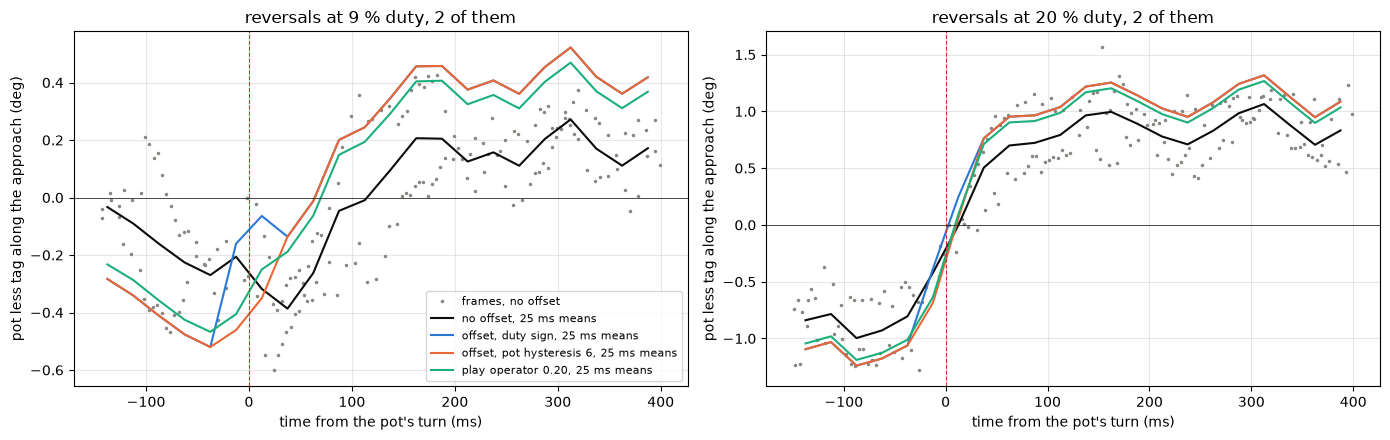

In [62]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
styles = (("q_raw", INK, "no offset"), ("q_duty", BLUE, "offset, duty sign"),
          ("q_pot6", ORANGE, "offset, pot hysteresis 6"),
          ("q_play", GREEN, "play operator 0.20"))
for a, (dp, g) in zip(ax, RV.groupby("duty_pct")):
    w = g[(g["tms"] > -150) & (g["tms"] < 400)]
    a.plot(w["tms"], w["q_raw"], ".", ms=3, color=MUTED,
           label="frames, no offset")
    for c, color, lab in styles:
        mm = w.groupby(pd.cut(w["tms"], np.arange(-150, 401, 25)),
                       observed=True)[c].mean()
        a.plot([i.mid for i in mm.index], mm.values, "-", color=color,
               label=lab + ", 25 ms means")
    a.axvline(0, **figures.HIGHLIGHT_STYLE)
    a.axhline(0, color=INK, lw=0.5)
    figures.label(a, x="time from the pot's turn (ms)",
                  y="pot less tag along the approach (deg)",
                  title=f"reversals at {dp:.0f} % duty, "
                  f"{g.groupby(['k', 'gd']).ngroups} of them")
ax[0].legend(fontsize=8)
figures.finish(fig)

What the figure shows. The pot less the tag along the approach direction against the time from the pot's turn, each frame in gray and 25 ms means of each reading in color, the two 9 % reversals on the left and the two 20 % ones on the right. The red line is the pot's turn. Before it the pot reads behind the horn, after it the sign changes over about 100 ms, and at 9 % the crawl's offset makes the error larger on both sides of the turn whichever source switches it.

### The two analyses side by side

The grade in section 3 controlled the same term for position over every clip kind, with the lead applied and each frame through the counts lookup. The row analysis here holds the crawl clips' offset against the other clips and the rests. Their numbers together.

In [63]:
cf = CONFOUND
print(f"position controlled, all kinds: contrast in bins "
      f"{cf.loc['all', 'odd_half_deg']:+.3f} +/- "
      f"{cf.loc['all', 'se_odd']:.3f} deg over "
      f"{cf.loc['all', 'bins_both_dirs']} bins; h "
      f"{cf.loc['all', 'h_deg']:+.3f} +/- {cf.loc['all', 'se_h']:.3f} deg, "
      f"tau {cf.loc['all', 'tau_ms']:+.1f} +/- {cf.loc['all', 'se_tau']:.1f}"
      " ms")
print(f"position controlled, crawl: contrast "
      f"{cf.loc['crawl', 'odd_half_deg']:+.3f} +/- "
      f"{cf.loc['crawl', 'se_odd']:.3f} deg over "
      f"{cf.loc['crawl', 'bins_both_dirs']} bins; h "
      f"{cf.loc['crawl', 'h_deg']:+.3f} +/- {cf.loc['crawl', 'se_h']:.3f}")
crawl_clips = CLIPS3[CLIPS3["clip"].str.startswith("crawl")]["hold_rs"]
all_clips = CLIPS3["hold_rs"].dropna()
print(f"row by row: crawl offset {PLUS:+.3f} / {MINUS:+.3f} deg; hold "
      f"means by clip {all_clips.min():+.2f} to {all_clips.max():+.2f} "
      f"(crawl clips {crawl_clips.min():+.2f} to {crawl_clips.max():+.2f})"
      f"; at rest {REST_SPLIT[0]:+.3f} +/- {REST_SPLIT[1]:.3f} deg")
bound_move = round(float(crawl_clips.abs().max()), 1)   # deg, clip means
bound_rest = round(abs(REST_SPLIT[0]) + 2 * RC["rs"].std(), 1)
print(f"bounds: max |crawl clip mean| {crawl_clips.abs().max():.3f} -> "
      f"{bound_move:.1f} deg in motion; |rest mean| + 2 sd "
      f"{abs(REST_SPLIT[0]) + 2 * RC['rs'].std():.3f} -> {bound_rest:.1f} "
      "deg at rest")

position controlled, all kinds: contrast in bins -0.055 +/- 0.048 deg over 11 bins; h +0.192 +/- 0.046 deg, tau -5.9 +/- 0.9 ms
position controlled, crawl: contrast +0.019 +/- 0.040 deg over 3 bins; h +0.136 +/- 0.041
row by row: crawl offset +0.274 / -0.227 deg; hold means by clip -0.70 to +0.53 (crawl clips -0.19 to +0.53); at rest -0.053 +/- 0.023 deg
bounds: max |crawl clip mean| 0.528 -> 0.5 deg in motion; |rest mean| + 2 sd 0.319 -> 0.3 deg at rest


1. What the term is, three readings that this data does not separate. (a) An angle, where the horn sits in the play during steady motion, which changed between crawl-1-1 and crawl-2-0 and relaxes at rest. Moderate confidence, since the clip values agree better as angles than as times, the slow reversal shows the term at zero speed, and one common time of -2.63 ms fits every hold once each clip has its own angle. (b) The stamps. The clip value follows the lead stage 3 applied, a correlation of 0.78 over the crawl clips and a coefficient of 1.18 +/- 0.27 on the lead times the speed. Moderate to low confidence, since it needs a timing error several times the 4 ms floor. (c) Both. The two fits leave 0.095 and 0.100 degrees, and the holds alone do not tell them apart. Section 3's position-controlled read points the same way. Over every kind the contrast inside the bins is -0.055 +/- 0.048 degrees, nothing, while a speed-free half width of +0.192 and a timing slope of -5.9 ms fit the same frames.
2. The fixed offset does not generalize. The term is +0.281 to +0.528 degrees in four crawl clips and -0.134 and -0.194 in the two after them, -0.142 in the steps and -0.441 in the reversal, and -0.053 +/- 0.023 at rest. The crawl's pair raises the error on every kind and duty outside the crawl, up to about double. Confidence is high that one fixed pair is not a property of the train a firmware can carry.
3. If a term is ever carried, its direction source is the pot's own motion with 4 to 6 counts of hysteresis, 0 to 8.4 ms late at a reversal. The duty's sign leads the horn by 8 to 21 ms at an open-loop reversal and dithers in a closed loop. The play operator is the smoother form of the same thing and scores about the same.
4. The verdict. The direction term is a stated bound of the position reading, not a term to carry. By direction the pot reads within +/-0.5 degrees of the horn in motion, the crawl clips' means running -0.194 to +0.528, and within about 0.3 degrees at rest, -0.053 on average with an sd of 0.133. Stage 3's hand rock puts the physical ceiling at 1.12 degrees of play. Confidence is high that the fixed offset should not ship and moderate for the bound's size, from one sitting with the tag's 4 ms. The capture that separates an angle in the play from the stamps is the first gap at the end.

## 9. What stage 5 reads from here

One table for the position loop's feedback. Each row names what the data asks of a firmware, meaning the state an estimator keeps, the constants it reads, the rate it runs at, and what it leaves.

In [64]:
fold_d = G[(G["split"] == "twofold") & G["test"].isin(["fold0", "fold1"])
           & (G["pos"] == "pos_cam")].set_index(["test", "level"])
pool = G[(G["test"] == "pooled")].set_index(["pos", "level"])
TERM = pool.loc[("pos_cam", "seg_out")]         # the table's own term
LEAD = pool.loc[("pos_cam", "raw")]             # lead applied, nothing out
NOLEAD = pool.loc[("pos", "raw")]               # nothing done
DIROUT = pool.loc[("pos_cam", "dir_out")]
b16 = FILTERS.set_index("filter").loc["boxcar 16"]
fl = FILTERS.set_index("filter")
late = 0.0 - EVENTS[["early_pot4", "early_pot6"]].to_numpy()  # ms late
spans = ", ".join(f"{b:.2f} deg at {c}" for c, b in zip(CAR, BLIND))
STAGE5 = [
    ("lookup", f"{len(KNOTS)} angles at counts {KNOTS[0]:.0f}, "
     f"{KNOTS[0] + PITCH:.0f}, ... {KNOTS[-1]:.0f}, linear between them; "
     f"index = counts shifted by {int(np.log2(PITCH))}",
     "stateless, no delay, every tick"),
    ("bias, table term", f"{TERM['rms_deg']:.3f} deg rms held out, segment"
     f" offsets out; bins {BS_OUT['mean'].min():+.2f} to "
     f"{BS_OUT['mean'].max():+.2f} deg", "the 32 count lookup"),
    ("bias, nothing out", f"{LEAD['rms_deg']:.2f} deg rms with the stamp "
     f"lead applied, {NOLEAD['rms_deg']:.2f} without; bins "
     f"{BN['mean_deg'].min():+.2f} to {BN['mean_deg'].max():+.2f} deg",
     "the lead is the capture tool's"),
    ("bias, end lines", f"{ENDS.loc['low', 'rms_pinned_deg']:.2f} / "
     f"{ENDS.loc['high', 'rms_pinned_deg']:.2f} deg rms on the start "
     f"points, low / high", f"the high end across a hole of {HOLE[1]:.1f} deg"),
    ("bias by direction", f"within +/-{bound_move:.1f} deg in motion, "
     f"about {bound_rest:.1f} deg at rest", "a bound, not carried"),
    ("noise per tick", f"{INFO['baseline']['sd']:.3f} counts sd "
     f"({INFO['baseline']['sd'] / SCALE:.3f} deg), a 16-tick pattern of "
     f"{INFO['baseline']['pp16']:.2f} counts pp", "the board's"),
]
print(len(STAGE5), "rows so far")

6 rows so far


In [65]:
STAGE5 += [
    ("filter, proposed", f"boxcar 16: {b16['rest_baseline_counts']:.3f} "
     f"counts ({b16['rest_deg']:.3f} deg) at rest, "
     f"{b16['delay_ticks']:.1f} ticks of delay, "
     f"{b16['lag_pass_deg']:.3f} deg behind at {V_PASS:.1f} deg/s",
     "state: the last 16 rows"),
    ("delay per filter", "; ".join(
        f"{n} at {fl.loc[n, 'delay_ticks']:g} ticks, "
        f"{fl.loc[n, 'rest_baseline_counts']:.3f} counts"
        for n in ("boxcar 8", "boxcar 40", "one-pole 20", "one-pole 40")),
     "every candidate in filters.csv"),
    ("carries", f"blind over {spans}", "no mask for position"),
    ("valid range", f"lookup {KNOTS[0]:.0f} to {KNOTS[-1]:.0f} counts, "
     f"fitted {LK.c[0]:.0f} to {LK.c[-1]:.0f}, the crawl's coverage "
     f"{INT[0]:.0f} to {INT[1]:.0f}", "past the start points no data"),
    ("start-up", "the lookup none; the boxcar reads the mean of the rows "
     f"it has until it holds 16, {16 * DT * 1e3:.2f} ms", "every tick"),
    ("direction source, if ever", f"the pot's own motion, 4 to 6 counts of"
     f" hysteresis, {late.min():.0f} to {late.max():.1f} ms late at a "
     "reversal", "not the duty's sign"),
]
lines = ["| quantity | value | note |", "|---|---|---|"]
lines += [f"| {a} | {b} | {c} |" for a, b, c in STAGE5]
print(len(STAGE5), "rows")
display(Markdown("\n".join(lines)))

12 rows


| quantity | value | note |
|---|---|---|
| lookup | 98 angles at counts 384, 416, ... 3488, linear between them; index = counts shifted by 5 | stateless, no delay, every tick |
| bias, table term | 0.165 deg rms held out, segment offsets out; bins -0.09 to +0.18 deg | the 32 count lookup |
| bias, nothing out | 0.41 deg rms with the stamp lead applied, 0.57 without; bins -0.37 to +0.24 deg | the lead is the capture tool's |
| bias, end lines | 0.33 / 0.39 deg rms on the start points, low / high | the high end across a hole of 8.0 deg |
| bias by direction | within +/-0.5 deg in motion, about 0.3 deg at rest | a bound, not carried |
| noise per tick | 1.031 counts sd (0.055 deg), a 16-tick pattern of 3.01 counts pp | the board's |
| filter, proposed | boxcar 16: 0.139 counts (0.007 deg) at rest, 7.5 ticks of delay, 0.038 deg behind at 101.5 deg/s | state: the last 16 rows |
| delay per filter | boxcar 8 at 3.5 ticks, 0.254 counts; boxcar 40 at 19.5 ticks, 0.098 counts; one-pole 20 at 20 ticks, 0.110 counts; one-pole 40 at 40 ticks, 0.074 counts | every candidate in filters.csv |
| carries | blind over 0.77 deg at 1023, 0.14 deg at 1279, 0.47 deg at 2047, 0.03 deg at 2303, 0.28 deg at 2559 | no mask for position |
| valid range | lookup 384 to 3488 counts, fitted 576 to 3200, the crawl's coverage 790 to 2952 | past the start points no data |
| start-up | the lookup none; the boxcar reads the mean of the rows it has until it holds 16, 0.80 ms | every tick |
| direction source, if ever | the pot's own motion, 4 to 6 counts of hysteresis, 0 to 8.4 ms late at a reversal | not the duty's sign |

The lookup is the table of record for stage 4, knots uniform in counts at 32, linear between them, with the end lines carried as knots to the guards. Stage 3's spline stays stage 3's table, and this notebook does not change it. The filter in the table is the proposal for the position loop's feedback, since it nulls the board's 16-tick pattern, and the filter table beside the result file is the deliverable stage 5 picks from. Each estimator runs every tick at the control rate in float. The lookup reads its 98 values and keeps no state. The boxcar keeps its last 16 rows. A direction source, if one is ever carried, keeps its sign and the extremes since its last flip.

In [66]:
GAPS = [
    "The direction term: crawl segments in both directions over the same "
    "span, each direction started from both ends, with a marker driven from "
    "the PWM timer in the camera's view so the stamp lead is measured",
    "The high end: rest points every 2 deg from -30 to -16 deg, or one slow "
    "pass that runs to the guard",
    "The carries outside the covered codes: one slow pass guard to guard",
    "Between sittings: the opening pass and 20 rest points repeated in a "
    "second sitting, graded through this lookup",
    "Temperature: rest points at two bed temperatures on the heated rig",
    "Side load and torque: the load ladder's holds with the tag in view",
    "Wear of the track: the between-sittings capture repeated over the "
    "servo's running life",
]
print("\n".join("- " + g for g in GAPS))

- The direction term: crawl segments in both directions over the same span, each direction started from both ends, with a marker driven from the PWM timer in the camera's view so the stamp lead is measured
- The high end: rest points every 2 deg from -30 to -16 deg, or one slow pass that runs to the guard
- The carries outside the covered codes: one slow pass guard to guard
- Between sittings: the opening pass and 20 rest points repeated in a second sitting, graded through this lookup
- Temperature: rest points at two bed temperatures on the heated rig
- Side load and torque: the load ladder's holds with the tag in view
- Wear of the track: the between-sittings capture repeated over the servo's running life


### The gaps, each with the capture that closes it

1. The direction term. The offset fits inside the crawl clips, changes sign between clips, and the data does not separate an angle in the play from the stamps. Both analyses name the same capture. Crawl segments in both directions over the same span, each direction started from both ends, with a marker driven from the PWM timer in the camera's view, an LED on the timer, so the stamp lead is measured rather than fitted. Then the contrast inside a bin is the play by construction and the slope on the speed is the timing. The same capture settles the steps' opposite sign of section 3 and the grade at speed, which the stamp lead bounds today.
2. The high end. The hole of 7.97 degrees between the data and the start points, and the two end lines that differ by up to 1.12 degrees across it, 21.33 pinned against 22.90 free. Rest points every 2 degrees from -30 to -16 degrees, or one slow pass that runs to the guard, fill the hole and decide between one line and a bend. Until then the high end line is a gap, not a result.
3. The carries outside the covered codes. Steady motion covered codes 620 to 3111 only, so carries at 511, 3327 or 3583 are untested. One slow pass from guard to guard covers them.
4. Between sittings. One sitting bounds nothing across a power cycle, a re-mount or a day. The opening pass and 20 rest points repeated in a second sitting, graded through this lookup, give the first number.
5. Temperature. One ambient over 14.5 minutes. Rest points at two bed temperatures on the heated rig give the slope.
6. Side load and torque. Every frame here is the bare tag horn. The load ladder's holds with the tag in view give the pot's bias against a known torque.
7. Wear of the track. No data. The between-sittings capture repeated over the servo's running life would track it.

### Open discrepancies and what would separate their causes

1. The steps and the reversal against the crawl by direction. With the lead applied the crawl reads the pot ahead along the motion and the steps and the slow reversal read it behind, while with no lead the steps and the reversal sit at zero and the crawl at +/-0.47. Row by row, the term changes sign between crawl clips and follows the lead stage 3 fitted per clip, a correlation of 0.78. The candidates are an angle in the play, the stamps, or both. The first gap's capture separates them.
2. The counts form against the angle form, 0.147 against 0.174 degrees, yet 3.457 against 3.259 counts. The reading is that each minimizes its own unit, at moderate confidence. Fitting the angle form's knots to minimize the error in degrees, offline, separates it from a grid effect. No bench is needed.
3. The high end line, 21.33 pinned against 22.90 free. The second gap's capture separates a bend from a biased cluster of start points.
4. The two-fold against stage 3's. Stage 3 split its chains by the parity of the chain number inside its block and scored each held-out half only over the angles the other half covered, where this notebook splits by the rank inside the clip kind and scores everything inside the fitted knots. Its spline scores 3.167 counts in these folds. The difference is one of method, so no capture is needed.
5. The crawl offset, +0.274 and -0.227 degrees here against stage 3's +0.166 and -0.177. Stage 3's set keeps the kicks and this one keeps the steady holds. Reading the same holds with the kicks in would confirm it, offline.
6. The pot's sd on the load ladder's windows, 1.160 counts pooled here, against stage 3's 0.965 at rest. The windows and the statistic differ, pooled over 55 windows here with one parked on 2047 at 2.807. The per-window median, offline, separates them.
7. The largest carry. Here 1023 is the widest code, 0.772 degrees, and 2047 is 0.467, while stage 3 put 2047 at 0.71 degrees and 1023 at 0.62. Stage 3 scored the horn's travel on each code against the tag, and this notebook scores the code's width in rows. Reading stage 3's per-crossing travel beside the widths, offline, separates the constructions.
8. The baseline and the coast rest points trend opposite ways over the sitting, -2.01 +/- 1.21 and +1.93 +/- 1.09 counts per 10 minutes, each under two sigma. A second sitting's rest points, the fourth gap, would say whether either is real.

## Conclusion

On mg90-d the pot's angle per row is a lookup indexed by counts, knots every 32 counts, linear between them, 98 entries guard to guard with the end lines carried as knots. Held out by fold the table's own term is 0.165 degrees rms with each segment's offset out, 3.399 counts, and the lookup costs nothing against its in-sample fit. With the capture's stamp lead applied and nothing else taken out the grade is 0.410 degrees, and with nothing done 0.568. The stamp lead is the capture tool's and takes 47.9 % of the error's mean square. Nothing finer than 32 counts is resolved by this data, and 64 counts is worse. The low end line is consistent, 22.33 counts per degree. The high end line crosses a hole of 7.97 degrees with no data and is a gap. Inside the sitting no drift is resolved, under 1.7 counts at two sigma over 14.5 minutes.

Row by row the pot scatters by 1.031 counts at rest, two thirds of it a 16-tick pattern that is the board's. A boxcar of 16 rows nulls the pattern and leaves 0.139 counts, 0.007 degrees, for 7.5 ticks of delay, and it is the proposal for the position loop. The carries at 1023, 2047 and 2559 blind the angle over 0.772, 0.467 and 0.279 degrees. A hold over them is 3.5 times worse than doing nothing, so position carries no mask. The direction term fits inside the crawl clips, changes sign between clips, and the data does not separate an angle in the play from the stamps. It is a stated bound, within +/-0.5 degrees in motion and about 0.3 degrees at rest, and not a term to carry.

The result file. Every number in it comes from one sitting on one servo, mg90-d on dev-v006-2A-D, and the load ladder's holds from one more. Each is a candidate until a second sitting repeats it.

In [67]:
q, pm = results.quantity, results.pm
fold_c = fold_d.xs("seg_out", level="level")
fold_raw = fold_d.xs("raw", level="level")
Q1 = TABLE_Q1.set_index(["form", "pitch"])
QUANTITIES = {
    "lookup_pitch_counts": q(PITCH, unit="counts"),
    "lookup_entries_guard_to_guard": q(len(KNOTS), unit="entries"),
    "lookup_entries_data_span": q(LK.entries, unit="entries"),
    "lookup_knot_first_counts": q(KNOTS[0], unit="counts"),
    "lookup_knot_last_counts": q(KNOTS[-1], unit="counts"),
    "table_term_heldout_deg_rms": q(TERM["rms_deg"],
                                    fold_c["rms_deg"].min(),
                                    fold_c["rms_deg"].max(), "deg"),
    "table_term_heldout_counts_rms": q(TERM["rms_counts"],
                                       fold_c["rms_counts"].min(),
                                       fold_c["rms_counts"].max(), "counts"),
    "heldout_lead_applied_deg_rms": q(LEAD["rms_deg"],
                                      fold_raw["rms_deg"].min(),
                                      fold_raw["rms_deg"].max(), "deg"),
    "heldout_lead_applied_counts_rms": q(LEAD["rms_counts"], unit="counts"),
    "heldout_no_lead_deg_rms": q(NOLEAD["rms_deg"], unit="deg"),
    "heldout_direction_means_out_deg_rms": q(DIROUT["rms_deg"], unit="deg"),
    "share_stamp_lead": q(BUDGET["share_lead"], unit="share"),
    "share_direction_means": q(BUDGET["share_dir"], unit="share"),
    "share_segment_wander": q(BUDGET["share_seg"], unit="share"),
    "share_table": q(BUDGET["share_table"], unit="share"),
    "direction_contrast_in_bin_deg": pm(cf.loc["all", "odd_half_deg"],
                                        cf.loc["all", "se_odd"], "deg"),
    "speed_free_half_width_deg": pm(cf.loc["all", "h_deg"],
                                    cf.loc["all", "se_h"], "deg"),
    "timing_slope_ms": pm(cf.loc["all", "tau_ms"], cf.loc["all", "se_tau"],
                          "ms"),
    "lookup_64_counts_heldout_deg_rms": q(Q1.loc[("counts", 64), "cv_deg"],
                                          unit="deg"),
    "angle_form_1p5_deg_heldout_deg_rms": q(
        Q1.loc[("angle", 1.5), "cv_deg"], unit="deg"),
}
print(len(QUANTITIES), "keys")

20 keys


In [68]:
el, eh = ENDS.loc["low"], ENDS.loc["high"]
QUANTITIES.update({
    "end_line_low_counts_per_deg": pm(el["slope_pinned"], el["se_pinned"],
                                      "counts/deg"),
    "end_line_high_counts_per_deg": pm(eh["slope_pinned"], eh["se_pinned"],
                                       "counts/deg"),
    "end_line_high_free_counts_per_deg": pm(eh["slope_free"], eh["se_free"],
                                            "counts/deg"),
    "end_residual_low_deg_rms": q(el["rms_pinned_deg"], el["rms_pinned_deg"],
                                  el["loo_deg"], "deg"),
    "end_residual_high_deg_rms": q(eh["rms_pinned_deg"],
                                   eh["rms_pinned_deg"], eh["loo_deg"],
                                   "deg"),
    "high_end_hole_deg": q(HOLE[1], unit="deg"),
    "rest_level_shift_first_to_last_counts": pm(SHIFT[0], SHIFT[1],
                                                "counts"),
    "rest_trend_counts_per_10min": pm(*TRENDS["all"], "counts per 10 min"),
    "pass_close_minus_open_symmetric_deg": pm(DRIFT["sym"].mean(), SE_BINS,
                                              "deg"),
})
print(len(QUANTITIES), "keys")

29 keys


In [69]:
src = ("baseline", "coast", "ladder")
sds = [INFO[s]["sd"] for s in src]
frees = [INFO[s]["sd_free"] for s in src]
pps = [INFO[s]["pp16"] for s in src] + [STAGE1_PP]
shares = [1 - (INFO[s]["sd_free"] / INFO[s]["sd"]) ** 2 for s in src]
b16_rest = [b16[f"rest_{s}_counts"] for s in src]
QUANTITIES.update({
    "pot_noise_row_counts": q(sds[0], min(sds), max(sds), "counts"),
    "pot_noise_row_pattern_free_counts": q(frees[0], min(frees),
                                           max(frees), "counts"),
    "tick_pattern_period_ticks": q(16, unit="ticks"),
    "tick_pattern_pp_counts": q(pps[0], min(pps), max(pps), "counts"),
    "tick_pattern_variance_share": q(shares[0], min(shares), max(shares),
                                     "share"),
    "filter_boxcar16_noise_counts": q(b16_rest[0], min(b16_rest),
                                      max(b16_rest), "counts"),
    "filter_boxcar16_noise_deg": q(b16["rest_deg"], unit="deg"),
    "filter_boxcar16_delay_ticks": q(b16["delay_ticks"], unit="ticks"),
    "filter_boxcar16_lag_pass_deg": q(b16["lag_pass_deg"], unit="deg"),
    "carry_codes": [int(c) for c in CAR],
    "carry_blind_span_deg": [float(b) for b in BLIND],
    "carry_missing_codes": [int(n) for n in CAR_NM],
    "carry_near_rms_deg": q(slow["near_rms"], unit="deg"),
    "carry_far_rms_deg": q(slow["far_sd"], unit="deg"),
    "carry_hold_near_rms_deg": q(hold["near_rms"], unit="deg"),
    "carry_hold_added_delay_ms": q(np.median(DWELL["slow"]), None,
                                   np.max(DWELL["slow"]), "ms"),
})
print(len(QUANTITIES), "keys")

45 keys


In [70]:
fo = FOLDS3[FOLDS3["source"] == "none"]
QUANTITIES.update({
    "direction_offset_crawl_plus_deg": q(PLUS, fo["plus"].min(),
                                         fo["plus"].max(), "deg"),
    "direction_offset_crawl_minus_deg": q(MINUS, fo["minus"].min(),
                                          fo["minus"].max(), "deg"),
    "direction_offset_clip_min_deg": q(crawl_clips.min(), unit="deg"),
    "direction_offset_clip_max_deg": q(crawl_clips.max(), unit="deg"),
    "rest_direction_split_deg": pm(REST_SPLIT[0], REST_SPLIT[1], "deg"),
    "direction_bound_moving_deg": q(bound_move, unit="deg"),
    "direction_bound_rest_deg": q(bound_rest, unit="deg"),
    "direction_source_pot_hysteresis_counts": q(HYST[1], HYST[1], HYST[2],
                                                "counts"),
    "direction_source_late_ms": q(late.max(), late.min(), late.max(), "ms"),
    "stage5_table": [dict(quantity=a, value=b, note=c)
                     for a, b, c in STAGE5],
    "gaps": GAPS,
})
print(len(QUANTITIES), "keys")

56 keys


The notes that define every key.

In [71]:
NOTES = (
    "stage 4 position of mg90-d on dev-v006-2A-D, no capture of its own: "
    "stage 3's pot-table sitting servo-camera-9 through oscnb.potframes "
    "(21 chains, 5 V) and load/ladder-1's still windows. One sitting, one "
    "servo. Lookup: knots every lookup_pitch_counts counts, angle in deg, "
    "linear between, fitted as tag = PWL(pot) + one offset per moving "
    "segment with the rest points at offset 0 and a second-difference "
    "ridge of 0.1; end lines pinned at the last knots, slopes through the "
    "drive starts past the table, carried as knots guard to guard "
    "(results/<pair>.lookup.csv). Held out: two folds by the parity of a "
    "chain's rank in its clip kind; scored on every frame with tag speed "
    "over 2 deg/s inside the table's range; lead = the pot re-read at "
    "host_cam (stage 3's stamp lead per direction group, the capture "
    "tool's); value pooled, bounds the two folds. Shares: the pooled "
    "error's mean square taken out in the order lead, kind-by-direction "
    "means, segment wander, the rest the table's. direction_contrast, "
    "speed_free_half_width, timing_slope: position-controlled reads over "
    "all kinds, +/- bootstrap sd over segments (400 draws, seed 0). "
)

In [72]:
NOTES += (
    "Rows: one per tick; the angle through stage 3's table inverted. Noise "
    "the sd over rest windows (baselines less 4000 rows, still coast tails"
    ", still ladder windows), value the baselines, bounds the three "
    "sources; pattern = mean by tick mod 16, its share 1 - (sd without it "
    "/ sd)^2, pp bounds include stage 1's divider. Filters: noise the rms "
    "over windows of the output's sd from 20 ms in, delay the DC group "
    "delay, lag at the passes' tag speed (results/<pair>.filters.csv). "
    "Carries: codes 3 LSB wide or with 2+ missing after them, blind span "
    "(width - 1) / scale; near / far against the tag with each segment's "
    "far median out; hold +/-12 counts, delay its dwell median and range. "
    "Direction: boxcar 16 less the tag along the motion on steady crawl "
    "holds, value pooled, bounds the two chain-parity folds; clip min/max "
    "over the crawl clips' hold means; rest after a coast by arrival, "
    "+/- se; bounds: max |crawl clip mean| and |rest mean| + 2 sd, each "
    "rounded to 0.1 deg; late ms of the pot source at 4 and 6 counts over "
    "four reversals, value the worst."
)
path = results.write(STAGE, EXPERIMENT, PAIR_DIR, pair=PAIR, notes=NOTES,
                     **QUANTITIES)
written = results.read(STAGE, EXPERIMENT, pair=PAIR)
print("wrote", path, "with", len(QUANTITIES), "keys, capture",
      written["capture"])

wrote stages/4-estimators/position/results/mg90-d__dev-v006-2A-D.json with 56 keys, capture telemetry/mg90-d__dev-v006-2A-D


In [73]:
base = results.path(STAGE, EXPERIMENT, pair=PAIR)
LOOKUP_PATH = base.with_suffix(".lookup.csv")
FILTERS_PATH = base.with_suffix(".filters.csv")
TABLE.to_csv(LOOKUP_PATH, index=False, float_format="%.4f")
FILTERS[["filter", "delay_ticks", "delay_measured_ticks", "delay_ms",
         "rest_baseline_counts", "rest_coast_counts", "rest_ladder_counts",
         "motion_crawl_counts", "motion_pass_counts", "rest_deg",
         "lag_crawl_deg", "lag_pass_deg"]].to_csv(
    FILTERS_PATH, index=False, float_format="%.4f")
for p in (LOOKUP_PATH, FILTERS_PATH):
    back = pd.read_csv(p)
    print(f"wrote {results.rel(p)}: {len(back)} rows, columns "
          f"{', '.join(back.columns)}")
flat = [{"key": k, **v} for k, v in written.items()
        if isinstance(v, dict) and "value" in v]
show(pd.DataFrame(flat), n=None)

wrote stages/4-estimators/position/results/mg90-d__dev-v006-2A-D.lookup.csv: 98 rows, columns counts, angle_deg
wrote stages/4-estimators/position/results/mg90-d__dev-v006-2A-D.filters.csv: 24 rows, columns filter, delay_ticks, delay_measured_ticks, delay_ms, rest_baseline_counts, rest_coast_counts, rest_ladder_counts, motion_crawl_counts, motion_pass_counts, rest_deg, lag_crawl_deg, lag_pass_deg


,key,value,lo,hi,unit
0,lookup_pitch_counts,32.000,NaN,NaN,counts
1,lookup_entries_guard_to_guard,98.000,NaN,NaN,entries
2,lookup_entries_data_span,83.000,NaN,NaN,entries
3,lookup_knot_first_counts,384.000,NaN,NaN,counts
4,lookup_knot_last_counts,3488.000,NaN,NaN,counts
5,table_term_heldout_deg_rms,0.165,0.160,0.170,deg
6,table_term_heldout_counts_rms,3.399,3.377,3.424,counts
7,heldout_lead_applied_deg_rms,0.410,0.376,0.446,deg
8,heldout_lead_applied_counts_rms,7.890,NaN,NaN,counts
9,heldout_no_lead_deg_rms,0.568,NaN,NaN,deg
